# Optimización de capacidad de un sistema WPEB con metaheurísticas

**Sistema WPEB**: viento (**W**ind) + fotovoltaica (**P**V) +
**E**lectrolizador + **B**atería.

Reproducción parcial y extensión mixta continua-discreta de:

> Runzhao Li et al. (2024). *Capacity optimization of a
> wind-photovoltaic-electrolysis-battery (WPEB) hybrid energy system for power and
> hydrogen generation*. International Journal of Hydrogen Energy, 52, 311--333.

El problema es **monoobjetivo**: se minimiza LCOE. NPC y el LCOH definido por esta
tesis se informan como indicadores secundarios y no intervienen en la aptitud.


## 1. Configuracion de la ejecucion

Aqui se decide el presupuesto de computo y se resuelve la ruta del dato horario. Es la
unica celda que hace falta tocar para pasar de una revision rapida al experimento completo.

In [1]:
import math
import time
from dataclasses import dataclass, field, fields, is_dataclass, replace
from enum import IntEnum
from itertools import combinations
import zlib
from pathlib import Path
from typing import NamedTuple, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from IPython.display import Markdown, display

# --------------------------------------------------------------------------
# PRESUPUESTO DE COMPUTO. Cambiar esta linea es lo unico necesario para pasar
# de la revision rapida al experimento completo del trabajo.
# --------------------------------------------------------------------------
MODO = "completo"          # "rapido" | "completo"

PRESUPUESTOS = {
    # semillas, individuos, iteraciones
    "rapido":   {"n_seeds": 3,  "population": 8,  "iterations": 8},
    "completo": {"n_seeds": 30, "population": 20, "iterations": 30},
}
if MODO not in PRESUPUESTOS:
    raise ValueError("MODO debe ser 'rapido' o 'completo', se recibio {!r}".format(MODO))
PRESUPUESTO = PRESUPUESTOS[MODO]

ALGORITMOS = ("gwo", "pso", "ga", "sho", "woa", "random")

# --------------------------------------------------------------------------
# Ruta del dato horario. Funciona tanto si el notebook se abre desde su propia
# carpeta como desde la raiz del repositorio.
# --------------------------------------------------------------------------
CWD = Path.cwd().resolve()
for candidate in (CWD, CWD / "notebooks", CWD.parent):
    if (candidate / "src" / "hourly_2008.csv").exists():
        NOTEBOOK_DIR = candidate
        break
else:
    raise FileNotFoundError(
        "No encuentro src/hourly_2008.csv. El notebook espera esta estructura:\n"
        "  H2_HRES_trabajo.ipynb\n"
        "  src/hourly_2008.csv"
    )
HOURLY_PATH = NOTEBOOK_DIR / "src" / "hourly_2008.csv"

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

evaluaciones_por_corrida = PRESUPUESTO["population"] * PRESUPUESTO["iterations"]
evaluaciones_totales = evaluaciones_por_corrida * PRESUPUESTO["n_seeds"] * len(ALGORITMOS)

print("Dato horario      :", HOURLY_PATH)
print("Modo              :", MODO)
print("Presupuesto       : {} semillas x {} individuos x {} iteraciones".format(
    PRESUPUESTO["n_seeds"], PRESUPUESTO["population"], PRESUPUESTO["iterations"]))
print("Evaluaciones/corrida:", evaluaciones_por_corrida)
print("Evaluaciones totales:", evaluaciones_totales, "({} algoritmos)".format(len(ALGORITMOS)))
print("Tiempo estimado comparativa: ~{:.0f} s".format(evaluaciones_totales * 0.007))

Dato horario      : C:\Users\Luciano\Documents\GitHub\H2-HRES-METAHEURISTICS-METHODS\notebooks\src\hourly_2008.csv
Modo              : completo
Presupuesto       : 30 semillas x 20 individuos x 30 iteraciones
Evaluaciones/corrida: 600
Evaluaciones totales: 108000 (6 algoritmos)
Tiempo estimado comparativa: ~756 s


## 2. Configuracion del escenario

Todo parametro fisico, economico y de restriccion vive en dataclasses congeladas
(`frozen=True`) con validacion en `__post_init__`. No hay diccionarios sueltos ni claves
magicas: una clave mal escrita falla al construir el escenario, no dentro del bucle de
optimizacion.

Las propiedades derivadas (`specific_consumption_kwh_per_kg`, `electrolyzer_max_mw`,
`eta_charge`) se calculan a partir de los parametros base para que no puedan
desincronizarse entre el modelo base y el extendido.

Los valores por defecto son **los del paper**: Damao Banner (Baotou, Mongolia Interior),
200 MW de generacion renovable, AGSR <= 20%, horizonte de 25 anos y tasa real de 4.35%.

In [2]:
class ConfigError(ValueError):
    """Error de configuracion: clave desconocida, tipo o rango invalido."""


@dataclass(frozen=True)
class SiteConfig:
    """Emplazamiento y ventana temporal. Por defecto, el sitio del paper."""

    lat: float = 41.70
    lon: float = 110.43
    start_year: int = 2001
    end_year: int = 2021
    analysis_year: Optional[int] = 2008

    # NASA POWER entrega los datos en UTC, pero la complementariedad viento-solar
    # se mide por dia solar local. Damao Banner esta en UTC+8.
    utc_offset_hours: float = 8.0

    def __post_init__(self):
        if not -90.0 <= self.lat <= 90.0:
            raise ConfigError("lat fuera de rango [-90, 90]: " + str(self.lat))
        if not -180.0 <= self.lon <= 180.0:
            raise ConfigError("lon fuera de rango [-180, 180]: " + str(self.lon))
        if self.start_year > self.end_year:
            raise ConfigError("start_year > end_year")


@dataclass(frozen=True)
class WindConfig:
    """Turbina y recurso eolico.

    La curva de potencia es cubica simplificada entre cut-in y velocidad nominal.

    ``wind_speed_source`` elige que serie alimenta la curva:

    - ``"measured_50m"``: WS50M tal como la mide NASA POWER.
    - ``"hub_height"``: WSC, corregida a ``hub_height_m``.

    ``measured_50m`` define la reconstruccion principal y ``hub_height`` una sensibilidad.
    La eleccion no se calibra contra el LCOE publicado: el articulo declara un buje a 105 m,
    pero no publica la curva real ni las perdidas de estela necesarias para reproducirlo.
    """

    turbine_rated_mw: float = 5.0
    cut_in_ms: float = 2.5
    rated_ms: float = 10.5
    cut_out_ms: float = 25.0
    hub_height_m: float = 105.0          # Tabla 3 del paper
    wind_speed_source: str = "measured_50m"

    def __post_init__(self):
        if self.turbine_rated_mw <= 0:
            raise ConfigError("turbine_rated_mw debe ser > 0")
        if not self.cut_in_ms < self.rated_ms < self.cut_out_ms:
            raise ConfigError(
                "la curva de potencia exige cut_in < rated < cut_out, se recibio "
                "{} / {} / {}".format(self.cut_in_ms, self.rated_ms, self.cut_out_ms)
            )
        if self.wind_speed_source not in ("measured_50m", "hub_height"):
            raise ConfigError(
                "wind_speed_source debe ser 'measured_50m' o 'hub_height': "
                + str(self.wind_speed_source)
            )


@dataclass(frozen=True)
class PVConfig:
    """Modelo fotovoltaico horario: GHI, derating y correccion termica tipo NOCT.

    ``dc_ac_ratio`` = 1.2 porque el campo tiene mas modulos que la potencia nominal del
    inversor (Tabla 3 del paper: 96.15 MW DC para 80 MW AC). El exceso se recorta en el
    inversor -- *clipping* -- lo que aumenta la produccion en horas de irradiancia media
    sin superar nunca la capacidad AC.
    """

    dc_ac_ratio: float = 1.2
    temp_coeff_pct_per_c: float = -0.5
    noct_c: float = 47.0
    stc_efficiency_pct: float = 13.0
    derating_factor: float = 0.90

    def __post_init__(self):
        if self.dc_ac_ratio <= 0:
            raise ConfigError("dc_ac_ratio debe ser > 0")
        if self.temp_coeff_pct_per_c > 0:
            raise ConfigError("temp_coeff_pct_per_c debe ser <= 0")
        if not 0.0 < self.derating_factor <= 1.0:
            raise ConfigError("derating_factor debe estar en (0, 1]")


@dataclass(frozen=True)
class BatteryConfig:
    """Bateria: eficiencia, dimensionamiento base y malla discreta de la extension.

    En el **modelo base** la potencia es un porcentaje fijo de la del electrolizador,
    redondeado hacia arriba al tamano de pack disponible. Los tres casos publicados lo
    confirman: 0.30*95 = 28.5 -> B30, 0.30*80 = 24 -> B25, 0.30*85 = 25.5 -> B27.5, de
    donde sale el paso de 2.5 MW.

    En la **extension discreta** la potencia y la duracion son variables de decision.
    """

    roundtrip_efficiency: float = 0.90

    # Modelo base
    power_ratio_to_electrolyzer: float = 0.30
    power_rounding_step_mw: float = 2.5
    duration_h: float = 1.0

    # Extension discreta
    power_step_mw: float = 5.0
    power_min_mw: float = 0.0
    power_max_mw: float = 50.0
    duration_candidates_h: Tuple[float, ...] = (1.0, 2.0, 4.0)

    def __post_init__(self):
        if not 0.0 < self.roundtrip_efficiency <= 1.0:
            raise ConfigError("roundtrip_efficiency debe estar en (0, 1]")
        if self.power_rounding_step_mw <= 0 or self.power_step_mw <= 0:
            raise ConfigError("los pasos de potencia deben ser > 0")
        if self.power_min_mw > self.power_max_mw:
            raise ConfigError("power_min_mw > power_max_mw")
        if not self.duration_candidates_h:
            raise ConfigError("duration_candidates_h no puede estar vacio")
        if any(d <= 0 for d in self.duration_candidates_h):
            raise ConfigError("duration_candidates_h debe contener valores > 0")
        # Tupla para que la dataclass congelada siga siendo hasheable.
        object.__setattr__(
            self, "duration_candidates_h",
            tuple(float(d) for d in self.duration_candidates_h),
        )

    @property
    def eta_charge(self):
        """Eficiencia de carga, repartiendo el roundtrip simetricamente."""
        return self.roundtrip_efficiency ** 0.5

    @property
    def eta_discharge(self):
        """Eficiencia de descarga, repartiendo el roundtrip simetricamente."""
        return self.roundtrip_efficiency ** 0.5


@dataclass(frozen=True)
class ElectrolyzerConfig:
    """Electrolizador: eficiencia, carga minima y modularidad discreta."""

    efficiency: float = 0.75
    h2_hhv_kwh_per_kg: float = 39.4
    min_load_ratio: float = 0.30

    # Extension discreta: el electrolizador se compra en unidades enteras.
    unit_mw: float = 5.0
    min_units: int = 10   # 50 MW
    max_units: int = 20   # 100 MW

    # Tanque de hidrogeno (Tabla 3 del paper: 1e4 kg). Entra al NPC cotizado por kg;
    # el paper no lo dimensiona dentro del barrido W/P/E/B, asi que es fijo.
    hydrogen_storage_kg: float = 10_000.0

    def __post_init__(self):
        if not 0.0 < self.efficiency <= 1.0:
            raise ConfigError("efficiency debe estar en (0, 1]")
        if not 0.0 <= self.min_load_ratio <= 1.0:
            raise ConfigError("min_load_ratio debe estar en [0, 1]")
        if self.unit_mw <= 0:
            raise ConfigError("unit_mw debe ser > 0")
        if self.min_units > self.max_units:
            raise ConfigError("min_units > max_units")

    @property
    def specific_consumption_kwh_per_kg(self):
        """Consumo especifico de electricidad por kg de H2.

        Derivado, no configurable: con los valores del paper resulta
        39.4 / 0.75 = 52.53 kWh/kg. Que sea una propiedad garantiza que el modelo base
        y el extendido usen exactamente la misma conversion.
        """
        return self.h2_hhv_kwh_per_kg / self.efficiency

    @property
    def min_capacity_mw(self):
        return self.min_units * self.unit_mw

    @property
    def max_capacity_mw(self):
        return self.max_units * self.unit_mw


@dataclass(frozen=True)
class ConverterConfig:
    """Eficiencias de conversion y consumo parasito de la planta.

    El balance de potencia del paper (Eq. 6) contabiliza perdidas de inversor,
    rectificador y bateria mas la carga de planta. La Tabla 3 fija los convertidores
    en 95%. ``plant_load_ratio`` queda en 0.0 porque el paper no publica su valor:
    es un supuesto explicito, no un dato.
    """

    inverter_efficiency: float = 0.95        # PV DC -> AC
    rectifier_efficiency: float = 0.95       # AC -> DC del electrolizador
    bidirectional_efficiency: float = 0.95   # bateria AC <-> DC
    plant_load_ratio: float = 0.0

    def __post_init__(self):
        for name in ("inverter_efficiency", "rectifier_efficiency",
                     "bidirectional_efficiency"):
            if not 0.0 < getattr(self, name) <= 1.0:
                raise ConfigError(name + " debe estar en (0, 1]")
        if not 0.0 <= self.plant_load_ratio < 1.0:
            raise ConfigError("plant_load_ratio debe estar en [0, 1)")


@dataclass(frozen=True)
class EconomicsConfig:
    """Horizonte, descuento y criterio de energia util para el LCOE.

    ``lcoe_energy_basis`` decide el denominador del LCOE: ``electrolyzer_plus_grid``
    cuenta toda la energia util (la que va al electrolizador mas la exportada),
    ``electrolyzer_only`` cuenta solo la del electrolizador. El paper usa la primera.
    """

    project_lifetime_years: int = 25
    real_discount_rate: float = 0.0435
    lcoe_energy_basis: str = "electrolyzer_plus_grid"

    def __post_init__(self):
        if self.project_lifetime_years < 1:
            raise ConfigError("project_lifetime_years debe ser >= 1")
        if self.real_discount_rate <= -1.0:
            raise ConfigError("real_discount_rate debe ser > -1")
        if self.lcoe_energy_basis not in ("electrolyzer_plus_grid", "electrolyzer_only"):
            raise ConfigError(
                "lcoe_energy_basis invalido: " + str(self.lcoe_energy_basis)
            )


@dataclass(frozen=True)
class ConstraintsConfig:
    """Restricciones de diseno del paper."""

    total_generation_capacity_mw: float = 200.0   # Wind + PV, fijo
    agsr_max: float = 0.20                        # ventas a red / generacion renovable
    electrolyzer_ratio_max: float = 0.50          # E <= 50% de (Wind + PV)
    grid_export_limit_mw: Optional[float] = None  # None -> exportacion ilimitada

    def __post_init__(self):
        if self.total_generation_capacity_mw <= 0:
            raise ConfigError("total_generation_capacity_mw debe ser > 0")
        if not 0.0 <= self.agsr_max <= 1.0:
            raise ConfigError("agsr_max debe estar en [0, 1]")
        if not 0.0 < self.electrolyzer_ratio_max <= 1.0:
            raise ConfigError("electrolyzer_ratio_max debe estar en (0, 1]")

    @property
    def electrolyzer_max_mw(self):
        return self.electrolyzer_ratio_max * self.total_generation_capacity_mw


@dataclass(frozen=True)
class SearchConfig:
    """Resolucion del barrido exhaustivo de la instancia base."""

    wind_step_mw: float = 10.0
    electrolyzer_step_mw: float = 5.0

    def __post_init__(self):
        if self.wind_step_mw <= 0 or self.electrolyzer_step_mw <= 0:
            raise ConfigError("los pasos del barrido deben ser > 0")


@dataclass(frozen=True)
class ComponentCost:
    """Costos de un componente, con base de potencia (CNY/kW) y de energia (CNY/kWh).

    La base de energia existe sobre todo para la bateria: si la duracion es variable de
    decision pero no tiene costo por kWh, alargarla es gratis y el optimizador la lleva
    al maximo sin que ese resultado signifique nada.
    """

    capex_cny_per_kw: float = 0.0
    replacement_cny_per_kw: float = 0.0
    om_cny_per_kw_year: float = 0.0
    capex_cny_per_kwh: float = 0.0
    replacement_cny_per_kwh: float = 0.0
    om_cny_per_kwh_year: float = 0.0
    life_years: int = 25

    def __post_init__(self):
        for f in fields(self):
            if f.name != "life_years" and getattr(self, f.name) < 0:
                raise ConfigError(f.name + " debe ser >= 0")
        if self.life_years < 1:
            raise ConfigError("life_years debe ser >= 1")

    @property
    def has_energy_cost(self):
        return (self.capex_cny_per_kwh > 0
                or self.replacement_cny_per_kwh > 0
                or self.om_cny_per_kwh_year > 0)


@dataclass(frozen=True)
class CostConfig:
    """Costos del paper (Tabla 4), en CNY."""

    wind: ComponentCost = field(default_factory=lambda: ComponentCost(
        capex_cny_per_kw=5917.0, replacement_cny_per_kw=0.0,
        om_cny_per_kw_year=40.2, life_years=25))
    pv: ComponentCost = field(default_factory=lambda: ComponentCost(
        capex_cny_per_kw=4633.0, replacement_cny_per_kw=0.0,
        om_cny_per_kw_year=17.6, life_years=25))
    electrolyzer: ComponentCost = field(default_factory=lambda: ComponentCost(
        capex_cny_per_kw=6964.0, replacement_cny_per_kw=5969.14,
        om_cny_per_kw_year=208.92, life_years=15))
    battery: ComponentCost = field(default_factory=lambda: ComponentCost(
        capex_cny_per_kw=2549.0, replacement_cny_per_kw=500.0,
        om_cny_per_kw_year=10.0, life_years=10))

    hydrogen_storage_capex_cny_per_kg: float = 6611.77
    hydrogen_storage_om_cny_per_kg_year: float = 141.68
    hydrogen_storage_life_years: int = 25

    def __post_init__(self):
        if self.hydrogen_storage_capex_cny_per_kg < 0:
            raise ConfigError("hydrogen_storage_capex_cny_per_kg debe ser >= 0")

## 3. Configuracion de las metaheuristicas

Esta es la seccion que hace que la comparativa sea auditable: **cada hiperparametro de
cada algoritmo esta declarado aqui**, fuera del codigo del operador de busqueda. Ningun
algoritmo tiene numeros magicos escondidos en su bucle.

Los valores son los **canonicos de la literatura**, no un ajuste fino a este problema:

- **PSO**: coeficientes de constriccion de Clerc & Kennedy (2002), `chi = 0.729`,
  `c1 = c2 = 1.49445`.
- **GA**: real-coded estandar -- torneo `k = 3`, cruce BLX-alpha, mutacion gaussiana con
  `sigma` igual al 10% del rango de cada variable, elitismo de 2.
- **SHO**: `h_max = 5.0`, el valor de Dhiman & Kumar (2017).
- **WOA**: `b = 1.0` (constante de la espiral), el valor de Mirjalili & Lewis (2016).

Esto importa para leer los resultados: la comparativa **no** debe interpretarse como un
torneo con un favorito afinado. Si se ajustaran los hiperparametros de un algoritmo y no
los de los demas, el ganador seria el que recibio mas atencion, no el mejor metodo.

`population` e `iterations` fijan el **presupuesto de evaluaciones** (`population x
iterations`), identico para los 6 algoritmos. Es la condicion para que la comparacion sea
justa: todos ven exactamente el mismo numero de disenos.

La comparacion de soluciones tambien vive aqui: una solucion factible domina siempre a
una infactible; entre infactibles se minimiza la suma normalizada de violaciones y entre
factibles se minimiza unicamente el LCOE. No se calibra ningun peso de penalizacion.

In [3]:
@dataclass(frozen=True)
class PSOConfig:
    """Hiperparametros del enjambre de particulas.

    Formulacion de **constriccion** de Clerc-Kennedy, no la de peso de inercia clasico:
    ``inertia`` multiplica toda la suma, no solo la velocidad previa, y es lo que
    garantiza convergencia sin necesidad de decaerla con las iteraciones.

        v = chi * (v + c1*r1*(pbest - x) + c2*r2*(gbest - x))
    """

    inertia: float = 0.729              # chi
    cognitive: float = 1.49445          # c1
    social: float = 1.49445             # c2
    velocity_clamp_ratio: float = 0.20  # |v| <= 20% del rango de cada variable

    def __post_init__(self):
        if self.inertia < 0 or self.cognitive < 0 or self.social < 0:
            raise ConfigError("los coeficientes de PSO deben ser >= 0")
        if not 0.0 < self.velocity_clamp_ratio <= 1.0:
            raise ConfigError("velocity_clamp_ratio debe estar en (0, 1]")


@dataclass(frozen=True)
class GAConfig:
    """Hiperparametros del algoritmo genetico de codificacion real."""

    crossover_rate: float = 0.90        # probabilidad de cruzar en vez de clonar
    mutation_rate: float = 0.10         # probabilidad por gen
    mutation_sigma_ratio: float = 0.10  # sigma = 10% del rango de cada variable
    tournament_size: int = 3            # k del torneo
    elite_count: int = 2                # individuos que pasan intactos
    blx_alpha: float = 0.5              # expansion del intervalo en el cruce BLX

    def __post_init__(self):
        if not 0.0 <= self.crossover_rate <= 1.0:
            raise ConfigError("crossover_rate debe estar en [0, 1]")
        if not 0.0 <= self.mutation_rate <= 1.0:
            raise ConfigError("mutation_rate debe estar en [0, 1]")
        if self.mutation_sigma_ratio <= 0:
            raise ConfigError("mutation_sigma_ratio debe ser > 0")
        if self.tournament_size < 2:
            raise ConfigError("tournament_size debe ser >= 2")
        if self.elite_count < 0:
            raise ConfigError("elite_count debe ser >= 0")
        if self.blx_alpha < 0:
            raise ConfigError("blx_alpha debe ser >= 0")


@dataclass(frozen=True)
class SHOConfig:
    """Hiperparametros del Spotted Hyena Optimizer (Dhiman & Kumar, 2017).

    ``h_max`` es el unico hiperparametro de la literatura: el coeficiente ``h`` decae
    linealmente de ``h_max`` a 0 (en GWO el analogo ``a`` decae de 2 a 0). Un rango mas
    ancho da mas exploracion inicial con la misma estructura de encierro.
    """

    h_max: float = 5.0

    def __post_init__(self):
        if self.h_max <= 0:
            raise ConfigError("h_max debe ser > 0")


@dataclass(frozen=True)
class WOAConfig:
    """Hiperparametros del Whale Optimization Algorithm (Mirjalili & Lewis, 2016).

    ``spiral_constant`` (``b`` en el paper) fija la forma de la espiral logaritmica de la
    fase de ataque por burbujas; 1.0 es el valor que usan los autores.
    """

    spiral_constant: float = 1.0

    def __post_init__(self):
        if self.spiral_constant <= 0:
            raise ConfigError("spiral_constant debe ser > 0")


@dataclass(frozen=True)
class MetaheuristicConfig:
    """Presupuesto, reglas de factibilidad y reproducibilidad."""

    population: int = 20
    iterations: int = 30
    seed: int = 42
    pso: PSOConfig = field(default_factory=PSOConfig)
    ga: GAConfig = field(default_factory=GAConfig)
    sho: SHOConfig = field(default_factory=SHOConfig)
    woa: WOAConfig = field(default_factory=WOAConfig)

    def __post_init__(self):
        if self.population < 1:
            raise ConfigError("population debe ser >= 1")
        if self.iterations < 1:
            raise ConfigError("iterations debe ser >= 1")
        if self.ga.elite_count > self.population:
            raise ConfigError("ga.elite_count ({}) no puede superar population ({})".format(
                self.ga.elite_count, self.population))
        if self.ga.tournament_size > self.population:
            raise ConfigError("ga.tournament_size ({}) no puede superar population ({})".format(
                self.ga.tournament_size, self.population))

    @property
    def evaluation_budget(self):
        """Evaluaciones del objetivo por corrida. Identico para los 6 algoritmos."""
        return self.population * self.iterations

## 4. El escenario resuelto

Se arma el `ScenarioConfig` completo con **una sola desviacion** respecto de los valores
del paper, declarada explicitamente:

**Reparto del costo de la bateria entre potencia y energia.** El paper solo cotiza la
bateria por kW (2549 / 500 / 10 CNY/kW de capex / reemplazo / O&M) porque sus tres casos
publicados son todos de 1 h, donde potencia y energia son numericamente iguales y no se
pueden separar. Para que la duracion de la bateria tenga sentido economico como variable
de decision, este escenario reparte esos costos **30% potencia / 70% energia**:

| | por kW | por kWh | suma a 1 h |
|---|---|---|---|
| capex | 764.70 | 1784.30 | **2549.0** |
| reemplazo | 150.0 | 350.0 | **500.0** |
| O&M anual | 3.0 | 7.0 | **10.0** |

A 1 h la suma da exactamente los valores del paper -- el reparto es **NPC-neutro**, de
modo que la validacion contra el paper (seccion 10) y el barrido base (seccion 11), que
usan bateria de 1 h, no se mueven. A mas horas la bateria cuesta mas, que es lo que hace
que el optimo en duracion signifique algo. **Es un supuesto explicito, no un dato del
paper.**

In [4]:
@dataclass(frozen=True)
class ScenarioConfig:
    """Escenario completo: todo lo necesario para reproducir una corrida."""

    name: str = "metaheuristicas"
    description: str = ""
    site: SiteConfig = field(default_factory=SiteConfig)
    wind: WindConfig = field(default_factory=WindConfig)
    pv: PVConfig = field(default_factory=PVConfig)
    battery: BatteryConfig = field(default_factory=BatteryConfig)
    electrolyzer: ElectrolyzerConfig = field(default_factory=ElectrolyzerConfig)
    converter: ConverterConfig = field(default_factory=ConverterConfig)
    economics: EconomicsConfig = field(default_factory=EconomicsConfig)
    constraints: ConstraintsConfig = field(default_factory=ConstraintsConfig)
    search: SearchConfig = field(default_factory=SearchConfig)
    metaheuristic: MetaheuristicConfig = field(default_factory=MetaheuristicConfig)
    costs: CostConfig = field(default_factory=CostConfig)

    def __post_init__(self):
        # Coherencia entre bloques: la malla discreta del electrolizador no puede
        # violar la restriccion E <= ratio_max * (Wind + PV).
        max_discrete = self.electrolyzer.max_capacity_mw
        allowed = self.constraints.electrolyzer_max_mw
        if max_discrete > allowed + 1e-9:
            raise ConfigError(
                "la malla discreta permite hasta {:.1f} MW de electrolizador, pero la "
                "restriccion admite como maximo {:.1f} MW".format(max_discrete, allowed)
            )

    def replace(self, **changes):
        """Copia con cambios, revalidando. Util para los barridos de sensibilidad."""
        return replace(self, **changes)


# Reparto NPC-neutro 30/70 de los costos de bateria del paper (ver celda anterior).
BATERIA_REPARTIDA = ComponentCost(
    capex_cny_per_kw=764.70,        # 2549 * 0.30
    capex_cny_per_kwh=1784.30,      # 2549 * 0.70
    replacement_cny_per_kw=150.0,   # 500 * 0.30
    replacement_cny_per_kwh=350.0,  # 500 * 0.70
    om_cny_per_kw_year=3.0,         # 10 * 0.30
    om_cny_per_kwh_year=7.0,        # 10 * 0.70
    life_years=10,
)

ESCENARIO = ScenarioConfig(
    name="metaheuristicas",
    description=(
        "Extension mixta continua-discreta de Li et al. (2024): capacidad eolica "
        "continua; electrolizador modular, potencia y duracion de bateria discretas."
    ),
    costs=CostConfig(battery=BATERIA_REPARTIDA),
    metaheuristic=MetaheuristicConfig(
        population=PRESUPUESTO["population"],
        iterations=PRESUPUESTO["iterations"],
        seed=42,
    ),
)

SEMILLAS = tuple(range(ESCENARIO.metaheuristic.seed,
                       ESCENARIO.metaheuristic.seed + PRESUPUESTO["n_seeds"]))


def stream_seed(algorithm, replicate_seed):
    """Semilla estable e independiente por pareja algoritmo-replicacion."""
    algorithm_id = zlib.crc32(algorithm.encode("ascii"))
    return int(np.random.SeedSequence([replicate_seed, algorithm_id]).generate_state(1)[0])


def _tabla_config(obj, prefix=""):
    """Aplana una jerarquia de dataclasses a filas (parametro, valor)."""
    rows = []
    for f in fields(obj):
        value = getattr(obj, f.name)
        name = prefix + f.name
        if is_dataclass(value):
            rows.extend(_tabla_config(value, name + "."))
        else:
            rows.append({"parametro": name, "valor": value})
    return rows


print("Escenario :", ESCENARIO.name)
print("Semillas  :", SEMILLAS[0], "..", SEMILLAS[-1], "({} corridas por algoritmo)".format(len(SEMILLAS)))
print("Presupuesto por corrida:", ESCENARIO.metaheuristic.evaluation_budget, "evaluaciones")
print("Consumo especifico del electrolizador: {:.2f} kWh/kg".format(
    ESCENARIO.electrolyzer.specific_consumption_kwh_per_kg))
print("Electrolizador maximo admitido por la restriccion: {:.0f} MW".format(
    ESCENARIO.constraints.electrolyzer_max_mw))

display(pd.DataFrame(_tabla_config(ESCENARIO)))

Escenario : metaheuristicas
Semillas  : 42 .. 71 (30 corridas por algoritmo)
Presupuesto por corrida: 600 evaluaciones
Consumo especifico del electrolizador: 52.53 kWh/kg
Electrolizador maximo admitido por la restriccion: 100 MW


,parametro,valor
0,name,metaheuristicas
1,description,Extension mixta continua-discreta de Li et al....
2,site.lat,41.7
3,site.lon,110.43
4,site.start_year,2001
...,...,...
88,costs.battery.om_cny_per_kwh_year,7.0
89,costs.battery.life_years,10
90,costs.hydrogen_storage_capex_cny_per_kg,6611.77
91,costs.hydrogen_storage_om_cny_per_kg_year,141.68


## 5. Dato horario y horizonte de reproducción

`src/hourly_2008.csv` contiene 8.784 horas de 2008 para las coordenadas aproximadas

\[
(\phi,\lambda)=(41{,}70^\circ\mathrm{N},110{,}43^\circ\mathrm{E}).
\]

Li et al. identifica Damao Banner y declara 8.760 horas, pero no entrega coordenadas ni
explica el tratamiento del año bisiesto. Por ello:

- la **reproducción principal** elimina las 24 marcas del 29 de febrero y usa 8.760 h;
- la serie íntegra de 8.784 h se conserva como **sensibilidad**;
- las coordenadas no se ajustan para acercar los resultados a los valores publicados.

Las columnas provienen de NASA POWER: velocidad a 50 m, velocidad extrapolada a 105 m,
GHI y temperatura a 2 m. La versión exacta disponible queda identificada por el archivo
horario incluido en el repositorio.


In [5]:
hourly_full = pd.read_csv(HOURLY_PATH, parse_dates=["timestamp"])


def remove_february_29(frame):
    """Retira exactamente las 24 horas del 29 de febrero, sin interpolar."""
    timestamp = frame["timestamp"]
    leap_mask = (timestamp.dt.month == 2) & (timestamp.dt.day == 29)
    removed = int(leap_mask.sum())
    if removed != 24:
        raise ValueError("se esperaban 24 horas del 29 de febrero; se encontraron {}".format(removed))
    return frame.loc[~leap_mask].reset_index(drop=True)


hourly = remove_february_29(hourly_full)
assert len(hourly) == 8760 and len(hourly_full) == 8784

print("Horizonte principal   :", len(hourly), "horas")
print("Sensibilidad bisiesta :", len(hourly_full), "horas")
print("Periodo original      :", hourly_full["timestamp"].min(), "->", hourly_full["timestamp"].max())
print("Coordenada aproximada : ({:.2f}, {:.2f})".format(ESCENARIO.site.lat, ESCENARIO.site.lon))
print("Viento medio 50 m     : {:.2f} m/s".format(hourly["ws50m"].mean()))
print("Viento medio 105 m    : {:.2f} m/s".format(hourly["wsc_ms"].mean()))
print("GHI anual (8760 h)    : {:.0f} kWh/m2".format(hourly["ghi_kwh_m2"].sum()))

display(hourly.head())
display(hourly.describe())


Horizonte principal   : 8760 horas
Sensibilidad bisiesta : 8784 horas
Periodo original      : 2008-01-01 00:00:00 -> 2008-12-31 23:00:00
Coordenada aproximada : (41.70, 110.43)
Viento medio 50 m     : 7.09 m/s
Viento medio 105 m    : 8.66 m/s
GHI anual (8760 h)    : 1658 kWh/m2


,timestamp,ws50m,wsc_ms,ghi_kwh_m2,t2m_c
0,2008-01-01 00:00:00,6.14,7.50,0.03135,-21.05
1,2008-01-01 01:00:00,5.36,6.55,0.15425,-17.50
2,2008-01-01 02:00:00,4.43,5.41,0.29367,-14.95
3,2008-01-01 03:00:00,5.87,7.17,0.39755,-11.95
4,2008-01-01 04:00:00,6.20,7.58,0.46900,-10.13


,timestamp,ws50m,wsc_ms,ghi_kwh_m2,t2m_c
count,8760,8760.000000,8760.000000,8760.000000,8760.000000
mean,2008-07-02 07:37:13.972602,7.088970,8.661268,0.189238,3.690124
min,2008-01-01 00:00:00,0.150000,0.180000,0.000000,-31.170000
25%,2008-04-02 05:45:00,4.930000,6.020000,0.000000,-7.432500
50%,2008-07-02 11:30:00,7.100000,8.670000,0.009000,4.435000
75%,2008-10-01 17:15:00,9.122500,11.145000,0.335755,14.940000
max,2008-12-31 23:00:00,18.870000,23.060000,1.062350,33.110000
std,NaN,2.966882,3.624955,0.266689,13.944194


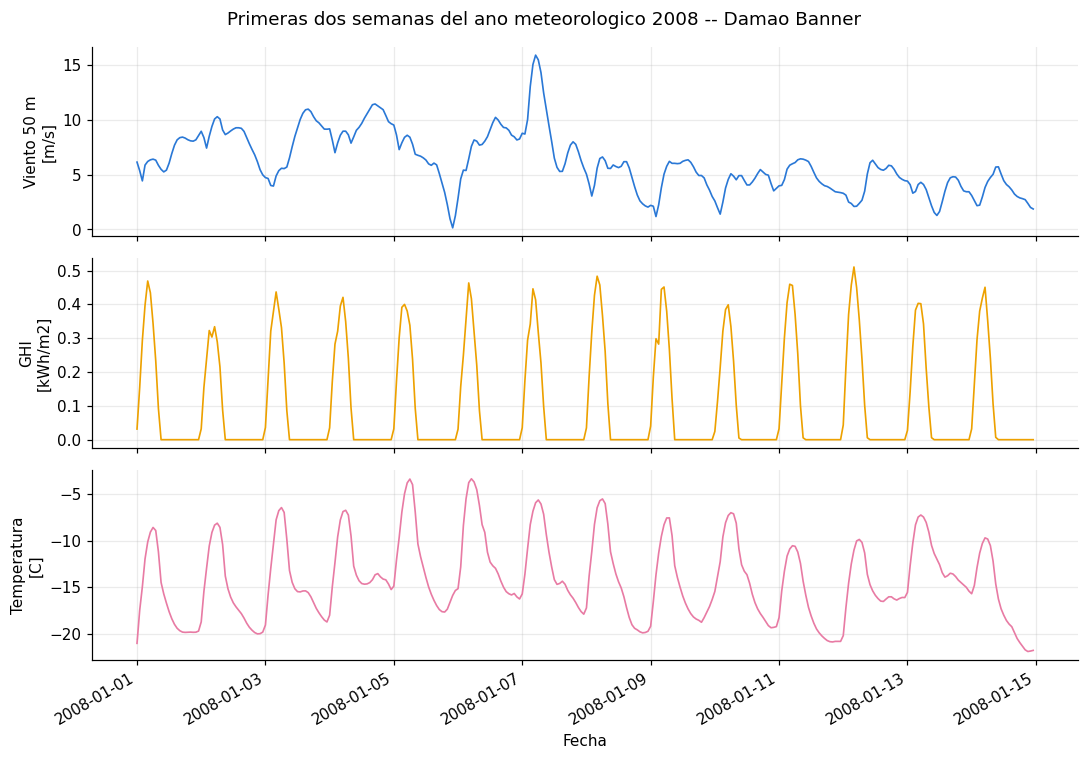

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
muestra = hourly.iloc[:24 * 14]

axes[0].plot(muestra["timestamp"], muestra["ws50m"], color="#2a78d6", lw=1.1)
axes[0].set_ylabel("Viento 50 m\n[m/s]")
axes[1].plot(muestra["timestamp"], muestra["ghi_kwh_m2"], color="#eda100", lw=1.1)
axes[1].set_ylabel("GHI\n[kWh/m2]")
axes[2].plot(muestra["timestamp"], muestra["t2m_c"], color="#e87ba4", lw=1.1)
axes[2].set_ylabel("Temperatura\n[C]")
axes[2].set_xlabel("Fecha")

fig.suptitle("Primeras dos semanas del ano meteorologico 2008 -- Damao Banner")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 6. Modelos de generacion

### Eólica

La variable $W$ representa capacidad agregada continua, no un número fraccionario de
turbinas. Se obtiene primero el perfil por unidad de MW y luego se escala linealmente
por $W$. La curva por unidad es cúbica simplificada, con tres regímenes:

$$P(v) = \begin{cases}
0 & v < v_{ci} \ \text{o} \ v \ge v_{co} \\[4pt]
P_r \dfrac{v^3 - v_{ci}^3}{v_r^3 - v_{ci}^3} & v_{ci} \le v < v_r \\[8pt]
P_r & v_r \le v < v_{co}
\end{cases}$$

El parque son `round(capacidad / 5 MW)` turbinas identicas, y la salida se satura a la
capacidad nominal declarada para que el redondeo hacia arriba no genere mas potencia de
la instalada.

### Fotovoltaica

La GHI horaria en kWh/m2 se interpreta como irradiancia media en kW/m2, de modo que su
valor coincide numericamente con la produccion relativa antes de perdidas. Sobre eso se
aplican el derating (0.90) y la correccion termica tipo NOCT:

$$T_{cell} = T_{amb} + \frac{NOCT - 20}{0.8}\,G \qquad
f_T = 1 + \gamma\,(T_{cell} - 25)$$

La potencia DC se calcula sobre `capacidad_AC x 1.2` y luego se recorta en el inversor,
que es lo que produce el *clipping*.

### Cache de perfiles

`GenerationProfileCache` memoiza los perfiles por capacidad. Sin el, el barrido de la
seccion 11 recalcularia el perfil eolico 420 veces cuando alcanzan 21, y la optimizacion
lo recalcularia en cada una de las 108.000 evaluaciones. **El resultado numerico es
identico**; lo unico que cambia es el tiempo.

In [7]:
def wind_turbine_power_mw(wind_speed_ms, rated_mw, cut_in_ms, rated_ms, cut_out_ms):
    """Potencia de UNA turbina, con curva cubica simplificada."""
    ws = np.asarray(wind_speed_ms, dtype=float)
    p = np.zeros_like(ws, dtype=float)

    ramp = (ws >= cut_in_ms) & (ws < rated_ms)
    plateau = (ws >= rated_ms) & (ws < cut_out_ms)

    p[ramp] = rated_mw * ((ws[ramp] ** 3 - cut_in_ms ** 3)
                          / (rated_ms ** 3 - cut_in_ms ** 3))
    p[plateau] = rated_mw
    return np.clip(p, 0.0, rated_mw)


def aggregate_wind_power_mw(wind_speed_ms, wind_capacity_mw, config):
    """Potencia de un parque agregado continuo, escalada desde un perfil por MW."""
    if wind_capacity_mw < 0:
        raise ValueError("wind_capacity_mw debe ser >= 0")
    per_unit = wind_turbine_power_mw(
        wind_speed_ms,
        rated_mw=1.0,
        cut_in_ms=config.cut_in_ms,
        rated_ms=config.rated_ms,
        cut_out_ms=config.cut_out_ms,
    )
    return per_unit * float(wind_capacity_mw)


def cell_temperature_c(ghi_kwh_m2, ambient_c, config):
    """Temperatura de celda, aproximacion tipo NOCT."""
    ghi = np.asarray(ghi_kwh_m2, dtype=float)
    t_amb = np.asarray(ambient_c, dtype=float)
    return t_amb + (config.noct_c - 20.0) / 0.8 * ghi


def pv_power_mw(ghi_kwh_m2, ambient_c, pv_ac_capacity_mw, config,
                inverter_efficiency=1.0):
    """Potencia AC del campo fotovoltaico, con clipping en el inversor."""
    ghi = np.asarray(ghi_kwh_m2, dtype=float)
    t_cell = cell_temperature_c(ghi, ambient_c, config)

    gamma = config.temp_coeff_pct_per_c / 100.0
    temp_factor = 1.0 + gamma * (t_cell - 25.0)

    relative = ghi * config.derating_factor * np.maximum(temp_factor, 0.0)

    dc_capacity_mw = pv_ac_capacity_mw * config.dc_ac_ratio
    power_dc = dc_capacity_mw * np.maximum(relative, 0.0)
    power_ac = power_dc * inverter_efficiency
    return np.minimum(power_ac, pv_ac_capacity_mw)


HUB_WIND_COLUMN = "wsc_ms"
MEASURED_WIND_COLUMN = "ws50m"
_QUANTUM_MW = 1e-6   # cuantizacion para que 190.0 y 190.0000000001 compartan cache


class GenerationProfileCache:
    """Perfiles horarios de generacion para un ano meteorologico dado."""

    def __init__(self, hourly, config):
        missing = [c for c in ("ghi_kwh_m2", "t2m_c") if c not in hourly.columns]
        if missing:
            raise ValueError("faltan columnas en los datos horarios: {}".format(missing))

        if config.wind.wind_speed_source == "hub_height":
            if HUB_WIND_COLUMN not in hourly.columns:
                raise ValueError(
                    "el escenario pide viento a altura de buje pero falta la columna "
                    + HUB_WIND_COLUMN
                )
            wind_column = HUB_WIND_COLUMN
        else:
            if MEASURED_WIND_COLUMN not in hourly.columns:
                raise ValueError("falta la columna " + MEASURED_WIND_COLUMN)
            wind_column = MEASURED_WIND_COLUMN

        self._config = config
        self._n_hours = len(hourly)
        self._wind_column = wind_column
        self._wind_speed = np.ascontiguousarray(hourly[wind_column].to_numpy(dtype=float))
        self._ghi = np.ascontiguousarray(hourly["ghi_kwh_m2"].to_numpy(dtype=float))
        self._temperature = np.ascontiguousarray(hourly["t2m_c"].to_numpy(dtype=float))

        self._wind_cache = {}
        self._pv_cache = {}
        self._total_cache = {}
        self.hits = 0
        self.misses = 0

    @property
    def n_hours(self):
        return self._n_hours

    @property
    def wind_column(self):
        """Columna de viento efectivamente usada: util para auditar una corrida."""
        return self._wind_column

    @staticmethod
    def _key(capacity_mw):
        return int(round(capacity_mw / _QUANTUM_MW))

    def wind(self, wind_mw):
        key = self._key(wind_mw)
        profile = self._wind_cache.get(key)
        if profile is None:
            profile = aggregate_wind_power_mw(self._wind_speed, wind_mw, self._config.wind)
            self._wind_cache[key] = profile
        return profile

    def pv(self, pv_mw):
        key = self._key(pv_mw)
        profile = self._pv_cache.get(key)
        if profile is None:
            profile = pv_power_mw(
                self._ghi, self._temperature, pv_mw, self._config.pv,
                inverter_efficiency=self._config.converter.inverter_efficiency,
            )
            self._pv_cache[key] = profile
        return profile

    def total(self, wind_mw, pv_mw):
        """Generacion renovable agregada, lista para el despacho."""
        key = (self._key(wind_mw), self._key(pv_mw))
        profile = self._total_cache.get(key)
        if profile is None:
            self.misses += 1
            profile = np.ascontiguousarray(self.wind(wind_mw) + self.pv(pv_mw))
            self._total_cache[key] = profile
        else:
            self.hits += 1
        return profile

    def stats(self):
        return {"hits": self.hits, "misses": self.misses,
                "wind_profiles": len(self._wind_cache),
                "pv_profiles": len(self._pv_cache)}


def as_profile_cache(hourly, config):
    """Acepta indistintamente un DataFrame horario o un cache ya construido."""
    if isinstance(hourly, GenerationProfileCache):
        return hourly
    return GenerationProfileCache(hourly, config)

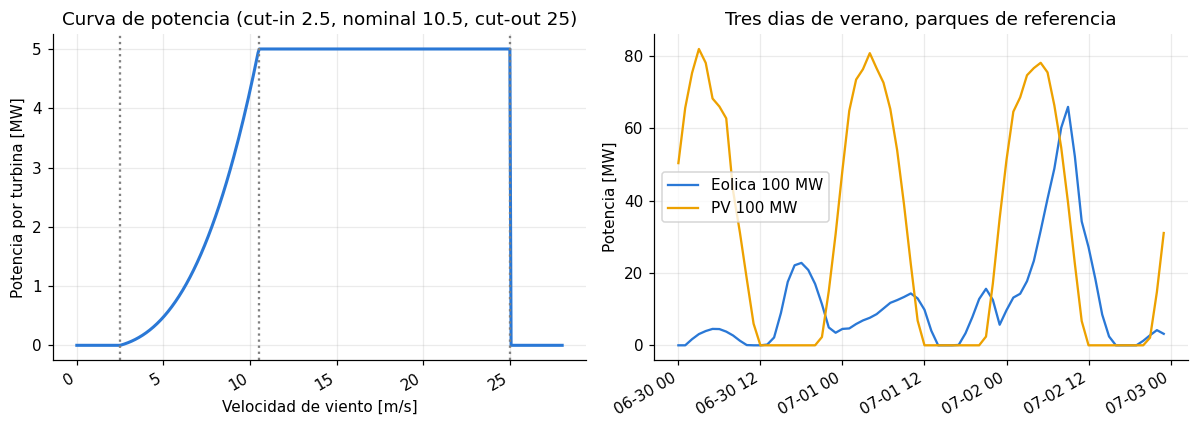

Columna de viento usada : ws50m
CF eolico  (100 MW): 0.3949   (paper: 0.40)
CF fotovoltaico    : 0.1876   (paper: 0.19)


In [8]:
# Curva de potencia de la turbina y factores de capacidad del recurso.
cache_demo = as_profile_cache(hourly, ESCENARIO)
horas = cache_demo.n_hours

cf_wind = float(cache_demo.wind(100.0).sum()) / (100.0 * horas)
cf_pv = float(cache_demo.pv(100.0).sum()) / (100.0 * horas)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

v = np.linspace(0, 28, 400)
axes[0].plot(v, wind_turbine_power_mw(v, 5.0, 2.5, 10.5, 25.0), color="#2a78d6", lw=2)
axes[0].axvline(2.5, ls=":", color="grey"); axes[0].axvline(10.5, ls=":", color="grey")
axes[0].axvline(25.0, ls=":", color="grey")
axes[0].set_xlabel("Velocidad de viento [m/s]")
axes[0].set_ylabel("Potencia por turbina [MW]")
axes[0].set_title("Curva de potencia (cut-in 2.5, nominal 10.5, cut-out 25)")

dia = slice(24 * 180, 24 * 183)
axes[1].plot(hourly["timestamp"].iloc[dia], cache_demo.wind(100.0)[dia],
             label="Eolica 100 MW", color="#2a78d6")
axes[1].plot(hourly["timestamp"].iloc[dia], cache_demo.pv(100.0)[dia],
             label="PV 100 MW", color="#eda100")
axes[1].set_ylabel("Potencia [MW]")
axes[1].set_title("Tres dias de verano, parques de referencia")
axes[1].legend()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

print("Columna de viento usada : {}".format(cache_demo.wind_column))
print("CF eolico  (100 MW): {:.4f}   (paper: 0.40)".format(cf_wind))
print("CF fotovoltaico    : {:.4f}   (paper: 0.19)".format(cf_pv))

## 7. Modelo economico

El criterio es el **NPC** (*Net Present Cost*) y su anualizacion via el factor de
recuperacion de capital:

$$CRF(i, N) = \frac{i\,(1+i)^N}{(1+i)^N - 1}$$

Para cada componente:

$$NPC = C_{capex} + \sum_{y \in \text{reemplazos}} \frac{C_{rep}}{(1+i)^y}
      + \sum_{y=1}^{N} \frac{C_{O\&M}}{(1+i)^y} - S$$

**Valor residual $S$** (metodo lineal de HOMER): si el ultimo reemplazo ocurre antes del
fin del horizonte, al componente le queda vida util sin usar y ese remanente se valora en
proporcion y se descuenta desde el fin del proyecto:

$$S = C_{rep}\,\frac{\text{vida restante}}{\text{vida del componente}}\,\frac{1}{(1+i)^N}$$

Con los datos del paper, el electrolizador (vida 15 anos, reemplazo en el ano 15) llega
al ano 25 con 5 de 15 anos sin usar. La eolica y la PV, cuya vida coincide con el
horizonte, no tienen residual. Ignorar el residual sobreestima el NPC del electrolizador,
que es el componente mas caro despues de la generacion.

Sobre esa base se calculan los dos costos nivelados:

$$LCOE = \frac{NPC \cdot CRF}{E_{util}} \qquad LCOH = \frac{NPC \cdot CRF}{m_{H_2}}$$

In [9]:
def crf(discount_rate, years):
    """Factor de recuperacion de capital.

    Con tasa cero degenera en 1/n, que es el limite analitico y evita dividir por cero.
    """
    if years < 1:
        raise ValueError("years debe ser >= 1")
    if discount_rate == 0.0:
        return 1.0 / years
    growth = (1.0 + discount_rate) ** years
    return (discount_rate * growth) / (growth - 1.0)


def replacement_years(life_years, project_years):
    """Anos en que toca reemplazar dentro del horizonte.

    Un componente de vida 15 en un proyecto de 25 se reemplaza solo en el ano 15:
    el del ano 30 cae fuera del horizonte.
    """
    if life_years < 1:
        raise ValueError("life_years debe ser >= 1")
    return list(range(life_years, project_years, life_years))


def present_value_of_replacements(quantity, cost_per_unit, life_years,
                                  project_years, discount_rate):
    """Valor presente de los reemplazos periodicos."""
    if quantity <= 0 or cost_per_unit <= 0:
        return 0.0
    return sum((quantity * cost_per_unit) / ((1.0 + discount_rate) ** year)
               for year in replacement_years(life_years, project_years))


def present_value_of_om(quantity, om_per_unit_year, project_years, discount_rate):
    """Valor presente de la operacion y mantenimiento anual."""
    if quantity <= 0 or om_per_unit_year <= 0:
        return 0.0
    return sum((quantity * om_per_unit_year) / ((1.0 + discount_rate) ** year)
               for year in range(1, project_years + 1))


def salvage_value(quantity, replacement_cost_per_unit, life_years,
                  project_years, discount_rate):
    """Valor residual al final del horizonte, metodo lineal de HOMER."""
    if quantity <= 0 or replacement_cost_per_unit <= 0:
        return 0.0

    replacements = replacement_years(life_years, project_years)
    if not replacements:
        return 0.0

    last_replacement = replacements[-1]
    remaining_life = life_years - (project_years - last_replacement)
    if remaining_life <= 0:
        return 0.0

    value = quantity * replacement_cost_per_unit * (remaining_life / life_years)
    return value / ((1.0 + discount_rate) ** project_years)


def component_npc(capacity_kw, capacity_kwh, cost, economics):
    """NPC de un componente: capex + reemplazos + O&M - residual.

    Suma la base de potencia y la de energia. Para los componentes del paper la base
    de energia es 0.0, asi que solo contribuye la de potencia; para la bateria de este
    escenario contribuyen las dos.
    """
    rate = economics.real_discount_rate
    horizon = economics.project_lifetime_years

    total = 0.0
    for quantity, capex, replacement, om in (
        (capacity_kw, cost.capex_cny_per_kw, cost.replacement_cny_per_kw,
         cost.om_cny_per_kw_year),
        (capacity_kwh, cost.capex_cny_per_kwh, cost.replacement_cny_per_kwh,
         cost.om_cny_per_kwh_year),
    ):
        if quantity <= 0:
            continue
        total += quantity * capex
        total += present_value_of_replacements(quantity, replacement, cost.life_years,
                                               horizon, rate)
        total += present_value_of_om(quantity, om, horizon, rate)
        total -= salvage_value(quantity, replacement, cost.life_years, horizon, rate)
    return total


def hydrogen_storage_npc(capacity_kg, costs, economics):
    """NPC del almacenamiento de H2, cotizado por kg (Tabla 4 del paper).

    Su vida util coincide con el horizonte, de modo que no tiene reemplazos ni residual.
    """
    if capacity_kg <= 0:
        return 0.0
    return capacity_kg * costs.hydrogen_storage_capex_cny_per_kg + present_value_of_om(
        capacity_kg, costs.hydrogen_storage_om_cny_per_kg_year,
        economics.project_lifetime_years, economics.real_discount_rate,
    )


def npc_from_capacities(wind_mw, pv_mw, electrolyzer_mw, battery_mw, battery_mwh,
                        costs, economics, hydrogen_storage_kg=0.0):
    """NPC del sistema WPEB completo."""
    kw = 1000.0
    return (
        component_npc(wind_mw * kw, 0.0, costs.wind, economics)
        + component_npc(pv_mw * kw, 0.0, costs.pv, economics)
        + component_npc(electrolyzer_mw * kw, 0.0, costs.electrolyzer, economics)
        + component_npc(battery_mw * kw, battery_mwh * kw, costs.battery, economics)
        + hydrogen_storage_npc(hydrogen_storage_kg, costs, economics)
    )


def levelized_cost(annualized_cost_cny, annual_output):
    """Costo nivelado. Infinito si no hay produccion, para que una configuracion
    esteril nunca gane una comparacion por minimo."""
    if annual_output <= 0:
        return float("inf")
    return annualized_cost_cny / annual_output


print("CRF(4.35%, 25 anos) = {:.6f}".format(
    crf(ESCENARIO.economics.real_discount_rate,
        ESCENARIO.economics.project_lifetime_years)))
print("Reemplazos del electrolizador (vida 15, horizonte 25): anos", replacement_years(15, 25))
print("Reemplazos de la bateria      (vida 10, horizonte 25): anos", replacement_years(10, 25))

CRF(4.35%, 25 anos) = 0.066402
Reemplazos del electrolizador (vida 15, horizonte 25): anos [15]
Reemplazos de la bateria      (vida 10, horizonte 25): anos [10, 20]


## 8. Despacho horario y conservación de energía

El despacho se calcula con $\Delta t=1\ \mathrm{h}$. Para cada hora se verifica

\[
P_{\mathrm{ren},t}+P_{\mathrm{desc},t}
=P_{E,t}+P_{\mathrm{carga},t}+P_{\mathrm{red},t}+P_{\mathrm{vert},t}.
\]

La batería se carga antes de exportar. El electrolizador opera solo entre cero y su
potencia nominal; si está encendido debe respetar la carga mínima. `TOP_UP` corresponde
a la reconstrucción base y `THRESHOLD` a la extensión mixta. El residuo del balance se
guarda para comprobar que factibilidad numérica y factibilidad física no se confundan.


In [10]:
class MinLoadPolicy(IntEnum):
    """Regla de operacion del electrolizador bajo la carga minima."""

    TOP_UP = 0     # modelo base
    THRESHOLD = 1  # extension discreta


class DispatchResult(NamedTuple):
    """Series horarias resultantes del despacho, en MW (SOC en MWh)."""

    electrolyzer_load: np.ndarray
    grid_sales: np.ndarray
    battery_charge: np.ndarray
    battery_discharge: np.ndarray
    curtailment: np.ndarray
    state_of_charge: np.ndarray
    balance_residual: np.ndarray


# Cualquier valor negativo del limite de exportacion significa "sin limite".
_NO_GRID_LIMIT = -1.0


def _dispatch_core(generation_mw, electrolyzer_mw, min_load_mw, battery_power_mw,
                   battery_energy_mwh, eta_charge, eta_discharge, policy,
                   grid_export_limit_mw):
    """Bucle secuencial sobre el estado de carga.

    Acumula en listas de Python en vez de arrays de NumPy: evita crear un escalar de
    NumPy por cada una de las 8784 horas, que es lo que domina el costo de esta ruta.
    """
    n = len(generation_mw)

    electrolyzer_load = []
    grid_sales = []
    battery_charge = []
    battery_discharge = []
    curtailment = []
    state_of_charge = []
    balance_residual = []

    soc = 0.0

    for t in range(n):
        generation = generation_mw[t]
        load = 0.0
        discharge = 0.0
        charge = 0.0
        exported = 0.0
        curtailed = 0.0

        if policy == 0:
            # TOP_UP: consumir todo lo posible y completar con bateria si el
            # resultado cae bajo la carga minima.
            load = generation if generation < electrolyzer_mw else electrolyzer_mw
            if 0.0 < load < min_load_mw:
                deficit = min_load_mw - load
                available = soc * eta_discharge
                if battery_power_mw < available:
                    available = battery_power_mw
                discharge = deficit if deficit < available else available
                load += discharge
                if load < min_load_mw:
                    # No se alcanza el minimo: se apaga y se revierte la descarga.
                    load = 0.0
                    discharge = 0.0
        else:
            # THRESHOLD: operar solo si el minimo es alcanzable.
            if generation >= min_load_mw and electrolyzer_mw > 0.0:
                load = generation if generation < electrolyzer_mw else electrolyzer_mw
            elif electrolyzer_mw > 0.0 and battery_power_mw > 0.0 and soc > 0.0:
                available = soc * eta_discharge
                if battery_power_mw < available:
                    available = battery_power_mw
                if generation + available >= min_load_mw:
                    headroom = electrolyzer_mw - generation
                    discharge = available if available < headroom else headroom
                    if discharge < 0.0:
                        discharge = 0.0
                    load = generation + discharge
                    if load > electrolyzer_mw:
                        load = electrolyzer_mw

        if discharge > 0.0:
            soc -= discharge / eta_discharge
            if soc < 0.0:
                soc = 0.0

        surplus = generation + discharge - load
        if surplus < 0.0:
            surplus = 0.0

        # Cargar la bateria con el excedente antes de exportar.
        if surplus > 1e-12 and battery_power_mw > 0.0 and battery_energy_mwh > 0.0:
            room = (battery_energy_mwh - soc) / eta_charge
            if room < 0.0:
                room = 0.0
            charge = surplus if surplus < battery_power_mw else battery_power_mw
            if room < charge:
                charge = room
            if charge > 0.0:
                soc += charge * eta_charge
                surplus -= charge
            else:
                charge = 0.0

        # Exportar el remanente, recortando lo que exceda el limite de conexion.
        if surplus > 1e-12:
            if grid_export_limit_mw < 0.0:
                exported = surplus
            else:
                exported = surplus if surplus < grid_export_limit_mw else grid_export_limit_mw
                curtailed = surplus - exported

        electrolyzer_load.append(load)
        grid_sales.append(exported)
        battery_charge.append(charge)
        battery_discharge.append(discharge)
        curtailment.append(curtailed)
        state_of_charge.append(soc)
        balance_residual.append(
            generation + discharge - load - charge - exported - curtailed
        )

    return (electrolyzer_load, grid_sales, battery_charge,
            battery_discharge, curtailment, state_of_charge, balance_residual)


def dispatch_hourly(generation_mw, electrolyzer_mw, min_load_ratio, battery_power_mw,
                    battery_energy_mwh, eta_charge, eta_discharge,
                    policy=MinLoadPolicy.TOP_UP, grid_export_limit_mw=None):
    """Despacha un ano horario y devuelve las series resultantes."""
    limit = _NO_GRID_LIMIT if grid_export_limit_mw is None else float(grid_export_limit_mw)
    generation = np.asarray(generation_mw, dtype=np.float64).tolist()

    outputs = _dispatch_core(
        generation,
        float(electrolyzer_mw),
        float(min_load_ratio * electrolyzer_mw),
        float(battery_power_mw),
        float(battery_energy_mwh),
        float(eta_charge),
        float(eta_discharge),
        int(policy),
        limit,
    )
    return DispatchResult(*(np.asarray(s, dtype=np.float64) for s in outputs))

## 9. Simulación anual y cinco grupos de restricciones

Dos puntos de entrada sobre un unico nucleo, uno por instancia del problema:

**`simulate_base`** -- replica del paper. Electrolizador continuo, bateria dimensionada
como 30% de su capacidad redondeado al pack comercial de 2.5 MW, duracion 1 h, politica
`TOP_UP`.

**`simulate_mixed`** -- extensión mixta continua-discreta. Electrolizador modular en unidades
enteras de 5 MW, potencia y duracion de bateria como variables de decision, politica
`THRESHOLD`.

Ambos devuelven el mismo `SimulationResult`, de modo que las dos instancias se pueden
comparar en una misma tabla.

**Restricciones.** Antes de simular se chequean cinco condiciones; si alguna falla, no se
simula y el resultado registra el **motivo** del rechazo con LCOE y LCOH en infinito. Que
el motivo quede escrito -- en vez de un `feasible=False` mudo -- es lo que permite
distinguir un diseno que viola la capacidad total de uno que viola el rango discreto.

**AGSR** (*Annual Grid Sales Ratio*) es la restriccion central del paper: la energia
exportada a la red no puede superar el 20% de la generacion renovable total. Es lo que
obliga a que el sistema consuma su propia energia produciendo hidrogeno en vez de
venderla.

In [11]:
@dataclass(frozen=True)
class SimulationResult:
    """Metricas anuales de una configuracion de capacidades."""

    # -- capacidades --------------------------------------------------------
    wind_mw: float
    pv_mw: float
    electrolyzer_mw: float
    n_electrolyzer_units: int
    battery_mw: float
    battery_mwh: float
    battery_duration_h: float

    # -- factibilidad -------------------------------------------------------
    feasible: bool
    agsr: float
    infeasibility_reason: str = ""
    violation_balance: float = 0.0
    violation_capacity: float = 0.0
    violation_electrolyzer: float = 0.0
    violation_operation: float = 0.0
    violation_agsr: float = 0.0
    total_normalized_violation: float = 0.0
    max_balance_residual_mw: float = 0.0

    # -- energia (MWh/ano) --------------------------------------------------
    total_wind_mwh: float = 0.0
    total_pv_mwh: float = 0.0
    total_renewable_mwh: float = 0.0
    total_grid_sales_mwh: float = 0.0
    total_electrolyzer_load_mwh: float = 0.0
    total_curtailment_mwh: float = 0.0
    battery_throughput_mwh: float = 0.0

    # -- desempeno ----------------------------------------------------------
    electrolyzer_cf: float = 0.0
    total_h2_kg: float = 0.0

    # -- economia (CNY) -----------------------------------------------------
    npc_cny: float = 0.0
    annualized_cost_cny: float = 0.0
    lcoe_cny_per_kwh: float = float("inf")
    lcoh_cny_per_kg: float = float("inf")

    def to_dict(self):
        return {f.name: getattr(self, f.name) for f in fields(self)}


def infeasible_result(wind_mw, pv_mw, electrolyzer_mw, n_electrolyzer_units,
                      battery_mw, battery_mwh, battery_duration_h, reason):
    """Resultado nulo para una configuracion que viola una restriccion."""
    return SimulationResult(
        wind_mw=wind_mw, pv_mw=pv_mw, electrolyzer_mw=electrolyzer_mw,
        n_electrolyzer_units=n_electrolyzer_units, battery_mw=battery_mw,
        battery_mwh=battery_mwh, battery_duration_h=battery_duration_h,
        feasible=False, agsr=float("nan"), infeasibility_reason=reason,
        violation_capacity=1.0, total_normalized_violation=1.0,
    )


_CAPACITY_TOLERANCE_MW = 1e-9


def battery_power_for(electrolyzer_mw, config):
    """Potencia de bateria del modelo base, en tamanos de pack comerciales."""
    battery = config.battery
    exact = battery.power_ratio_to_electrolyzer * electrolyzer_mw
    step = battery.power_rounding_step_mw
    # El epsilon evita que un exacto ya alineado a la malla salte un pack por
    # error de coma flotante (25.0 / 2.5 = 9.999...).
    return math.ceil(exact / step - 1e-9) * step


def _check_base_constraints(wind_mw, pv_mw, electrolyzer_mw, config):
    constraints = config.constraints
    total = wind_mw + pv_mw

    if wind_mw < 0 or pv_mw < 0:
        return "capacidad negativa (wind={:.1f}, pv={:.1f})".format(wind_mw, pv_mw)
    if abs(total - constraints.total_generation_capacity_mw) > _CAPACITY_TOLERANCE_MW:
        return "wind+pv={:.3f} MW no respeta la capacidad fija de {:.1f} MW".format(
            total, constraints.total_generation_capacity_mw)
    if electrolyzer_mw <= 0:
        return "electrolizador de capacidad nula"
    if electrolyzer_mw > constraints.electrolyzer_max_mw + _CAPACITY_TOLERANCE_MW:
        return "electrolizador {:.1f} MW supera el maximo de {:.1f} MW".format(
            electrolyzer_mw, constraints.electrolyzer_max_mw)
    return ""


def _check_discrete_constraints(wind_mw, pv_mw, n_units, battery_mw,
                                battery_duration_h, config):
    electrolyzer = config.electrolyzer
    battery = config.battery

    reason = _check_base_constraints(wind_mw, pv_mw, n_units * electrolyzer.unit_mw, config)
    if reason:
        return reason

    if not electrolyzer.min_units <= n_units <= electrolyzer.max_units:
        return "n_units={} fuera del rango discreto [{}, {}]".format(
            n_units, electrolyzer.min_units, electrolyzer.max_units)
    if not battery.power_min_mw <= battery_mw <= battery.power_max_mw:
        return "bateria {:.1f} MW fuera del rango [{:.1f}, {:.1f}]".format(
            battery_mw, battery.power_min_mw, battery.power_max_mw)
    if battery_mw == 0.0:
        if battery_duration_h != 0.0:
            return "una bateria de potencia nula debe usar duracion canonica 0 h"
    elif not any(abs(battery_duration_h - c) < 1e-9 for c in battery.duration_candidates_h):
        return "duracion de bateria {} h no esta entre las candidatas {}".format(
            battery_duration_h, list(battery.duration_candidates_h))
    return ""


def _simulate(hourly, wind_mw, pv_mw, electrolyzer_mw, n_electrolyzer_units,
              battery_mw, battery_duration_h, config, policy):
    """Nucleo comun: despacha el ano y calcula energia, desempeno y economia."""
    cache = as_profile_cache(hourly, config)
    battery = config.battery
    converter = config.converter
    battery_mwh = battery_mw * battery_duration_h

    wind_profile = cache.wind(wind_mw)
    pv_profile = cache.pv(pv_mw)
    generation = cache.total(wind_mw, pv_mw)

    # El consumo parasito de la planta se descuenta de la generacion bruta antes
    # de despachar. Con el default de 0.0 el perfil pasa intacto.
    if converter.plant_load_ratio > 0:
        generation = generation * (1.0 - converter.plant_load_ratio)

    dispatch = dispatch_hourly(
        generation_mw=generation,
        electrolyzer_mw=electrolyzer_mw,
        min_load_ratio=config.electrolyzer.min_load_ratio,
        battery_power_mw=battery_mw,
        battery_energy_mwh=battery_mwh,
        # La bateria pasa por el convertidor bidireccional en ambos sentidos,
        # ademas de su propia eficiencia de ciclo.
        eta_charge=battery.eta_charge * converter.bidirectional_efficiency,
        eta_discharge=battery.eta_discharge * converter.bidirectional_efficiency,
        policy=policy,
        grid_export_limit_mw=config.constraints.grid_export_limit_mw,
    )

    energy_wind = float(wind_profile.sum())
    energy_pv = float(pv_profile.sum())
    energy_renewable = energy_wind + energy_pv
    energy_grid = float(dispatch.grid_sales.sum())
    energy_electrolyzer = float(dispatch.electrolyzer_load.sum())
    energy_curtailed = float(dispatch.curtailment.sum())
    throughput = float(dispatch.battery_charge.sum() + dispatch.battery_discharge.sum())

    agsr = energy_grid / energy_renewable if energy_renewable > 0 else 0.0

    max_balance_residual = float(np.max(np.abs(dispatch.balance_residual)))
    scale_power = max(config.constraints.total_generation_capacity_mw, 1.0)
    violation_balance = max_balance_residual / scale_power
    violation_capacity = abs(wind_mw + pv_mw - config.constraints.total_generation_capacity_mw) / scale_power
    violation_electrolyzer = max(
        electrolyzer_mw - config.constraints.electrolyzer_max_mw, 0.0
    ) / max(config.constraints.electrolyzer_max_mw, 1.0)

    min_load_mw = config.electrolyzer.min_load_ratio * electrolyzer_mw
    positive_load = dispatch.electrolyzer_load[dispatch.electrolyzer_load > 1e-9]
    min_load_violation = (max(min_load_mw - float(positive_load.min()), 0.0)
                          if len(positive_load) else 0.0)
    soc_low = max(-float(dispatch.state_of_charge.min()), 0.0)
    soc_high = max(float(dispatch.state_of_charge.max()) - battery_mwh, 0.0)
    charge_over = max(float(dispatch.battery_charge.max()) - battery_mw, 0.0)
    discharge_over = max(float(dispatch.battery_discharge.max()) - battery_mw, 0.0)
    load_over = max(float(dispatch.electrolyzer_load.max()) - electrolyzer_mw, 0.0)
    violation_operation = max(
        min_load_violation, soc_low, soc_high, charge_over, discharge_over, load_over
    ) / scale_power
    violation_agsr = max(agsr - config.constraints.agsr_max, 0.0) / max(
        config.constraints.agsr_max, 1e-12
    )
    total_violation = sum((violation_balance, violation_capacity,
                           violation_electrolyzer, violation_operation, violation_agsr))
    feasible = total_violation <= 1e-10
    reason = "" if feasible else "violacion normalizada total={:.3e}".format(total_violation)

    hours = cache.n_hours
    capacity_factor = (energy_electrolyzer / (electrolyzer_mw * hours)
                       if electrolyzer_mw > 0 else 0.0)

    # El electrolizador se alimenta en DC: la energia que llega a las celdas es la
    # que toma del bus AC menos la perdida del rectificador. El factor de capacidad
    # sigue midiendose sobre la carga AC, que es la potencia contratada.
    energy_to_cells = energy_electrolyzer * converter.rectifier_efficiency
    h2_kg = energy_to_cells * 1000.0 / config.electrolyzer.specific_consumption_kwh_per_kg

    npc = npc_from_capacities(
        wind_mw=wind_mw, pv_mw=pv_mw, electrolyzer_mw=electrolyzer_mw,
        battery_mw=battery_mw, battery_mwh=battery_mwh,
        costs=config.costs, economics=config.economics,
        hydrogen_storage_kg=config.electrolyzer.hydrogen_storage_kg,
    )
    annualized = npc * crf(config.economics.real_discount_rate,
                           config.economics.project_lifetime_years)

    if config.economics.lcoe_energy_basis == "electrolyzer_only":
        served_mwh = energy_electrolyzer
    else:
        served_mwh = energy_electrolyzer + energy_grid

    return SimulationResult(
        wind_mw=wind_mw, pv_mw=pv_mw, electrolyzer_mw=electrolyzer_mw,
        n_electrolyzer_units=n_electrolyzer_units, battery_mw=battery_mw,
        battery_mwh=battery_mwh, battery_duration_h=battery_duration_h,
        feasible=bool(feasible), agsr=float(agsr), infeasibility_reason=reason,
        violation_balance=float(violation_balance),
        violation_capacity=float(violation_capacity),
        violation_electrolyzer=float(violation_electrolyzer),
        violation_operation=float(violation_operation),
        violation_agsr=float(violation_agsr),
        total_normalized_violation=float(total_violation),
        max_balance_residual_mw=max_balance_residual,
        total_wind_mwh=energy_wind, total_pv_mwh=energy_pv,
        total_renewable_mwh=energy_renewable, total_grid_sales_mwh=energy_grid,
        total_electrolyzer_load_mwh=energy_electrolyzer,
        total_curtailment_mwh=energy_curtailed, battery_throughput_mwh=throughput,
        electrolyzer_cf=float(capacity_factor), total_h2_kg=float(h2_kg),
        npc_cny=float(npc), annualized_cost_cny=float(annualized),
        lcoe_cny_per_kwh=levelized_cost(annualized, served_mwh * 1000.0),
        lcoh_cny_per_kg=levelized_cost(annualized, h2_kg),
    )


def simulate_base(hourly, wind_mw, pv_mw, electrolyzer_mw, config,
                  battery_duration_h=None):
    """Modelo base del paper, con bateria proporcional al electrolizador."""
    battery = config.battery
    duration_h = battery.duration_h if battery_duration_h is None else battery_duration_h
    battery_mw = battery_power_for(electrolyzer_mw, config)
    battery_mwh = battery_mw * duration_h
    units = int(round(electrolyzer_mw / config.electrolyzer.unit_mw))

    reason = _check_base_constraints(wind_mw, pv_mw, electrolyzer_mw, config)
    if reason:
        return infeasible_result(wind_mw, pv_mw, electrolyzer_mw, units,
                                 battery_mw, battery_mwh, duration_h, reason)

    return _simulate(hourly, wind_mw, pv_mw, electrolyzer_mw, units, battery_mw,
                     duration_h, config, MinLoadPolicy.TOP_UP)


def simulate_mixed(hourly, wind_mw, n_electrolyzer_units, battery_mw,
                   battery_duration_h, config):
    """Extension mixta: W continuo; electrolizador y bateria discretos."""
    total_capacity = config.constraints.total_generation_capacity_mw
    pv_mw = total_capacity - wind_mw
    electrolyzer_mw = n_electrolyzer_units * config.electrolyzer.unit_mw
    battery_mwh = battery_mw * battery_duration_h

    reason = _check_discrete_constraints(wind_mw, pv_mw, n_electrolyzer_units,
                                         battery_mw, battery_duration_h, config)
    if reason:
        return infeasible_result(wind_mw, pv_mw, electrolyzer_mw,
                                 int(n_electrolyzer_units), battery_mw,
                                 battery_mwh, battery_duration_h, reason)

    return _simulate(hourly, wind_mw, pv_mw, electrolyzer_mw, int(n_electrolyzer_units),
                     battery_mw, battery_duration_h, config, MinLoadPolicy.THRESHOLD)

In [12]:
# Comprobacion del simulador sobre el caso optimo del paper: W190-P10-E95-B30.
caso = simulate_base(cache_demo, 190.0, 10.0, 95.0, ESCENARIO)

display(pd.DataFrame([{
    "caso": "W190-P10-E95-B30",
    "bateria_mw": caso.battery_mw,
    "AGSR": caso.agsr,
    "factible": caso.feasible,
    "CF electrolizador": caso.electrolyzer_cf,
    "H2 [t/ano]": caso.total_h2_kg / 1000.0,
    "NPC [M CNY]": caso.npc_cny / 1e6,
    "LCOE [CNY/kWh]": caso.lcoe_cny_per_kwh,
    "LCOH [CNY/kg]": caso.lcoh_cny_per_kg,
}]).T.rename(columns={0: "valor"}))

# Un diseno que viola una restriccion no se simula: queda el motivo escrito.
rechazado = simulate_base(cache_demo, 190.0, 10.0, 120.0, ESCENARIO)
print("Diseno rechazado ->", rechazado.infeasibility_reason)

,valor
caso,W190-P10-E95-B30
bateria_mw,30.0
AGSR,0.269927
factible,False
CF electrolizador,0.587823
H2 [t/ano],8846.326282
NPC [M CNY],2664.976426
LCOE [CNY/kWh],0.263716
LCOH [CNY/kg],20.00367


Diseno rechazado -> electrolizador 120.0 MW supera el maximo de 100.0 MW


## 10. Reproducción parcial frente a Li et al. (2024)

La comparación no se interpreta como una prueba binaria. Para cada indicador se
presentan valor publicado, reconstrucción, diferencia absoluta y error relativo. Las
etiquetas «estrecha», «parcial» y «no reproducida» son descripciones de magnitud, no
tolerancias pre-registradas.

El artículo identifica Damao Banner, pero no entrega coordenadas exactas ni la serie
horaria. En consecuencia, las diferencias pueden provenir conjuntamente del recurso,
la versión de datos, el tratamiento del año bisiesto, la altura del viento, las pérdidas,
la carga auxiliar y el despacho. Ninguna se atribuye de manera exclusiva al artículo.

El LCOH calculado aquí anualiza el costo total del sistema y lo divide por la masa anual
de hidrógeno; se denomina **LCOH según esta tesis**. Li et al. publica además dos
valores incompatibles para W190 (10,6248 y 14,1574 CNY/kg), que se muestran por separado
en vez de seleccionar el más favorable.


In [13]:
PUBLISHED = {
    "wind_speed_50m_ms": 7.56,
    "annual_ghi_kwh_m2": 1731.0,
    "wind_cf": 0.40,
    "pv_cf": 0.19,
    "electrolyzer_cf_w190": 0.6240,
    "lcoe_w190": 0.2692, "lcoe_w120": 0.2886, "lcoe_w60": 0.3617,
    "npc_w190": 2675.73, "npc_w120": 2350.38, "npc_w60": 2114.53,
    "lcoh_w190_section_3_2": 10.6248,
    "lcoh_w190_conclusion": 14.1574,
    "lcoh_w120": 32.8202, "lcoh_w60": 43.4450,
}

NAMED_CASES = (
    ("w190", 190.0, 10.0, 95.0),
    ("w120", 120.0, 80.0, 80.0),
    ("w60", 60.0, 140.0, 85.0),
)


def resource_metrics(frame, config):
    cache = as_profile_cache(frame, config)
    hours = cache.n_hours
    reference_mw = 100.0
    return {
        "wind_speed_50m_ms": float(frame["ws50m"].mean()),
        "mean_hub_wind_speed_ms": float(frame["wsc_ms"].mean()),
        "annual_ghi_kwh_m2": float(frame["ghi_kwh_m2"].sum()),
        "wind_cf": float(cache.wind(reference_mw).sum()) / (reference_mw * hours),
        "pv_cf": float(cache.pv(reference_mw).sum()) / (reference_mw * hours),
        "wind_column": cache.wind_column,
    }


def magnitude_label(relative_error_pct):
    """Etiqueta descriptiva; no es un criterio de aceptacion estadistico."""
    value = abs(relative_error_pct)
    if value <= 5.0:
        return "reproduccion estrecha"
    if value <= 25.0:
        return "reproduccion parcial"
    return "no reproducida"


def comparison_row(metric, unit, published, reproduced, source):
    absolute = reproduced - published
    relative = absolute / published * 100.0 if published != 0 else np.nan
    return {
        "metrica": metric, "unidad": unit, "publicado": published,
        "reconstruido": reproduced, "diferencia_abs": absolute,
        "error_rel_pct": relative, "clasificacion_descriptiva": magnitude_label(relative),
        "fuente": source,
    }


def validation_for(frame, config):
    cache = as_profile_cache(frame, config)
    resource = resource_metrics(frame, config)
    cases = {label: simulate_base(cache, wind, pv, electrolyzer, config)
             for label, wind, pv, electrolyzer in NAMED_CASES}

    rows = [
        comparison_row("Viento medio a 50 m", "m/s", PUBLISHED["wind_speed_50m_ms"],
                       resource["wind_speed_50m_ms"], "Sec. 3.1"),
        comparison_row("GHI anual", "kWh/m2", PUBLISHED["annual_ghi_kwh_m2"],
                       resource["annual_ghi_kwh_m2"], "Fig. 6"),
        comparison_row("CF eolico", "fraccion", PUBLISHED["wind_cf"],
                       resource["wind_cf"], "Sec. 3.1"),
        comparison_row("CF fotovoltaico", "fraccion", PUBLISHED["pv_cf"],
                       resource["pv_cf"], "Sec. 3.1"),
        comparison_row("CF electrolizador W190", "fraccion", PUBLISHED["electrolyzer_cf_w190"],
                       cases["w190"].electrolyzer_cf, "Sec. 3.1"),
    ]
    for label in ("w190", "w120", "w60"):
        result = cases[label]
        rows.extend([
            comparison_row("LCOE " + label.upper(), "CNY/kWh", PUBLISHED["lcoe_" + label],
                           result.lcoe_cny_per_kwh, "Sec. 3.2"),
            comparison_row("NPC " + label.upper(), "M CNY", PUBLISHED["npc_" + label],
                           result.npc_cny / 1e6, "Sec. 3.2"),
        ])
    return pd.DataFrame(rows), cases, resource


validacion, validation_cases, resource_main = validation_for(hourly, ESCENARIO)
validacion_8784, validation_cases_8784, resource_full = validation_for(hourly_full, ESCENARIO)

display(validacion)

case_rows = []
for label in ("w190", "w120", "w60"):
    r = validation_cases[label]
    case_rows.append({
        "caso": label.upper(), "horas": len(hourly),
        "wind_mwh": r.total_wind_mwh, "pv_mwh": r.total_pv_mwh,
        "renewable_mwh": r.total_renewable_mwh,
        "h2_t": r.total_h2_kg / 1000.0, "AGSR": r.agsr,
        "NPC_M_CNY": r.npc_cny / 1e6, "LCOE_CNY_kWh": r.lcoe_cny_per_kwh,
        "LCOH_tesis_CNY_kg": r.lcoh_cny_per_kg,
    })
validation_case_table = pd.DataFrame(case_rows)
display(validation_case_table)

lcoh_published = pd.DataFrame([
    ["W190", "seccion 3.2", PUBLISHED["lcoh_w190_section_3_2"]],
    ["W190", "conclusion", PUBLISHED["lcoh_w190_conclusion"]],
    ["W120", "seccion 3.2", PUBLISHED["lcoh_w120"]],
    ["W60", "seccion 3.2", PUBLISHED["lcoh_w60"]],
], columns=["caso", "ubicacion_en_Li", "LCOH_publicado_CNY_kg"])
display(lcoh_published)

horizon_sensitivity = []
for label in ("w190", "w120", "w60"):
    main = validation_cases[label]
    full = validation_cases_8784[label]
    horizon_sensitivity.append({
        "caso": label.upper(), "LCOE_8760": main.lcoe_cny_per_kwh,
        "LCOE_8784": full.lcoe_cny_per_kwh,
        "delta_LCOE_pct": (full.lcoe_cny_per_kwh / main.lcoe_cny_per_kwh - 1.0) * 100.0,
        "AGSR_8760": main.agsr, "AGSR_8784": full.agsr,
    })
horizon_sensitivity = pd.DataFrame(horizon_sensitivity)
display(horizon_sensitivity)


# La altura de viento se trata como sensibilidad, no como calibracion.
HUB_CONFIG = ESCENARIO.replace(wind=replace(ESCENARIO.wind, wind_speed_source="hub_height"))
validation_hub, validation_cases_hub, resource_hub = validation_for(hourly, HUB_CONFIG)
wind_height_sensitivity = pd.DataFrame([
    {
        "serie": "NASA POWER 50 m",
        "mean_wind_ms": resource_main["wind_speed_50m_ms"],
        "wind_cf": resource_main["wind_cf"],
        "LCOE_W190": validation_cases["w190"].lcoe_cny_per_kwh,
        "AGSR_W190": validation_cases["w190"].agsr,
    },
    {
        "serie": "extrapolada 105 m",
        "mean_wind_ms": resource_hub["mean_hub_wind_speed_ms"],
        "wind_cf": resource_hub["wind_cf"],
        "LCOE_W190": validation_cases_hub["w190"].lcoe_cny_per_kwh,
        "AGSR_W190": validation_cases_hub["w190"].agsr,
    },
])
display(wind_height_sensitivity)

validation_evolution = pd.DataFrame([
    ["preliminar", "W190", -1.31, "modelo inicial conservado como antecedente"],
    ["preliminar", "W120", 26.46, "modelo inicial conservado como antecedente"],
    ["preliminar", "W60", 95.16, "modelo inicial conservado como antecedente"],
] + [
    ["reconstruccion final 8760", label.upper(),
     float(validacion.loc[validacion["metrica"] == "LCOE " + label.upper(), "error_rel_pct"].iloc[0]),
     "8760 h, capacidad eolica continua y supuestos auditados"]
    for label in ("w190", "w120", "w60")
], columns=["etapa", "caso", "error_LCOE_pct", "cambio_documentado"])
display(validation_evolution)


,metrica,unidad,publicado,reconstruido,diferencia_abs,error_rel_pct,clasificacion_descriptiva,fuente
0,Viento medio a 50 m,m/s,7.5600,7.088970,-0.471030,-6.230551,reproduccion parcial,Sec. 3.1
1,GHI anual,kWh/m2,1731.0000,1657.723080,-73.276920,-4.233213,reproduccion estrecha,Fig. 6
2,CF eolico,fraccion,0.4000,0.394864,-0.005136,-1.283956,reproduccion estrecha,Sec. 3.1
3,CF fotovoltaico,fraccion,0.1900,0.187562,-0.002438,-1.283024,reproduccion estrecha,Sec. 3.1
4,CF electrolizador W190,fraccion,0.6240,0.587823,-0.036177,-5.797592,reproduccion parcial,Sec. 3.1
5,LCOE W190,CNY/kWh,0.2692,0.263716,-0.005484,-2.037102,reproduccion estrecha,Sec. 3.2
6,NPC W190,M CNY,2675.7300,2664.976426,-10.753574,-0.401893,reproduccion estrecha,Sec. 3.2
7,LCOE W120,CNY/kWh,0.2886,0.286026,-0.002574,-0.891722,reproduccion estrecha,Sec. 3.2
8,NPC W120,M CNY,2350.3800,2346.870712,-3.509288,-0.149307,reproduccion estrecha,Sec. 3.2
9,LCOE W60,CNY/kWh,0.3617,0.354308,-0.007392,-2.043666,reproduccion estrecha,Sec. 3.2


,caso,horas,wind_mwh,pv_mwh,renewable_mwh,h2_t,AGSR,NPC_M_CNY,LCOE_CNY_kWh,LCOH_tesis_CNY_kg
0,W190,8760,657211.934512,16430.453504,673642.388016,8846.326282,0.269927,2664.976426,0.263716,20.003670
1,W120,8760,415081.221797,131443.628035,546524.849832,7873.679028,0.200230,2346.870712,0.286026,19.792048
2,W60,8760,207540.610899,230026.349062,437566.959960,6882.936329,0.123900,2320.171027,0.354308,22.383372


,caso,ubicacion_en_Li,LCOH_publicado_CNY_kg
0,W190,seccion 3.2,10.6248
1,W190,conclusion,14.1574
2,W120,seccion 3.2,32.8202
3,W60,seccion 3.2,43.4450


,caso,LCOE_8760,LCOE_8784,delta_LCOE_pct,AGSR_8760,AGSR_8784
0,W190,0.263716,0.262386,-0.504193,0.269927,0.270332
1,W120,0.286026,0.284769,-0.439768,0.200230,0.200366
2,W60,0.354308,0.353046,-0.356279,0.123900,0.123639


,serie,mean_wind_ms,wind_cf,LCOE_W190,AGSR_W190
0,NASA POWER 50 m,7.088970,0.394864,0.263716,0.269927
1,extrapolada 105 m,8.661268,0.561220,0.186545,0.369109


,etapa,caso,error_LCOE_pct,cambio_documentado
0,preliminar,W190,-1.310000,modelo inicial conservado como antecedente
1,preliminar,W120,26.460000,modelo inicial conservado como antecedente
2,preliminar,W60,95.160000,modelo inicial conservado como antecedente
3,reconstruccion final 8760,W190,-2.037102,"8760 h, capacidad eolica continua y supuestos ..."
4,reconstruccion final 8760,W120,-0.891722,"8760 h, capacidad eolica continua y supuestos ..."
5,reconstruccion final 8760,W60,-2.043666,"8760 h, capacidad eolica continua y supuestos ..."


## 11. Instancia base: barrido exhaustivo

Antes de traer una metaheuristica hay que saber contra que se la compara. En la instancia
base el dominio es lo bastante chico para **enumerarlo completo**, de modo que el optimo
global se conoce con certeza:

- capacidad eolica: 0 a 200 MW en pasos de 10 MW (**21 valores**), con PV = 200 - eolica
- electrolizador: 5 a 100 MW en pasos de 5 MW (**20 valores**)
- bateria: 30% del electrolizador, redondeada al pack de 2.5 MW, 1 h

Son **420 configuraciones**. Este barrido es tambien el motor del estudio de sensibilidad
de la seccion 19: al ser determinista, sus curvas no llevan ruido de semilla.

In [14]:
def grid_axes(config):
    """Ejes de la malla: capacidades de viento y de electrolizador."""
    total_capacity = config.constraints.total_generation_capacity_mw
    wind_values = np.arange(0.0, total_capacity + 1e-9, config.search.wind_step_mw)
    electrolyzer_values = np.arange(
        config.search.electrolyzer_step_mw,
        config.constraints.electrolyzer_max_mw + 1e-9,
        config.search.electrolyzer_step_mw,
    )
    return wind_values, electrolyzer_values


def run_grid_search(hourly, config):
    """Evalua toda la malla y devuelve una fila por configuracion."""
    cache = as_profile_cache(hourly, config)
    wind_values, electrolyzer_values = grid_axes(config)
    total_capacity = config.constraints.total_generation_capacity_mw

    rows = []
    for wind_mw in wind_values:
        pv_mw = total_capacity - float(wind_mw)
        if pv_mw < 0:
            continue
        for electrolyzer_mw in electrolyzer_values:
            result = simulate_base(cache, float(wind_mw), pv_mw,
                                   float(electrolyzer_mw), config)
            rows.append(result.to_dict())
    return pd.DataFrame(rows)


def summarize_grid(results):
    """Conteos y mejor solucion de un barrido."""
    feasible = results[results["feasible"]]
    summary = {
        "evaluated": int(len(results)),
        "feasible": int(len(feasible)),
        "infeasible": int(len(results) - len(feasible)),
    }
    if len(feasible) > 0:
        best = feasible.sort_values("lcoe_cny_per_kwh").iloc[0]
        summary["best_lcoe_cny_per_kwh"] = float(best["lcoe_cny_per_kwh"])
        summary["best_wind_mw"] = float(best["wind_mw"])
        summary["best_electrolyzer_mw"] = float(best["electrolyzer_mw"])
        summary["best_electrolyzer_cf"] = float(best["electrolyzer_cf"])
    return summary


def best_solution(results, objective="lcoe_cny_per_kwh"):
    """Mejor fila factible segun el objetivo, o None si no hay ninguna."""
    feasible = results[results["feasible"]]
    if len(feasible) == 0:
        return None
    return feasible.sort_values(objective).iloc[0]


t0 = time.perf_counter()
base_grid = run_grid_search(hourly, ESCENARIO)
print("Barrido base: {} configuraciones en {:.1f} s".format(
    len(base_grid), time.perf_counter() - t0))

resumen_base = summarize_grid(base_grid)
base_best = best_solution(base_grid)

print("Factibles   : {} de {} ({:.1%})".format(
    resumen_base["feasible"], resumen_base["evaluated"],
    resumen_base["feasible"] / resumen_base["evaluated"]))

display(base_grid[base_grid["feasible"]]
        .sort_values("lcoe_cny_per_kwh")
        .head(10)[["wind_mw", "pv_mw", "electrolyzer_mw", "battery_mw", "agsr",
                   "electrolyzer_cf", "total_h2_kg", "npc_cny", "lcoe_cny_per_kwh",
                   "lcoh_cny_per_kg"]])

display(Markdown(
    "**Optimo global de la instancia base (por enumeracion):** "
    "W={:.0f} MW, PV={:.0f} MW, E={:.0f} MW, B={:.1f} MW / 1 h -- "
    "LCOE **{:.4f} CNY/kWh**, AGSR {:.4f}, CF electrolizador {:.4f}.".format(
        base_best.wind_mw, base_best.pv_mw, base_best.electrolyzer_mw,
        base_best.battery_mw, base_best.lcoe_cny_per_kwh, base_best.agsr,
        base_best.electrolyzer_cf)
))

Barrido base: 420 configuraciones en 2.6 s
Factibles   : 81 de 420 (19.3%)


,wind_mw,pv_mw,electrolyzer_mw,battery_mw,agsr,electrolyzer_cf,total_h2_kg,npc_cny,lcoe_cny_per_kwh,lcoh_cny_per_kg
276,130.0,70.0,85.0,27.5,0.194597,0.608232,8.189950e+06,2.433876e+09,0.287172,19.733149
297,140.0,60.0,90.0,27.5,0.191550,0.595013,8.483243e+06,2.512997e+09,0.287329,19.670227
318,150.0,50.0,95.0,30.0,0.188947,0.582865,8.771704e+06,2.600002e+09,0.288405,19.681990
339,160.0,40.0,100.0,30.0,0.188235,0.570702,9.040706e+06,2.679124e+09,0.288570,19.677491
214,100.0,100.0,75.0,22.5,0.192199,0.624845,7.423806e+06,2.243622e+09,0.292931,20.067920
235,110.0,90.0,80.0,25.0,0.181793,0.614356,7.785799e+06,2.330627e+09,0.293884,19.876912
277,130.0,70.0,90.0,27.5,0.171768,0.590564,8.419810e+06,2.496754e+09,0.294686,19.690317
256,120.0,80.0,85.0,27.5,0.175614,0.602510,8.112893e+06,2.417632e+09,0.294772,19.787628
319,150.0,50.0,100.0,30.0,0.168670,0.567418,8.988681e+06,2.662880e+09,0.295473,19.671386
298,140.0,60.0,95.0,30.0,0.169261,0.579034,8.714065e+06,2.583759e+09,0.295536,19.688402


**Optimo global de la instancia base (por enumeracion):** W=130 MW, PV=70 MW, E=85 MW, B=27.5 MW / 1 h -- LCOE **0.2872 CNY/kWh**, AGSR 0.1946, CF electrolizador 0.6082.

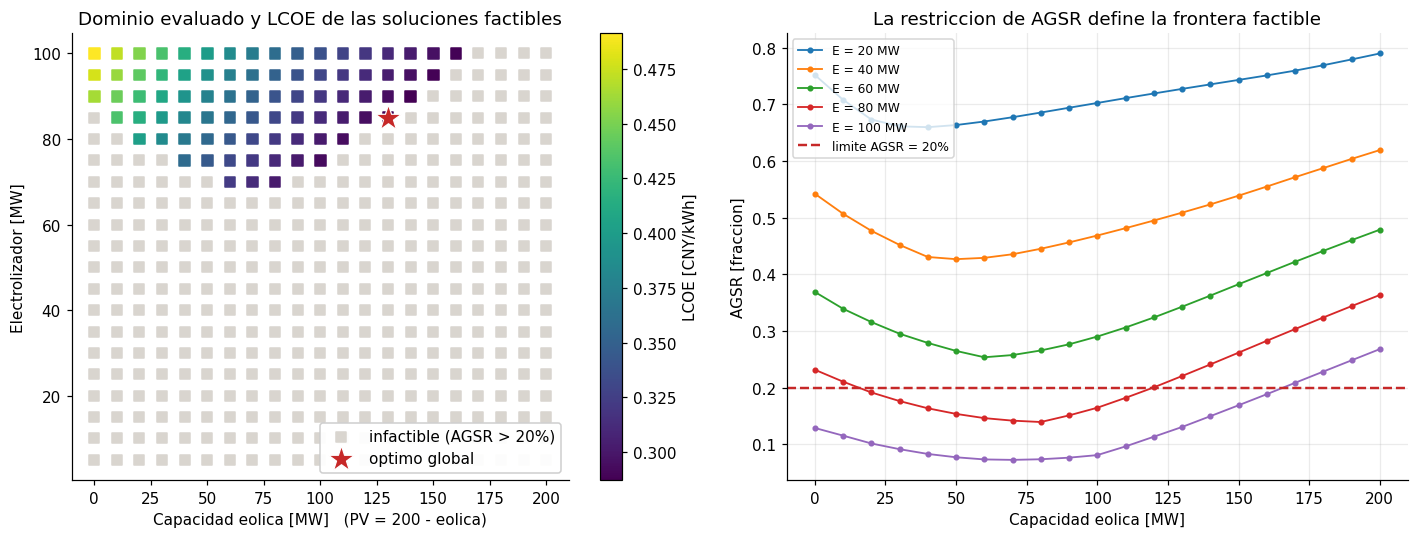

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panel 1: LCOE sobre todo el dominio, distinguiendo factibles de infactibles.
infactibles = base_grid[~base_grid["feasible"]]
factibles = base_grid[base_grid["feasible"]]

axes[0].scatter(infactibles["wind_mw"], infactibles["electrolyzer_mw"],
                c="#d9d5cf", s=42, marker="s", label="infactible (AGSR > 20%)")
sc = axes[0].scatter(factibles["wind_mw"], factibles["electrolyzer_mw"],
                     c=factibles["lcoe_cny_per_kwh"], cmap="viridis", s=48, marker="s")
axes[0].scatter([base_best.wind_mw], [base_best.electrolyzer_mw], marker="*",
                s=320, color="#c62828", edgecolor="white", linewidth=0.8,
                label="optimo global", zorder=5)
axes[0].set_xlabel("Capacidad eolica [MW]   (PV = 200 - eolica)")
axes[0].set_ylabel("Electrolizador [MW]")
axes[0].set_title("Dominio evaluado y LCOE de las soluciones factibles")
axes[0].legend(loc="lower right", framealpha=0.95)
axes[0].grid(False)
fig.colorbar(sc, ax=axes[0], label="LCOE [CNY/kWh]")

# Panel 2: AGSR contra capacidad eolica, que es lo que define la frontera factible.
for e_mw, grupo in base_grid.groupby("electrolyzer_mw"):
    if e_mw % 20 == 0:
        axes[1].plot(grupo["wind_mw"], grupo["agsr"], marker="o", ms=3, lw=1.2,
                     label="E = {:.0f} MW".format(e_mw))
axes[1].axhline(ESCENARIO.constraints.agsr_max, color="#c62828", ls="--", lw=1.6,
                label="limite AGSR = 20%")
axes[1].set_xlabel("Capacidad eolica [MW]")
axes[1].set_ylabel("AGSR [fraccion]")
axes[1].set_title("La restriccion de AGSR define la frontera factible")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 12. Instancia mixta continua-discreta

El vector $\mathbf{x}\in\mathbb{R}^4$ se decodifica como:

1. $W\in[0,200]$ MW continuo y $P=200-W$ MW;
2. $n_E\in\{10,\ldots,20\}$ y $E=5n_E$ MW;
3. $B^P\in\{0,5,\ldots,50\}$ MW;
4. $h_B\in\{1,2,4\}$ h cuando $B^P>0$.

Si $B^P=0$, la duración se fija canónicamente en cero. El dominio contiene infinitos
diseños por la continuidad de $W$; por tanto, no se atribuye una cardinalidad ni un
porcentaje de cobertura a las 600 evaluaciones.

La aptitud sigue reglas de factibilidad: toda solución factible domina a una infactible;
entre infactibles se minimiza la suma de violaciones normalizadas y entre factibles se
minimiza exclusivamente LCOE. NPC y LCOH no intervienen en esa comparación.


In [16]:
@dataclass(frozen=True)
class Design:
    wind_mw: float
    pv_mw: float
    n_electrolyzer_units: int
    electrolyzer_mw: float
    battery_mw: float
    battery_duration_h: float
    battery_mwh: float

    def to_dict(self):
        return {f.name: getattr(self, f.name) for f in fields(self)}

    @property
    def cache_key(self):
        return (round(self.wind_mw, 10), self.n_electrolyzer_units,
                self.battery_mw, self.battery_duration_h)


class DecisionSpace:
    """Dominio mixto: una variable continua y tres coordenadas decodificadas."""

    VARIABLE_NAMES = ("wind_mw", "n_electrolyzer_units", "battery_mw",
                      "battery_duration_index")

    def __init__(self, config):
        self.config = config
        electrolyzer = config.electrolyzer
        battery = config.battery
        constraints = config.constraints
        self.lower = np.array([0.0, electrolyzer.min_units,
                               battery.power_min_mw, 0.0], dtype=float)
        self.upper = np.array([constraints.total_generation_capacity_mw,
                               electrolyzer.max_units, battery.power_max_mw,
                               len(battery.duration_candidates_h) - 1], dtype=float)

    @property
    def n_dimensions(self):
        return len(self.lower)

    def clip(self, x):
        return np.clip(np.asarray(x, dtype=float), self.lower, self.upper)

    def sample(self, rng, size):
        return rng.uniform(self.lower, self.upper, size=(size, self.n_dimensions))

    def decode(self, x):
        config = self.config
        battery = config.battery
        electrolyzer = config.electrolyzer
        total_capacity = config.constraints.total_generation_capacity_mw
        x = self.clip(x)

        wind_mw = float(x[0])
        pv_mw = total_capacity - wind_mw
        units = int(np.clip(round(float(x[1])),
                            electrolyzer.min_units, electrolyzer.max_units))
        step = battery.power_step_mw
        battery_mw = float(np.clip(round(float(x[2]) / step) * step,
                                   battery.power_min_mw, battery.power_max_mw))
        candidates = battery.duration_candidates_h
        index = int(np.clip(round(float(x[3])), 0, len(candidates) - 1))
        duration_h = 0.0 if battery_mw == 0.0 else float(candidates[index])
        return Design(wind_mw, pv_mw, units, units * electrolyzer.unit_mw,
                      battery_mw, duration_h, battery_mw * duration_h)

    def warnings(self):
        messages = []
        battery = self.config.battery
        if len(battery.duration_candidates_h) > 1 and not self.config.costs.battery.has_energy_cost:
            messages.append("la duracion es variable pero la bateria no tiene costo por energia")
        return messages


@dataclass(frozen=True)
class Evaluation:
    """Evaluación con orden de Deb y objetivo económico separado."""

    design: Design
    result: SimulationResult

    @property
    def merit(self):
        # Transformación monótona: los factibles quedan en (-1, 0) y los infactibles
        # en [0, infinito). Así no existe un peso de penalización ajustable.
        if self.result.feasible:
            return -1.0 / (1.0 + self.result.lcoe_cny_per_kwh)
        return self.result.total_normalized_violation

    @property
    def score(self):
        return self.result.lcoe_cny_per_kwh if self.result.feasible else np.nan

    def to_record(self):
        record = self.result.to_dict()
        record["score"] = self.score
        record["merit"] = self.merit
        return record


def better(a, b):
    return b is None or a.merit < b.merit


class ObjectiveFunction:
    """Objetivo LCOE con presupuesto de solicitudes y cache por corrida."""

    def __init__(self, hourly, config, space=None):
        self.config = config
        self.cache = as_profile_cache(hourly, config)
        self.space = space if space is not None else DecisionSpace(config)
        self.reset_counter()

    def __call__(self, x):
        return self.evaluate(x)

    def evaluate(self, x):
        design = self.space.decode(x)
        self.n_requests += 1
        cached = self._result_cache.get(design.cache_key)
        if cached is None:
            cached = simulate_mixed(
                self.cache, design.wind_mw, design.n_electrolyzer_units,
                design.battery_mw, design.battery_duration_h, self.config
            )
            self._result_cache[design.cache_key] = cached
            self.n_simulations += 1
        else:
            self.n_duplicates += 1
        return Evaluation(design=design, result=cached)

    @property
    def n_evaluations(self):
        return self.n_requests

    def reset_counter(self):
        self.n_requests = 0
        self.n_simulations = 0
        self.n_duplicates = 0
        self._result_cache = {}


ESPACIO = DecisionSpace(ESCENARIO)
for aviso in ESPACIO.warnings():
    print("AVISO:", aviso)

display(pd.DataFrame({
    "variable": ESPACIO.VARIABLE_NAMES,
    "limite_inferior": ESPACIO.lower,
    "limite_superior": ESPACIO.upper,
    "tratamiento": ["continua (PV=200-W)", "entero mas cercano",
                    "multiplo de 5 MW", "indice; 0 h si B=0"],
}))

n_units = ESCENARIO.electrolyzer.max_units - ESCENARIO.electrolyzer.min_units + 1
n_positive_battery = int(ESCENARIO.battery.power_max_mw / ESCENARIO.battery.power_step_mw)
n_catalogs_raw = n_units * (n_positive_battery + 1) * len(ESCENARIO.battery.duration_candidates_h)
n_catalogs_effective = n_units * (1 + n_positive_battery * len(ESCENARIO.battery.duration_candidates_h))
print("Catalogos discretos brutos:", n_catalogs_raw)
print("Catalogos efectivos tras canonizar B=0:", n_catalogs_effective)
print("W es continuo: el dominio total no tiene cardinalidad finita.")


,variable,limite_inferior,limite_superior,tratamiento
0,wind_mw,0.0,200.0,continua (PV=200-W)
1,n_electrolyzer_units,10.0,20.0,entero mas cercano
2,battery_mw,0.0,50.0,multiplo de 5 MW
3,battery_duration_index,0.0,2.0,indice; 0 h si B=0


Catalogos discretos brutos: 363
Catalogos efectivos tras canonizar B=0: 341
W es continuo: el dominio total no tiene cardinalidad finita.


## 13. Clase base de los optimizadores

Todo lo que **no** es el operador de busqueda vive aqui: la semilla, el conteo de
evaluaciones, el registro del historial por iteracion y el cronometraje. Agregar una
metaheuristica nueva significa escribir una subclase que implemente `_search` y
registrarla en `REGISTRY`; nada mas.

Que esto sea comun no es una comodidad de programacion, es lo que hace valida la
comparacion: los 6 algoritmos producen historiales con el mismo formato, cuentan las
evaluaciones de la misma forma y se cronometran con el mismo reloj.

**El contrato de una subclase** son dos llamadas:

- `self._evaluate(x)` evalua un vector y actualiza la mejor solucion conocida.
- `self._record(iteration, **extra)` anota el estado de la mejor solucion al cierre de
  una iteracion. Los `extra` sirven para guardar el coeficiente de exploracion del
  algoritmo (`a` en GWO y WOA, `h` en SHO), que es lo que permite despues graficar la
  transicion de exploracion a explotacion.

In [17]:
@dataclass
class OptimizationResult:
    """Resultado de una corrida: la mejor solucion y como se llego a ella."""

    algorithm: str
    seed: int
    best: Evaluation
    history: pd.DataFrame
    n_evaluations: int
    n_unique_evaluations: int
    n_duplicates: int
    elapsed_s: float

    @property
    def best_score(self):
        return self.best.score

    def summary(self):
        """Fila plana con lo esencial, para agregar varias corridas."""
        record = self.best.to_record()
        record.update({"algorithm": self.algorithm, "seed": self.seed,
                       "n_evaluations": self.n_evaluations,
                       "n_unique_evaluations": self.n_unique_evaluations,
                       "n_duplicates": self.n_duplicates,
                       "elapsed_s": self.elapsed_s})
        return record


class Optimizer:
    """Base de todos los optimizadores sobre el espacio mixto WPEB."""

    name = "base"

    def __init__(self, objective, config=None, seed=None):
        self.objective = objective
        self.config = config if config is not None else objective.config.metaheuristic
        self.seed = int(self.config.seed if seed is None else seed)
        self.rng = np.random.default_rng(self.seed)
        self.space = objective.space
        self.best = None
        self._history = []

    # -- utilidades para las subclases --------------------------------------

    def _evaluate(self, x):
        """Evalua un vector y actualiza la mejor solucion conocida."""
        evaluation = self.objective.evaluate(x)
        if better(evaluation, self.best):
            self.best = evaluation
        return evaluation

    def _record(self, iteration, **extra):
        """Anota el estado de la mejor solucion al cierre de una iteracion."""
        if self.best is None:
            raise RuntimeError("no se puede registrar antes de la primera evaluacion")

        result = self.best.result
        row = {
            "iteration": iteration,
            "best_score": self.best.score,
            "best_merit": self.best.merit,
            "n_evaluations": self.objective.n_evaluations,
            "n_unique_evaluations": self.objective.n_simulations,
            "n_duplicates": self.objective.n_duplicates,
            "wind_mw": result.wind_mw,
            "pv_mw": result.pv_mw,
            "electrolyzer_mw": result.electrolyzer_mw,
            "n_electrolyzer_units": result.n_electrolyzer_units,
            "battery_mw": result.battery_mw,
            "battery_mwh": result.battery_mwh,
            "battery_duration_h": result.battery_duration_h,
            "feasible": result.feasible,
            "agsr": result.agsr,
            "electrolyzer_cf": result.electrolyzer_cf,
            "lcoe_cny_per_kwh": result.lcoe_cny_per_kwh,
            "lcoh_cny_per_kg": result.lcoh_cny_per_kg,
        }
        row.update(extra)
        self._history.append(row)

    # -- contrato -----------------------------------------------------------

    def _search(self):
        """Ejecuta la busqueda, llamando a ``_evaluate`` y ``_record``."""
        raise NotImplementedError("cada metaheuristica debe implementar _search()")

    def optimize(self):
        """Corre el algoritmo y devuelve el resultado con su historial."""
        self.objective.reset_counter()
        self.best = None
        self._history = []

        started = time.perf_counter()
        self._search()
        elapsed = time.perf_counter() - started

        if self.best is None:
            raise RuntimeError("{} termino sin evaluar ninguna solucion".format(self.name))

        return OptimizationResult(
            algorithm=self.name, seed=self.seed, best=self.best,
            history=pd.DataFrame(self._history),
            n_evaluations=self.objective.n_evaluations,
            n_unique_evaluations=self.objective.n_simulations,
            n_duplicates=self.objective.n_duplicates, elapsed_s=elapsed,
        )

## 14. Las metaheuristicas

Las seis estan programadas completas a continuacion, **una por celda**, cada una con su
explicacion. Todas leen sus hiperparametros del bloque de configuracion de la seccion 3.

| Algoritmo | Familia | Idea central | Fuente |
|---|---|---|---|
| **GWO** | enjambre jerarquico | jerarquia alfa-beta-delta: cada lobo se mueve al promedio de los tirones de los tres lideres | Mirjalili et al. (2014) |
| **PSO** | enjambre | cada particula combina su mejor historico con el mejor global, con constriccion | Clerc & Kennedy (2002) |
| **GA** | evolutivo | seleccion por torneo, cruce BLX-alpha, mutacion gaussiana, elitismo | real-coded GA estandar |
| **SHO** | enjambre jerarquico | busqueda, encierro, grupo de confianza y ataque promedio | Dhiman & Kumar (2017) |
| **WOA** | enjambre | encierro o espiral "bubble-net", sorteados 50/50 por agente | Mirjalili & Lewis (2016) |
| **random** | linea base | muestreo uniforme sobre el dominio mixto, sin memoria | -- |

**Sobre la linea base.** `random` no es relleno: es el control del experimento. Toda
metaheuristica deberia superarla con el mismo presupuesto de evaluaciones. Si no lo hace,
el problema esta mal planteado o el algoritmo mal ajustado, y esa es una conclusion tan
valida como cualquier otra.

### 14.1 GWO -- Grey Wolf Optimizer

Modela la jerarquia social de una manada de lobos: las tres mejores posiciones conocidas
son **alfa**, **beta** y **delta**, y el resto de la manada se reposiciona siguiendo a
las tres a la vez.

Para cada lider $\ell$ y cada lobo $i$:

$$\vec{D}_\ell = |\vec{C} \cdot \vec{X}_\ell - \vec{X}_i| \qquad
\vec{X}_{i,\ell} = \vec{X}_\ell - \vec{A} \cdot \vec{D}_\ell$$

y la nueva posicion es el **promedio de los tres tirones**. Los coeficientes son
$\vec{A} = 2a\vec{r_1} - a$ y $\vec{C} = 2\vec{r_2}$, con $\vec{r_1}, \vec{r_2}$
uniformes en $[0,1]$.

El coeficiente $a$ **decae linealmente de 2 a 0** a lo largo de las iteraciones. Cuando
$a$ es grande, $|A|$ puede superar 1 y el lobo se aleja del lider: exploracion. Cuando
$a$ se acerca a 0, $|A| < 1$ siempre y la manada converge sobre los lideres:
explotacion. Esa transicion programada es todo el mecanismo de balance del algoritmo.

El movimiento esta vectorizado sobre lobos y dimensiones: `leaders[:, None, :]` difunde
los 3 lideres sobre toda la manada.

In [18]:
class GreyWolfOptimizer(Optimizer):
    """GWO clasico: la jerarquia alfa-beta-delta guia al resto de la manada."""

    name = "gwo"

    def _search(self):
        space = self.space
        n_wolves = self.config.population
        n_iterations = self.config.iterations

        positions = space.sample(self.rng, n_wolves)

        # Las tres mejores posiciones conocidas. Se guardan aparte de ``self.best``
        # porque el movimiento del GWO necesita las tres.
        leaders = np.zeros((3, space.n_dimensions), dtype=float)
        leader_scores = np.full(3, np.inf)

        for iteration in range(n_iterations):
            for i in range(n_wolves):
                positions[i] = space.clip(positions[i])
                evaluation = self._evaluate(positions[i])
                self._update_leaders(leaders, leader_scores, positions[i],
                                     evaluation.merit)

            # ``a`` decae linealmente de 2 a 0: la manada pasa de explorar a
            # explotar alrededor de los lideres.
            a = 2.0 - iteration * (2.0 / max(n_iterations - 1, 1))

            positions = self._move(positions, leaders, a)

            self._record(iteration + 1, a=a)

    @staticmethod
    def _update_leaders(leaders, leader_scores, position, score):
        """Inserta una posicion en la jerarquia alfa-beta-delta si corresponde."""
        if score < leader_scores[0]:
            leaders[2] = leaders[1]
            leader_scores[2] = leader_scores[1]
            leaders[1] = leaders[0]
            leader_scores[1] = leader_scores[0]
            leaders[0] = position.copy()
            leader_scores[0] = score
        elif score < leader_scores[1]:
            leaders[2] = leaders[1]
            leader_scores[2] = leader_scores[1]
            leaders[1] = position.copy()
            leader_scores[1] = score
        elif score < leader_scores[2]:
            leaders[2] = position.copy()
            leader_scores[2] = score

    def _move(self, positions, leaders, a):
        """Nueva posicion de cada lobo: promedio de los tres tirones de lider."""
        n_wolves, n_dimensions = positions.shape
        shape = (3, n_wolves, n_dimensions)

        r1 = self.rng.random(shape)
        r2 = self.rng.random(shape)

        A = 2.0 * a * r1 - a
        C = 2.0 * r2

        # leaders[:, None, :] difunde los 3 lideres sobre toda la manada.
        distance = np.abs(C * leaders[:, None, :] - positions[None, :, :])
        candidates = leaders[:, None, :] - A * distance

        return candidates.mean(axis=0)

### 14.2 PSO -- Particle Swarm Optimization

Cada particula recuerda su mejor posicion historica (`pbest`) y conoce la mejor de todo
el enjambre (`gbest`). La velocidad combina ambas atracciones:

$$\vec{v} \leftarrow \chi\,\Big(\vec{v}
  + c_1 \vec{r_1} \cdot (\vec{p}_{best} - \vec{x})
  + c_2 \vec{r_2} \cdot (\vec{g}_{best} - \vec{x})\Big)
\qquad \vec{x} \leftarrow \vec{x} + \vec{v}$$

Esta es la formulacion de **constriccion** de Clerc-Kennedy, no la de peso de inercia
clasico: el factor $\chi = 0.729$ multiplica **toda la suma**, no solo la velocidad
previa. Esa diferencia es lo que garantiza convergencia sin necesidad de decaer $\chi$ a
lo largo de las iteraciones, y por eso PSO es el unico de los cinco que no tiene un
coeficiente que decae con el tiempo.

La velocidad se acota al 20% del rango de cada variable (`velocity_clamp_ratio`) para que
una particula no salte de un extremo al otro del dominio en un solo paso.

In [19]:
class ParticleSwarm(Optimizer):
    """PSO con constriccion de Clerc-Kennedy y velocidad acotada por variable."""

    name = "pso"

    def _search(self):
        space = self.space
        params = self.config.pso
        n_particles = self.config.population
        n_iterations = self.config.iterations

        positions = space.sample(self.rng, n_particles)
        velocity_range = params.velocity_clamp_ratio * (space.upper - space.lower)
        velocities = self.rng.uniform(-velocity_range, velocity_range,
                                      size=positions.shape)

        personal_best_positions = positions.copy()
        personal_best_scores = np.full(n_particles, np.inf)
        global_best_position = positions[0].copy()
        global_best_score = np.inf

        for iteration in range(n_iterations):
            for i in range(n_particles):
                positions[i] = space.clip(positions[i])
                evaluation = self._evaluate(positions[i])
                score = evaluation.merit
                if score < personal_best_scores[i]:
                    personal_best_scores[i] = score
                    personal_best_positions[i] = positions[i].copy()
                if score < global_best_score:
                    global_best_score = score
                    global_best_position = positions[i].copy()

            r1 = self.rng.random(positions.shape)
            r2 = self.rng.random(positions.shape)
            velocities = params.inertia * (
                velocities
                + params.cognitive * r1 * (personal_best_positions - positions)
                + params.social * r2 * (global_best_position[None, :] - positions)
            )
            velocities = np.clip(velocities, -velocity_range, velocity_range)
            positions = positions + velocities

            self._record(iteration + 1)

### 14.3 GA -- Algoritmo genetico de codificacion real

El unico evolutivo del grupo: en vez de mover agentes en el espacio, construye una nueva
poblacion en cada generacion a partir de la anterior.

1. **Elitismo**: los `elite_count = 2` mejores pasan intactos.
2. **Seleccion por torneo**: se toman `tournament_size = 3` individuos al azar y gana el
   de mejor merito. Es una presion selectiva moderada e **invariante a la escala del
   criterio de comparacion**, propiedad util al aplicar las reglas de factibilidad.
3. **Cruce BLX-alpha** (probabilidad 0.90): el hijo se muestrea uniforme en el intervalo
   entre padres, **expandido** un `alpha = 0.5` a cada lado. La expansion permite generar
   hijos fuera del rango de los padres, que es lo que evita el colapso prematuro de la
   diversidad.
4. **Mutacion gaussiana**: cada gen muta con probabilidad 0.10, con `sigma` igual al 10%
   del rango de esa variable.

Nota sobre el presupuesto: los individuos de elite se **reevaluan** en la generacion
siguiente, lo que desperdicia unas pocas evaluaciones. Se deja asi a proposito: mantener
el presupuesto identico al de los demas algoritmos (`population x iterations`) importa
mas que ahorrarlas, porque es lo que hace comparable la comparativa.

In [20]:
class GeneticAlgorithm(Optimizer):
    """GA real-coded: torneo + BLX-alpha + mutacion gaussiana + elitismo."""

    name = "ga"

    def _search(self):
        space = self.space
        params = self.config.ga
        n_pop = self.config.population
        n_iterations = self.config.iterations

        positions = space.sample(self.rng, n_pop)

        for generation in range(n_iterations):
            scores = np.empty(n_pop)
            for i in range(n_pop):
                positions[i] = space.clip(positions[i])
                scores[i] = self._evaluate(positions[i]).merit

            positions = self._next_generation(positions, scores, params, space)

            self._record(generation + 1)

    def _next_generation(self, positions, scores, params, space):
        n_pop = len(positions)
        order = np.argsort(scores)
        elite_count = min(params.elite_count, n_pop)

        new_positions = np.empty_like(positions)
        new_positions[:elite_count] = positions[order[:elite_count]]

        for i in range(elite_count, n_pop):
            parent_a = self._tournament_select(positions, scores, params.tournament_size)
            parent_b = self._tournament_select(positions, scores, params.tournament_size)

            if self.rng.random() < params.crossover_rate:
                child = self._crossover(parent_a, parent_b, params.blx_alpha)
            else:
                child = parent_a.copy()

            child = self._mutate(child, params, space)
            new_positions[i] = space.clip(child)

        return new_positions

    def _tournament_select(self, positions, scores, tournament_size):
        """Elige el mejor de ``tournament_size`` individuos tomados al azar."""
        contenders = self.rng.choice(len(positions), size=tournament_size, replace=False)
        winner = contenders[np.argmin(scores[contenders])]
        return positions[winner]

    def _crossover(self, parent_a, parent_b, alpha=0.5):
        """Cruce BLX-alpha: uniforme en el intervalo entre padres, expandido."""
        low = np.minimum(parent_a, parent_b)
        high = np.maximum(parent_a, parent_b)
        span = high - low
        return self.rng.uniform(low - alpha * span, high + alpha * span)

    def _mutate(self, individual, params, space):
        """Mutacion gaussiana gen a gen, con sigma proporcional al rango."""
        sigma = params.mutation_sigma_ratio * (space.upper - space.lower)
        mask = self.rng.random(individual.shape) < params.mutation_rate
        noise = self.rng.normal(0.0, sigma)
        return np.where(mask, individual + noise, individual)

### 14.4 SHO - Spotted Hyena Optimizer

La implementación sigue las ecuaciones de Dhiman y Kumar (2017): encierro, formación
de un grupo de confianza y ataque mediante el promedio del grupo. Los coeficientes son

\[
\mathbf B=2\mathbf r_1,\qquad
\mathbf E=2h\mathbf r_2-h,\qquad
h=5\left(1-\frac{t}{T-1}\right).
\]

Como `count_nos` no queda definido operacionalmente en el artículo, se declara aquí la
regla reproducible usada: se normalizan las distancias a la mejor solución, se sortea un
radio $M\sim U(0{,}5,1)$ y el grupo contiene las soluciones dentro de ese radio, siempre
incluyendo la mejor. Para cada miembro se calcula

\[
\mathbf P_k'=\mathbf P_h-\mathbf E_k\odot
|\mathbf B_k\odot\mathbf P_h-\mathbf P_k|,
\qquad
\mathbf P_i(t+1)=\frac{1}{N}\sum_{k=1}^{N}\mathbf P_k'.
\]

Esto implementa la agrupación omitida por la versión anterior y hace explícita la única
ambigüedad que no puede resolverse con el pseudocódigo publicado.


In [21]:
class SpottedHyenaOptimizer(Optimizer):
    """SHO con encierro, grupo de confianza y ataque por promedio."""

    name = "sho"

    def _search(self):
        space = self.space
        h_max = self.config.sho.h_max
        n_hyenas = self.config.population
        n_iterations = self.config.iterations
        positions = space.sample(self.rng, n_hyenas)
        prey = positions[0].copy()
        prey_eval = None

        for iteration in range(n_iterations):
            evaluations = []
            for i in range(n_hyenas):
                positions[i] = space.clip(positions[i])
                evaluation = self._evaluate(positions[i])
                evaluations.append(evaluation)
                if better(evaluation, prey_eval):
                    prey_eval = evaluation
                    prey = positions[i].copy()

            h = h_max * (1.0 - iteration / max(n_iterations - 1, 1))
            positions, mean_group = self._move(positions, prey, h)
            self._record(iteration + 1, h=h, mean_group_size=mean_group)

    def _move(self, positions, prey, h):
        n_hyenas, n_dimensions = positions.shape
        span = np.maximum(self.space.upper - self.space.lower, 1e-12)
        normalized_distance = np.linalg.norm((positions - prey) / span, axis=1) / np.sqrt(n_dimensions)
        new_positions = np.empty_like(positions)
        group_sizes = []

        for i in range(n_hyenas):
            radius = self.rng.uniform(0.5, 1.0)
            group = np.flatnonzero(normalized_distance <= radius)
            if len(group) == 0:
                group = np.array([int(np.argmin(normalized_distance))])
            members = positions[group]
            r1 = self.rng.random(members.shape)
            r2 = self.rng.random(members.shape)
            B = 2.0 * r1
            E = 2.0 * h * r2 - h
            distance = np.abs(B * prey[None, :] - members)
            encircled = prey[None, :] - E * distance
            new_positions[i] = encircled.mean(axis=0)
            group_sizes.append(len(group))

        return new_positions, float(np.mean(group_sizes))


### 14.5 WOA - Whale Optimization Algorithm

WOA sortea una rama por ballena. Con $\mathbf A=2a\mathbf r_1-a$ y
$\mathbf C=2\mathbf r_2$, ambas generadas **por dimensión**:

- si $p<0{,}5$ y $\max_j|A_j|<1$, encierra a la mejor solución;
- si $p<0{,}5$ y $\max_j|A_j|\geq1$, explora respecto de una ballena aleatoria;
- si $p\geq0{,}5$, aplica la espiral logarítmica con $l\sim U(-1,1)$ y $b=1$.

El parámetro $a$ decrece linealmente de 2 a 0. La condición vectorial se explicita para
evitar interpretar $\mathbf A$ como un único escalar compartido por todas las variables.


In [22]:
class WhaleOptimization(Optimizer):
    """WOA: encierro/busqueda aleatoria o espiral bubble-net, sorteados por ballena."""

    name = "woa"

    def _search(self):
        space = self.space
        spiral_constant = self.config.woa.spiral_constant
        n_whales = self.config.population
        n_iterations = self.config.iterations

        positions = space.sample(self.rng, n_whales)
        best = positions[0].copy()
        best_merit = np.inf

        for iteration in range(n_iterations):
            for i in range(n_whales):
                positions[i] = space.clip(positions[i])
                evaluation = self._evaluate(positions[i])
                if evaluation.merit < best_merit:
                    best_merit = evaluation.merit
                    best = positions[i].copy()

            a = 2.0 - iteration * (2.0 / max(n_iterations - 1, 1))

            positions = self._move(positions, best, a, spiral_constant)

            self._record(iteration + 1, a=a)

    def _move(self, positions, best, a, spiral_constant):
        """Nueva posicion de cada ballena, con coeficientes propios por ballena."""
        n_whales = len(positions)
        new_positions = np.empty_like(positions)

        for i in range(n_whales):
            r1 = self.rng.random(positions.shape[1])
            r2 = self.rng.random(positions.shape[1])
            A = 2.0 * a * r1 - a
            C = 2.0 * r2
            p = self.rng.random()

            if p < 0.5:
                if np.max(np.abs(A)) < 1.0:
                    # Explotacion: encierro sobre la mejor posicion conocida.
                    distance = np.abs(C * best - positions[i])
                    new_positions[i] = best - A * distance
                else:
                    # Exploracion: encierro sobre una ballena aleatoria de la manada.
                    random_whale = positions[self.rng.integers(0, n_whales)]
                    distance = np.abs(C * random_whale - positions[i])
                    new_positions[i] = random_whale - A * distance
            else:
                # Ataque por burbujas: espiral logaritmica alrededor de la mejor.
                l = self.rng.uniform(-1.0, 1.0)
                distance_to_best = np.abs(best - positions[i])
                new_positions[i] = (
                    distance_to_best * np.exp(spiral_constant * l)
                    * np.cos(2.0 * np.pi * l) + best
                )

        return new_positions

### 14.6 Busqueda aleatoria -- la linea base

Muestrea disenos al azar y se queda con el mejor. Sin memoria, sin poblacion, sin
adaptacion.

Un detalle deliberado la separa de las otras cinco: **muestrea directamente sobre el
dominio mixto** -- unidades enteras, potencias multiplo de 5 MW, duraciones del catalogo
-- en lugar de muestrear continuo y proyectar. Asi cada muestra es un diseno valido, y la
comparacion mide **busqueda**, no suerte en el redondeo. Si muestreara continuo, parte de
su desempeno vendria del sesgo que introduce la proyeccion, no del muestreo.

Recibe exactamente el mismo presupuesto que los demas (`population x iterations`
evaluaciones) y reporta su historial cada `population` evaluaciones, para que su curva de
convergencia sea comparable iteracion a iteracion con las de los algoritmos poblacionales.

In [23]:
class RandomSearch(Optimizer):
    """Muestreo uniforme sobre el dominio mixto, sin memoria."""

    name = "random"

    def _search(self):
        config = self.objective.config
        battery = config.battery
        electrolyzer = config.electrolyzer

        battery_grid = np.arange(battery.power_min_mw,
                                 battery.power_max_mw + 1e-9,
                                 battery.power_step_mw)
        n_durations = len(battery.duration_candidates_h)
        total_capacity = config.constraints.total_generation_capacity_mw

        # Mismo presupuesto que los algoritmos poblacionales, para que la
        # comparacion sea a igual numero de evaluaciones.
        budget = self.config.evaluation_budget
        report_every = max(self.config.population, 1)

        for evaluation_index in range(budget):
            x = np.array([
                self.rng.uniform(0.0, total_capacity),
                self.rng.integers(electrolyzer.min_units, electrolyzer.max_units + 1),
                self.rng.choice(battery_grid),
                self.rng.integers(0, n_durations),
            ], dtype=float)
            self._evaluate(x)

            if (evaluation_index + 1) % report_every == 0:
                self._record((evaluation_index + 1) // report_every)

        # Garantiza una fila final aunque el presupuesto no sea multiplo exacto.
        if not self._history or self._history[-1]["n_evaluations"] < budget:
            self._record(len(self._history) + 1)


REGISTRY = {
    GreyWolfOptimizer.name: GreyWolfOptimizer,
    ParticleSwarm.name: ParticleSwarm,
    GeneticAlgorithm.name: GeneticAlgorithm,
    SpottedHyenaOptimizer.name: SpottedHyenaOptimizer,
    WhaleOptimization.name: WhaleOptimization,
    RandomSearch.name: RandomSearch,
}


def get_optimizer(name):
    """Busca un optimizador por nombre, con un error util si no existe."""
    try:
        return REGISTRY[name]
    except KeyError:
        raise KeyError("algoritmo desconocido '{}'. Disponibles: {}".format(
            name, ", ".join(sorted(REGISTRY)))) from None


# Tabla de hiperparametros efectivamente en uso, leida de la configuracion.
_mh = ESCENARIO.metaheuristic
tabla_hiperparametros = pd.DataFrame([
    ["gwo", "Grey Wolf Optimizer", "enjambre jerarquico",
     "a decae 2 -> 0; lideres alfa, beta, delta", "Mirjalili et al. (2014)"],
    ["pso", "Particle Swarm Optimization", "enjambre",
     "chi={}; c1=c2={}; |v| <= {:.0%} del rango".format(
         _mh.pso.inertia, _mh.pso.cognitive, _mh.pso.velocity_clamp_ratio),
     "Clerc & Kennedy (2002)"],
    ["ga", "Genetic Algorithm", "evolutivo",
     "torneo k={}; BLX-{} p={}; mutacion p={} sigma={:.0%}; elite={}".format(
         _mh.ga.tournament_size, _mh.ga.blx_alpha, _mh.ga.crossover_rate,
         _mh.ga.mutation_rate, _mh.ga.mutation_sigma_ratio, _mh.ga.elite_count),
     "real-coded GA estandar"],
    ["sho", "Spotted Hyena Optimizer", "enjambre jerarquico",
     "h decae {} -> 0; grupo de confianza y ataque promedio".format(_mh.sho.h_max),
     "Dhiman & Kumar (2017)"],
    ["woa", "Whale Optimization Algorithm", "enjambre",
     "encierro/espiral 50/50; b={}; a decae 2 -> 0".format(_mh.woa.spiral_constant),
     "Mirjalili & Lewis (2016)"],
    ["random", "Random Search", "linea base",
     "muestreo uniforme sobre el dominio mixto", "--"],
], columns=["codigo", "nombre", "familia", "hiperparametros", "fuente"])

display(tabla_hiperparametros)
print("Presupuesto identico para los {} algoritmos: {} evaluaciones por corrida "
      "({} individuos x {} iteraciones)".format(
          len(REGISTRY), _mh.evaluation_budget, _mh.population, _mh.iterations))
print("Restricciones: reglas de factibilidad sin coeficiente de penalizacion.")

,codigo,nombre,familia,hiperparametros,fuente
0,gwo,Grey Wolf Optimizer,enjambre jerarquico,"a decae 2 -> 0; lideres alfa, beta, delta",Mirjalili et al. (2014)
1,pso,Particle Swarm Optimization,enjambre,chi=0.729; c1=c2=1.49445; |v| <= 20% del rango,Clerc & Kennedy (2002)
2,ga,Genetic Algorithm,evolutivo,torneo k=3; BLX-0.5 p=0.9; mutacion p=0.1 sigm...,real-coded GA estandar
3,sho,Spotted Hyena Optimizer,enjambre jerarquico,h decae 5.0 -> 0; grupo de confianza y ataque ...,Dhiman & Kumar (2017)
4,woa,Whale Optimization Algorithm,enjambre,encierro/espiral 50/50; b=1.0; a decae 2 -> 0,Mirjalili & Lewis (2016)
5,random,Random Search,linea base,muestreo uniforme sobre el dominio mixto,--


Presupuesto identico para los 6 algoritmos: 600 evaluaciones por corrida (20 individuos x 30 iteraciones)
Restricciones: reglas de factibilidad sin coeficiente de penalizacion.


## 15. Identidad visual de los algoritmos

Cada algoritmo tiene **un color fijo en todas las figuras**, asignado por identidad y
nunca por rango dentro de un grafico. Si `gwo` fuera azul en una figura y verde en la
siguiente, el lector perderia la referencia.

Dos decisiones deliberadas:

- **`random` no recibe un matiz categorico.** Es la linea base, no un competidor, asi que
  va en gris neutro con linea discontinua y marcador "x" -- la convencion habitual para
  una referencia.
- **En el grafico de dispersion, la forma del marcador es la codificacion primaria.** Con
  5 series categoricas, el color solo no alcanza en el contexto "todos los pares visibles
  a la vez": la distancia percibida entre el magenta y el naranja cae por debajo del
  umbral de discriminacion. Por eso ahi cada algoritmo tiene ademas su propia forma.

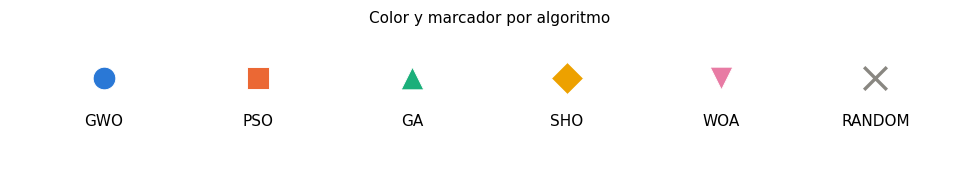

In [24]:
ALGORITHM_ORDER = ("gwo", "pso", "ga", "sho", "woa", "random")

ALGORITHM_COLORS = {
    "gwo": "#2a78d6",      # azul
    "pso": "#eb6834",      # naranja
    "ga": "#1baf7a",       # verde-agua
    "sho": "#eda100",      # amarillo
    "woa": "#e87ba4",      # magenta
    "random": "#898781",   # gris neutro -- linea base, no una serie categorica
}

ALGORITHM_LINESTYLES = {
    "gwo": "-", "pso": "-", "ga": "-", "sho": "-", "woa": "-", "random": "--",
}

# La codificacion primaria de identidad en los graficos de dispersion.
ALGORITHM_MARKERS = {
    "gwo": "o", "pso": "s", "ga": "^", "sho": "D", "woa": "v", "random": "x",
}


def algorithm_color(name):
    return ALGORITHM_COLORS.get(name, "#666666")


def algorithm_linestyle(name):
    return ALGORITHM_LINESTYLES.get(name, "-")


def algorithm_marker(name):
    return ALGORITHM_MARKERS.get(name, "o")


fig, ax = plt.subplots(figsize=(9, 1.7))
for i, nombre in enumerate(ALGORITHM_ORDER):
    marcador = algorithm_marker(nombre)
    # "x" es un marcador sin relleno: matplotlib ignora edgecolor y avisa.
    extra = ({"linewidths": 2.2} if marcador == "x"
             else {"linewidths": 0.6, "edgecolor": "white"})
    ax.scatter([i], [0], s=220, color=algorithm_color(nombre), marker=marcador,
               **extra)
    ax.text(i, -0.45, nombre.upper(), ha="center", va="top", fontsize=10)
ax.set_xlim(-0.6, len(ALGORITHM_ORDER) - 0.4)
ax.set_ylim(-1.1, 0.6)
ax.axis("off")
ax.set_title("Color y marcador por algoritmo", fontsize=10)
plt.tight_layout()
plt.show()


## 15.1 Verificaciones deterministas

Antes del experimento se comprueban horizonte, escalamiento eólico, canonización de la
batería, conservación de energía, presupuesto y comportamiento básico de GWO, SHO y WOA
sobre Sphere y Rastrigin. Estas pruebas detectan errores de dirección, límites o conteo;
no se usan para ajustar hiperparámetros.


In [25]:

assert len(hourly) == 8760 and len(hourly_full) == 8784
test_wind = np.array([3.0, 8.0, 12.0])
assert np.allclose(aggregate_wind_power_mw(test_wind, 37.25, ESCENARIO.wind),
                   37.25 * wind_turbine_power_mw(test_wind, 1.0,
                       ESCENARIO.wind.cut_in_ms, ESCENARIO.wind.rated_ms,
                       ESCENARIO.wind.cut_out_ms))
zero_battery = ESPACIO.decode([100.0, 15.0, 0.0, 2.0])
assert zero_battery.battery_duration_h == 0.0 and zero_battery.battery_mwh == 0.0
check_case = simulate_mixed(hourly, 120.0, 16, 25.0, 1.0, ESCENARIO)
assert check_case.max_balance_residual_mw < 1e-8


class BoxSpace:
    def __init__(self, dimensions=10):
        self.lower = np.full(dimensions, -5.12)
        self.upper = np.full(dimensions, 5.12)
        self.n_dimensions = dimensions
    def sample(self, rng, size):
        return rng.uniform(self.lower, self.upper, size=(size, self.n_dimensions))
    def clip(self, x):
        return np.clip(x, self.lower, self.upper)


class ToyResult:
    def __init__(self, value):
        self.feasible = True
        self.lcoe_cny_per_kwh = float(value)
        self.total_normalized_violation = 0.0
        self.wind_mw = self.pv_mw = self.electrolyzer_mw = 0.0
        self.n_electrolyzer_units = 0
        self.battery_mw = self.battery_mwh = self.battery_duration_h = 0.0
        self.agsr = self.electrolyzer_cf = self.lcoh_cny_per_kg = 0.0
    def to_dict(self):
        return {"feasible": True, "lcoe_cny_per_kwh": self.lcoe_cny_per_kwh}


class ToyObjective:
    def __init__(self, function, config):
        self.function = function
        self.config = config
        self.space = BoxSpace()
        self.reset_counter()
    def evaluate(self, x):
        self.n_requests += 1
        self.n_simulations += 1
        return Evaluation(None, ToyResult(self.function(np.asarray(x))))
    @property
    def n_evaluations(self):
        return self.n_requests
    def reset_counter(self):
        self.n_requests = self.n_simulations = self.n_duplicates = 0


def sphere(x): return float(np.sum(x ** 2))
def rastrigin(x): return float(10 * len(x) + np.sum(x ** 2 - 10 * np.cos(2 * np.pi * x)))


# Una actualizacion determinista de cada operador, contrastada con su ecuacion.
fixed_positions = np.array([[0.2, -0.4, 0.7, -0.1],
                            [-0.6, 0.3, -0.2, 0.8],
                            [0.9, -0.7, 0.1, 0.4]])
fixed_leaders = fixed_positions.copy()
a_test = 1.3
toy_for_moves = ToyObjective(sphere, ESCENARIO)
toy_for_moves.space = BoxSpace(dimensions=4)

gwo_test = GreyWolfOptimizer(toy_for_moves, seed=17)
gwo_actual = gwo_test._move(fixed_positions, fixed_leaders, a_test)
rng_expected = np.random.default_rng(17)
shape = (3, len(fixed_positions), fixed_positions.shape[1])
A = 2 * a_test * rng_expected.random(shape) - a_test
C = 2 * rng_expected.random(shape)
D = np.abs(C * fixed_leaders[:, None, :] - fixed_positions[None, :, :])
gwo_expected = (fixed_leaders[:, None, :] - A * D).mean(axis=0)
assert np.allclose(gwo_actual, gwo_expected)

sho_test = SpottedHyenaOptimizer(toy_for_moves, seed=23)
sho_actual, _ = sho_test._move(fixed_positions, fixed_leaders[0], a_test)
rng_expected = np.random.default_rng(23)
span = np.maximum(sho_test.space.upper - sho_test.space.lower, 1e-12)
nd = np.linalg.norm((fixed_positions - fixed_leaders[0]) / span, axis=1) / np.sqrt(4)
sho_expected = np.empty_like(fixed_positions)
for i in range(len(fixed_positions)):
    radius = rng_expected.uniform(0.5, 1.0)
    group = np.flatnonzero(nd <= radius)
    if len(group) == 0: group = np.array([int(np.argmin(nd))])
    members = fixed_positions[group]
    B = 2 * rng_expected.random(members.shape)
    E = 2 * a_test * rng_expected.random(members.shape) - a_test
    sho_expected[i] = (fixed_leaders[0] - E * np.abs(B * fixed_leaders[0] - members)).mean(axis=0)
assert np.allclose(sho_actual, sho_expected)

woa_test = WhaleOptimization(toy_for_moves, seed=31)
woa_actual = woa_test._move(fixed_positions, fixed_leaders[0], a_test, 1.0)
rng_expected = np.random.default_rng(31)
woa_expected = np.empty_like(fixed_positions)
for i in range(len(fixed_positions)):
    A = 2 * a_test * rng_expected.random(4) - a_test
    C = 2 * rng_expected.random(4)
    p = rng_expected.random()
    if p < 0.5:
        target = fixed_leaders[0] if np.max(np.abs(A)) < 1 else fixed_positions[rng_expected.integers(0, len(fixed_positions))]
        woa_expected[i] = target - A * np.abs(C * target - fixed_positions[i])
    else:
        l_value = rng_expected.uniform(-1, 1)
        woa_expected[i] = (np.abs(fixed_leaders[0] - fixed_positions[i])
                            * np.exp(l_value) * np.cos(2 * np.pi * l_value)
                            + fixed_leaders[0])
assert np.allclose(woa_actual, woa_expected)


benchmark_rows = []
for cls in (GreyWolfOptimizer, SpottedHyenaOptimizer, WhaleOptimization):
    for name, function in (("Sphere", sphere), ("Rastrigin", rastrigin)):
        toy = ToyObjective(function, ESCENARIO)
        result = cls(toy, seed=2024).optimize()
        assert result.n_evaluations == ESCENARIO.metaheuristic.evaluation_budget
        assert np.isfinite(result.best_score)
        benchmark_rows.append([cls.name, name, result.best_score, result.n_evaluations])
display(pd.DataFrame(benchmark_rows, columns=["algoritmo", "funcion", "mejor", "evaluaciones"]))
print("Verificaciones deterministas superadas.")


,algoritmo,funcion,mejor,evaluaciones
0,gwo,Sphere,0.003551,600
1,gwo,Rastrigin,48.783884,600
2,sho,Sphere,0.007459,600
3,sho,Rastrigin,12.304198,600
4,woa,Sphere,0.127751,600
5,woa,Rastrigin,23.417519,600


Verificaciones deterministas superadas.


## 16. Ejecución de la comparación

Cada algoritmo realiza 30 ejecuciones independientes y exactamente 600 solicitudes de
objetivo, incluida la población inicial. Una propuesta repetida cuenta contra el
presupuesto y se registra como duplicado. El cache de perfiles físicos es compartido,
pero el cache de diseños se reinicia por corrida.

Los identificadores de réplica son 42 a 71. Para evitar interpretar falsamente esos
identificadores como bloques pareados, cada algoritmo recibe un flujo aleatorio separado
derivado de `(algoritmo, réplica)`. El análisis posterior trata las muestras como
independientes.


In [26]:
def run_comparison(objective, algorithms, replicate_seeds, on_result=None):
    histories = []
    summaries = []
    for algorithm in algorithms:
        optimizer_class = get_optimizer(algorithm)
        for replicate in replicate_seeds:
            rng_seed = stream_seed(algorithm, replicate)
            result = optimizer_class(objective, seed=rng_seed).optimize()
            hist = result.history.copy()
            hist["algorithm"] = algorithm
            hist["replicate"] = replicate
            hist["rng_seed"] = rng_seed
            histories.append(hist)
            summary = result.summary()
            summary.update({"replicate": replicate, "rng_seed": rng_seed})
            summaries.append(summary)
            if on_result is not None:
                on_result(algorithm, replicate, result)
    return pd.concat(histories, ignore_index=True), pd.DataFrame(summaries)


objetivo = ObjectiveFunction(hourly, ESCENARIO)


def _progreso(algorithm, replicate, result):
    design = result.best.design
    print("{:>6} replica={:<3} LCOE={:.6f} W={:5.1f} PV={:5.1f} E={:3.0f} "
          "B={:2.0f}/{:.0f}h factible={:<5} unicos={:<3} dup={:<3} {:5.1f}s".format(
              algorithm, replicate, result.best_score, design.wind_mw, design.pv_mw,
              design.electrolyzer_mw, design.battery_mw, design.battery_duration_h,
              str(result.best.result.feasible), result.n_unique_evaluations,
              result.n_duplicates, result.elapsed_s))


total_sims = len(ALGORITMOS) * len(SEMILLAS) * ESCENARIO.metaheuristic.evaluation_budget
print("Corriendo {:,} evaluaciones de disenos anuales...".format(total_sims))
t0 = time.perf_counter()
history, runs = run_comparison(objetivo, ALGORITMOS, SEMILLAS, on_result=_progreso)
elapsed_total = time.perf_counter() - t0
assert (runs["n_evaluations"] == ESCENARIO.metaheuristic.evaluation_budget).all()
print("Comparativa completa en {:.1f} s ({:.1f} min)".format(elapsed_total, elapsed_total / 60.0))
print("Pasos horarios solicitados (incluye duplicados): {:,}".format(total_sims * len(hourly)))


Corriendo 108,000 evaluaciones de disenos anuales...


   gwo replica=42  LCOE=0.284364 W=164.6 PV= 35.4 E=100 B=25/1h factible=True  unicos=586 dup=14    3.9s


   gwo replica=43  LCOE=0.284314 W=164.7 PV= 35.3 E=100 B=25/1h factible=True  unicos=586 dup=14    3.8s


   gwo replica=44  LCOE=0.284100 W=154.5 PV= 45.5 E= 95 B=25/1h factible=True  unicos=584 dup=16    3.9s


   gwo replica=45  LCOE=0.285330 W=163.2 PV= 36.8 E=100 B=25/1h factible=True  unicos=586 dup=14    3.9s


   gwo replica=46  LCOE=0.284357 W=164.6 PV= 35.4 E=100 B=25/1h factible=True  unicos=583 dup=17    4.0s


... (172 outputs left out)

random replica=69  LCOE=0.289029 W=151.8 PV= 48.2 E=100 B=10/2h factible=True  unicos=600 dup=0     4.3s


random replica=70  LCOE=0.288597 W=141.7 PV= 58.3 E= 95 B=15/1h factible=True  unicos=600 dup=0     4.1s


random replica=71  LCOE=0.287065 W=150.1 PV= 49.9 E= 95 B=25/1h factible=True  unicos=600 dup=0     4.2s


Comparativa completa en 685.7 s (11.4 min)
Pasos horarios solicitados (incluye duplicados): 946,080,000


## 17. Resultados de la comparativa

El ranking descriptivo se ordena por **mediana** y luego por IQR del LCOE factible.
Para juzgar un optimizador estocastico se consideran conjuntamente:

- **`mean` y `median`** dicen que se puede esperar de una corrida cualquiera.
- **`q1`, `q3` e `iqr`** describen la dispersion robusta entre ejecuciones.
- **`feasible_runs`** dice cuantas corridas terminaron en una solucion que respeta el
  AGSR. Si no son todas, el ranking por score no significa nada.
- **brecha y tasas de exito** miden cercania a la mejor referencia observada.
- **`mean_elapsed_s`** es el costo. Con presupuesto de solicitudes identico, las
  diferencias de tiempo vienen del operador de movimiento, no de la busqueda.


## 17.1 Mejor referencia determinista de malla

La instancia mixta no posee un óptimo enumerable porque $W$ es continuo. Como referencia
se evalúan todos los 341 catálogos discretos efectivos sobre una malla de $W$ cada
0,5 MW (136.741 diseños). Los 363 catálogos brutos contienen 22 duplicados porque las
tres duraciones representan el mismo diseño cuando la potencia de batería es nula.

El resultado se denomina **mejor referencia de malla**, no óptimo global continuo. En
modo rápido se usa un paso de 10 MW exclusivamente como prueba de ejecución.


In [27]:

def mixed_catalog(config):
    battery = config.battery
    powers = np.arange(battery.power_min_mw, battery.power_max_mw + 1e-9,
                       battery.power_step_mw)
    for units in range(config.electrolyzer.min_units,
                       config.electrolyzer.max_units + 1):
        yield units, 0.0, 0.0
        for power in powers[powers > 0]:
            for duration in battery.duration_candidates_h:
                yield units, float(power), float(duration)


def run_reference_grid(frame, config, wind_step_mw=0.5):
    cache = as_profile_cache(frame, config)
    wind_values = np.arange(0.0, config.constraints.total_generation_capacity_mw + 1e-9,
                            wind_step_mw)
    catalogs = tuple(mixed_catalog(config))
    top = []
    feasible_count = 0
    evaluated = 0
    started = time.perf_counter()
    for wind_mw in wind_values:
        for units, battery_mw, duration_h in catalogs:
            result = simulate_mixed(cache, float(wind_mw), units,
                                    battery_mw, duration_h, config)
            evaluated += 1
            if not result.feasible:
                continue
            feasible_count += 1
            if len(top) < 10 or result.lcoe_cny_per_kwh < top[-1].lcoe_cny_per_kwh:
                top.append(result)
                top.sort(key=lambda item: item.lcoe_cny_per_kwh)
                del top[10:]
    return {
        "wind_step_mw": wind_step_mw,
        "evaluated": evaluated,
        "feasible": feasible_count,
        "elapsed_s": time.perf_counter() - started,
        "top": top,
    }


REFERENCE_WIND_STEP_MW = 0.5 if MODO == "completo" else 10.0
reference = run_reference_grid(hourly, ESCENARIO, REFERENCE_WIND_STEP_MW)
reference_best = reference["top"][0]
reference_top = pd.DataFrame([result.to_dict() for result in reference["top"]])
print("Referencia: {:,} diseños, {:,} factibles, paso W={} MW, {:.1f} s".format(
    reference["evaluated"], reference["feasible"], reference["wind_step_mw"],
    reference["elapsed_s"]))
display(reference_top[["wind_mw", "pv_mw", "electrolyzer_mw", "battery_mw",
                       "battery_duration_h", "agsr", "lcoe_cny_per_kwh",
                       "lcoh_cny_per_kg"]])


Referencia: 136,741 diseños, 51,739 factibles, paso W=0.5 MW, 966.2 s


,wind_mw,pv_mw,electrolyzer_mw,battery_mw,battery_duration_h,agsr,lcoe_cny_per_kwh,lcoh_cny_per_kg
0,141.5,58.5,90.0,20.0,1.0,0.199508,0.283827,19.628784
1,151.5,48.5,95.0,20.0,1.0,0.199381,0.284084,19.644308
2,144.0,56.0,90.0,25.0,1.0,0.199661,0.284123,19.657134
3,154.5,45.5,95.0,25.0,1.0,0.199452,0.284127,19.654673
4,141.0,59.0,90.0,20.0,1.0,0.198496,0.284189,19.629136
5,130.5,69.5,85.0,20.0,1.0,0.199323,0.284306,19.656929
6,151.0,49.0,95.0,20.0,1.0,0.198328,0.284415,19.641079
7,164.5,35.5,100.0,25.0,1.0,0.199596,0.284447,19.682465
8,154.0,46.0,95.0,25.0,1.0,0.198620,0.284453,19.656524
9,143.5,56.5,90.0,25.0,1.0,0.198604,0.284470,19.655109


In [28]:
def aggregate_runs(runs):
    frame = pd.DataFrame(runs).copy()
    benchmark_lcoe = min(reference_best.lcoe_cny_per_kwh, frame["score"].min())
    frame["gap_pct"] = (frame["score"] / benchmark_lcoe - 1.0) * 100.0
    grouped = frame.groupby("algorithm")["score"]
    table = grouped.agg(runs="count", best="min", mean="mean", std="std",
                        worst="max", median="median", q1=lambda x: x.quantile(0.25),
                        q3=lambda x: x.quantile(0.75))
    table["iqr"] = table["q3"] - table["q1"]
    table["feasible_runs"] = frame.groupby("algorithm")["feasible"].sum()
    table["mean_elapsed_s"] = frame.groupby("algorithm")["elapsed_s"].mean()
    table["mean_unique"] = frame.groupby("algorithm")["n_unique_evaluations"].mean()
    table["mean_duplicates"] = frame.groupby("algorithm")["n_duplicates"].mean()
    table["median_gap_pct"] = frame.groupby("algorithm")["gap_pct"].median()
    for tolerance in (0.1, 0.5, 1.0):
        table["success_{:.1f}pct".format(tolerance)] = (
            frame.assign(success=frame["gap_pct"] <= tolerance)
                 .groupby("algorithm")["success"].mean()
        )
    return table.reset_index()


def comparison_table(runs):
    table = aggregate_runs(runs).sort_values(["median", "iqr"]).reset_index(drop=True)
    table.insert(0, "ranking_descriptivo", range(1, len(table) + 1))
    return table


ranking = comparison_table(runs)
benchmark_lcoe = min(reference_best.lcoe_cny_per_kwh, runs["score"].min())
print("Referencia de malla: {:.6f}; mejor referencia observada: {:.6f} CNY/kWh".format(
    reference_best.lcoe_cny_per_kwh, benchmark_lcoe))
display(ranking)
mejor_corrida = runs.sort_values("score").iloc[0]
display(Markdown(
    "**Mejor diseño estocástico observado:** `{}`; W={:.2f}, PV={:.2f}, E={:.0f}, "
    "B={:.0f} MW por {:.0f} h; LCOE={:.6f} CNY/kWh; LCOH según esta tesis={:.2f} CNY/kg."
    .format(mejor_corrida["algorithm"], mejor_corrida["wind_mw"], mejor_corrida["pv_mw"],
            mejor_corrida["electrolyzer_mw"], mejor_corrida["battery_mw"],
            mejor_corrida["battery_duration_h"], mejor_corrida["lcoe_cny_per_kwh"],
            mejor_corrida["lcoh_cny_per_kg"])))


# Sensibilidad de la mejor solucion observada al incluir el 29 de febrero.
best_8784 = simulate_mixed(
    hourly_full, mejor_corrida["wind_mw"], int(mejor_corrida["n_electrolyzer_units"]),
    mejor_corrida["battery_mw"], mejor_corrida["battery_duration_h"], ESCENARIO
)
best_horizon_sensitivity = pd.DataFrame([{
    "LCOE_8760": mejor_corrida["score"],
    "LCOE_8784": best_8784.lcoe_cny_per_kwh,
    "delta_LCOE_pct": (best_8784.lcoe_cny_per_kwh / mejor_corrida["score"] - 1.0) * 100.0,
    "AGSR_8760": mejor_corrida["agsr"], "AGSR_8784": best_8784.agsr,
}])
display(best_horizon_sensitivity)


Referencia de malla: 0.283827; mejor referencia observada: 0.283688 CNY/kWh


,ranking_descriptivo,algorithm,runs,best,mean,std,worst,median,q1,q3,iqr,feasible_runs,mean_elapsed_s,mean_unique,mean_duplicates,median_gap_pct,success_0.1pct,success_0.5pct,success_1.0pct
0,1,sho,30,0.283721,0.285419,0.002514,0.295350,0.284304,0.283972,0.286264,0.002291,30,4.010078,582.466667,17.533333,0.216923,0.266667,0.666667,0.766667
1,2,gwo,30,0.283704,0.284785,0.001056,0.287132,0.284358,0.284044,0.285672,0.001628,30,3.934047,586.500000,13.500000,0.236092,0.200000,0.700000,0.900000
2,3,woa,30,0.283694,0.285634,0.002483,0.295344,0.284568,0.284117,0.286308,0.002191,30,3.932993,566.533333,33.466667,0.310053,0.166667,0.600000,0.866667
3,4,ga,30,0.283688,0.287566,0.007417,0.325011,0.285718,0.284635,0.287517,0.002882,30,2.670404,392.533333,207.466667,0.715491,0.166667,0.400000,0.566667
4,5,pso,30,0.283691,0.285297,0.001100,0.287585,0.285781,0.284126,0.285958,0.001832,30,3.988999,600.000000,0.000000,0.737594,0.133333,0.366667,0.900000
5,6,random,30,0.284415,0.287670,0.001977,0.291127,0.287517,0.286261,0.289002,0.002741,30,4.289376,600.000000,0.000000,1.349737,0.000000,0.166667,0.300000


**Mejor diseño estocástico observado:** `ga`; W=141.70, PV=58.30, E=90, B=20 MW por 1 h; LCOE=0.283688 CNY/kWh; LCOH según esta tesis=19.63 CNY/kg.

,LCOE_8760,LCOE_8784,delta_LCOE_pct,AGSR_8760,AGSR_8784
0,0.283688,0.282374,-0.463229,0.199991,0.200164


### 17.1 Convergencia

Se grafica la **mediana** del mejor mérito entre semillas, con la banda intercuartil
(percentiles 25--75) sombreada. La mediana resume la tendencia central sin ocultar la
asimetría que pueden producir las trayectorias temporalmente infactibles; la banda cuantifica
la dispersión entre réplicas y evita confundir una corrida afortunada con comportamiento estable.

El eje de las abscisas son iteraciones, que con presupuesto identico equivalen a
evaluaciones: los 6 algoritmos han visto el mismo numero de disenos en cada punto del eje.

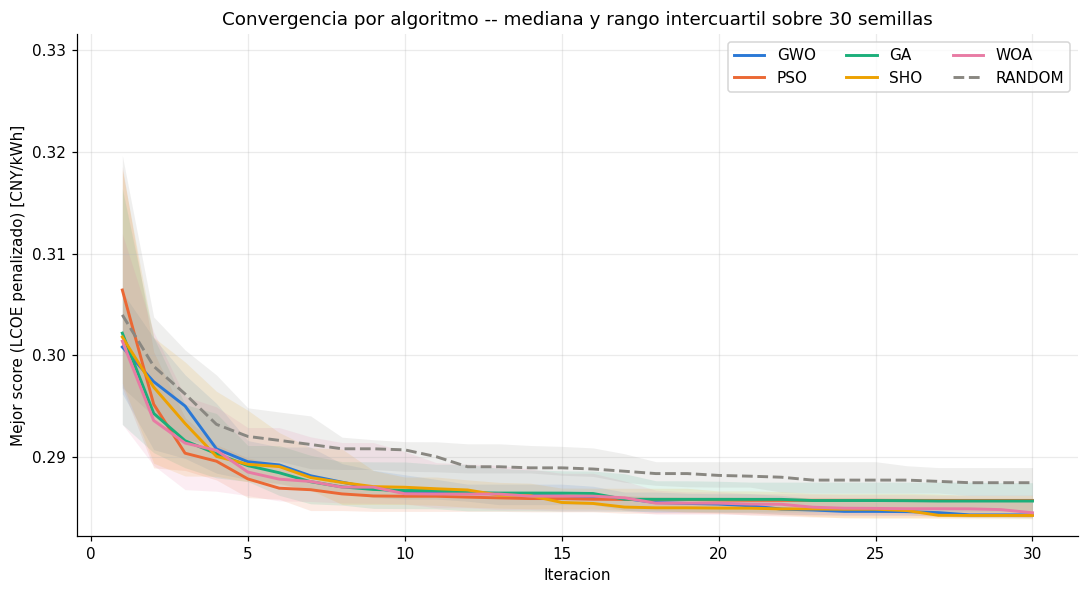

In [29]:
fig, ax = plt.subplots(figsize=(10, 5.5))

for nombre in ALGORITHM_ORDER:
    grupo = history[history["algorithm"] == nombre]
    if grupo.empty:
        continue
    resumen = (grupo.groupby("iteration")["best_score"]
               .agg(mediana="median",
                    q25=lambda s: s.quantile(0.25),
                    q75=lambda s: s.quantile(0.75))
               .reset_index())
    color = algorithm_color(nombre)
    ax.plot(resumen["iteration"], resumen["mediana"], label=nombre.upper(),
            color=color, linestyle=algorithm_linestyle(nombre), lw=1.9)
    ax.fill_between(resumen["iteration"], resumen["q25"], resumen["q75"],
                    color=color, alpha=0.13, linewidth=0)

ax.set_xlabel("Iteracion")
ax.set_ylabel("Mejor score (LCOE penalizado) [CNY/kWh]")
ax.set_title("Convergencia por algoritmo -- mediana y rango intercuartil sobre {} semillas"
             .format(len(SEMILLAS)))
ax.legend(ncol=3)

# La escala util es la de la region factible: si alguna semilla arranca infactible
# (score ~1e6) el eje completo queda inservible.
factibles = history.loc[history["best_score"] < 1.0, "best_score"]
if not factibles.empty:
    ax.set_ylim(factibles.min() * 0.995, factibles.quantile(0.995) * 1.02)

plt.tight_layout()
plt.show()

### 17.2 Distribucion de los scores finales y costo de computo

El **boxplot** muestra la dispersion completa: caja intercuartil, mediana, bigotes y
valores atipicos. Es la lectura honesta de "que pasa si corro este algoritmo una vez".

La **dispersion calidad-vs-tiempo** cruza lo que se obtiene con lo que cuesta. Con el
presupuesto de evaluaciones fijado, un algoritmo que tarda mas esta gastando ese tiempo
en su operador de movimiento, no en explorar mas: el eje horizontal mide sobrecarga
algoritmica, no esfuerzo de busqueda.

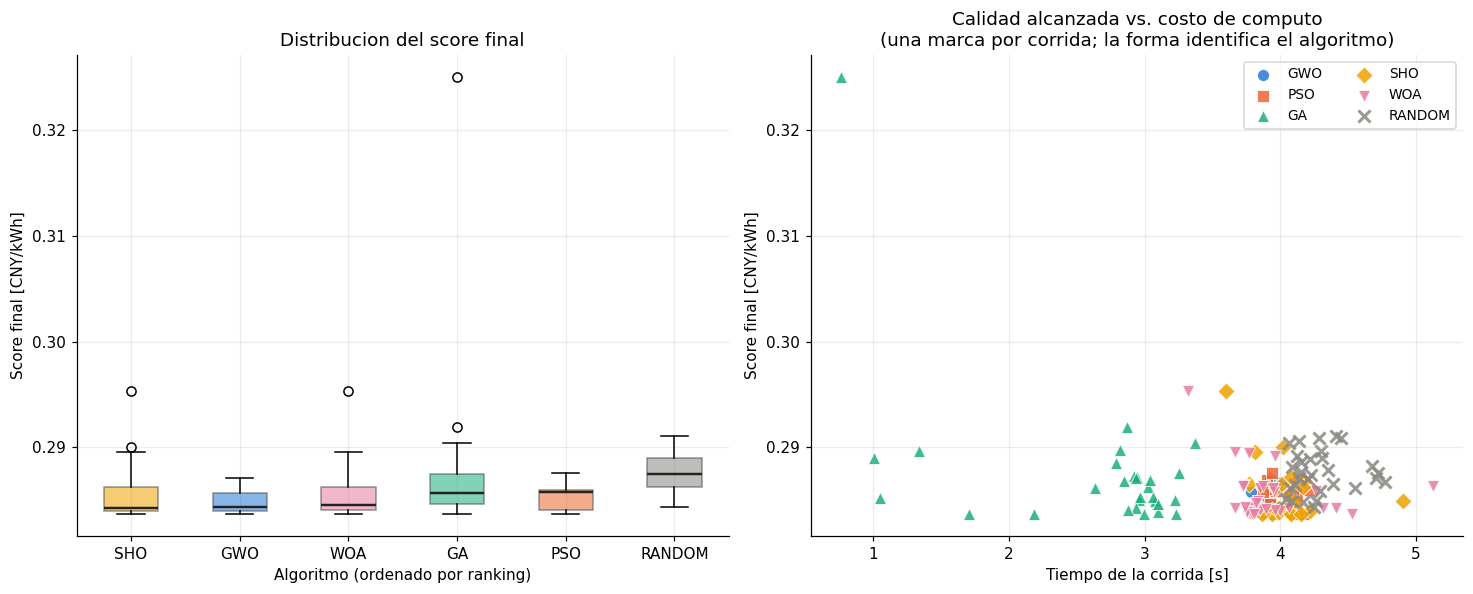

In [30]:
orden = [a for a in ranking["algorithm"].tolist()]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5))

# --- Boxplot de scores finales ------------------------------------------------
datos = [runs.loc[runs["algorithm"] == a, "score"].to_numpy() for a in orden]
caja = axes[0].boxplot(datos, tick_labels=[a.upper() for a in orden],
                       patch_artist=True, medianprops={"color": "#222222", "lw": 1.6})
for parche, nombre in zip(caja["boxes"], orden):
    parche.set_facecolor(algorithm_color(nombre))
    parche.set_alpha(0.55)
    parche.set_edgecolor("#444444")
axes[0].set_xlabel("Algoritmo (ordenado por ranking)")
axes[0].set_ylabel("Score final [CNY/kWh]")
axes[0].set_title("Distribucion del score final")

# --- Calidad vs tiempo --------------------------------------------------------
for nombre in ALGORITHM_ORDER:
    grupo = runs[runs["algorithm"] == nombre]
    if grupo.empty:
        continue
    marcador = algorithm_marker(nombre)
    # "x" es un marcador sin relleno: no admite edgecolor.
    extra = ({"linewidths": 2.0} if marcador == "x"
             else {"linewidths": 0.6, "edgecolor": "white"})
    axes[1].scatter(grupo["elapsed_s"], grupo["score"],
                    label=nombre.upper(), color=algorithm_color(nombre),
                    marker=marcador, s=62, alpha=0.85, **extra)
axes[1].set_xlabel("Tiempo de la corrida [s]")
axes[1].set_ylabel("Score final [CNY/kWh]")
axes[1].set_title("Calidad alcanzada vs. costo de computo\n"
                  "(una marca por corrida; la forma identifica el algoritmo)")
axes[1].legend(ncol=2, fontsize=9)

plt.tight_layout()
plt.show()

## 18. Inferencia estadística

Las ejecuciones se consideran muestras independientes. Se aplica Kruskal-Wallis como
contraste global y, si se informa el detalle, Mann-Whitney bilateral para los 15 pares
con corrección de Holm. $A_{12}$ de Vargha-Delaney informa la magnitud y dirección; sus
intervalos al 95 % se obtienen mediante 2.000 remuestreos bootstrap con semilla fija.

Estas pruebas describen variación algorítmica sobre **una sola instancia energética**;
no demuestran superioridad general sobre otras ubicaciones o formulaciones.


In [31]:
def vargha_delaney_a12(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    return float(sum(np.sum(value < b) + 0.5 * np.sum(value == b) for value in a)
                 / (len(a) * len(b)))


def bootstrap_a12_ci(a, b, n_boot=2000, seed=2024):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    rng = np.random.default_rng(seed)
    values = np.empty(n_boot)
    for i in range(n_boot):
        values[i] = vargha_delaney_a12(
            rng.choice(a, size=len(a), replace=True),
            rng.choice(b, size=len(b), replace=True),
        )
    return tuple(np.quantile(values, [0.025, 0.975]))


def _holm_bonferroni(p_values):
    m = len(p_values)
    order = np.argsort(p_values)
    adjusted = np.empty(m)
    running_max = 0.0
    for rank, index in enumerate(order):
        corrected = min((m - rank) * p_values[index], 1.0)
        running_max = max(running_max, corrected)
        adjusted[index] = running_max
    return adjusted


def independent_tests(runs, score_column="score"):
    algorithms = sorted(runs["algorithm"].unique())
    samples = {a: runs.loc[runs["algorithm"] == a, score_column].dropna().to_numpy()
               for a in algorithms}
    h_stat, omnibus_p = stats.kruskal(*(samples[a] for a in algorithms))
    rows = []
    for pair_index, (algo_a, algo_b) in enumerate(combinations(algorithms, 2)):
        a, b = samples[algo_a], samples[algo_b]
        u_stat, p_value = stats.mannwhitneyu(a, b, alternative="two-sided")
        a12 = vargha_delaney_a12(a, b)
        ci_low, ci_high = bootstrap_a12_ci(a, b, seed=2024 + pair_index)
        rows.append({"algoritmo_a": algo_a, "algoritmo_b": algo_b,
                     "U": u_stat, "p_value": p_value, "a12": a12,
                     "a12_ci_low": ci_low, "a12_ci_high": ci_high})
    table = pd.DataFrame(rows)
    table["p_value_holm"] = _holm_bonferroni(table["p_value"].to_numpy())
    table["significativo_alpha_0.05"] = table["p_value_holm"] < 0.05
    return {"H": float(h_stat), "p_value": float(omnibus_p),
            "n_algorithms": len(algorithms)}, table


omnibus, tests = independent_tests(runs)
print("Kruskal-Wallis: H={H:.4f}, p={p_value:.6g}".format(**omnibus))
display(tests)


Kruskal-Wallis: H=38.2918, p=3.29665e-07


,algoritmo_a,algoritmo_b,U,p_value,a12,a12_ci_low,a12_ci_high,p_value_holm,significativo_alpha_0.05
0,ga,gwo,631.0,7.617064e-03,0.298889,0.166667,0.435556,8.378771e-02,False
1,ga,pso,545.0,1.623750e-01,0.394444,0.247750,0.537778,1.000000e+00,False
2,ga,random,298.0,2.510128e-02,0.668889,0.528889,0.806667,2.510128e-01,False
3,ga,sho,587.0,4.358355e-02,0.347778,0.208889,0.495583,3.922519e-01,False
4,ga,woa,560.0,1.054699e-01,0.377778,0.236667,0.524444,8.437596e-01,False
5,gwo,pso,353.0,1.536672e-01,0.607778,0.459972,0.752250,1.000000e+00,False
6,gwo,random,78.0,3.964765e-08,0.913333,0.835556,0.970000,5.947148e-07,True
7,gwo,sho,451.0,9.941019e-01,0.498889,0.344417,0.657833,1.000000e+00,False
8,gwo,woa,386.0,3.478278e-01,0.571111,0.420000,0.715556,1.000000e+00,False
9,pso,random,130.0,2.316787e-06,0.855556,0.751111,0.941111,3.243501e-05,True


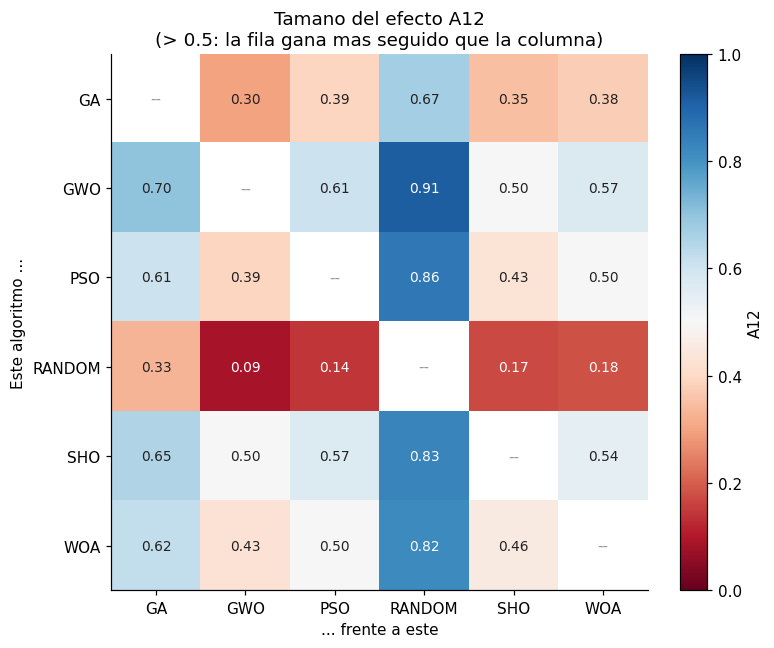

In [32]:
if not tests.empty:
    # Mapa de calor del tamano del efecto: cuanto domina la fila a la columna.
    algoritmos = sorted(runs["algorithm"].unique())
    matriz = pd.DataFrame(np.full((len(algoritmos), len(algoritmos)), np.nan),
                          index=algoritmos, columns=algoritmos)
    for _, fila in tests.iterrows():
        matriz.loc[fila["algoritmo_a"], fila["algoritmo_b"]] = fila["a12"]
        matriz.loc[fila["algoritmo_b"], fila["algoritmo_a"]] = 1.0 - fila["a12"]

    fig, ax = plt.subplots(figsize=(7.2, 6))
    im = ax.imshow(matriz.to_numpy(), cmap="RdBu", vmin=0.0, vmax=1.0)
    ax.set_xticks(range(len(algoritmos)), [a.upper() for a in algoritmos])
    ax.set_yticks(range(len(algoritmos)), [a.upper() for a in algoritmos])
    ax.set_xlabel("... frente a este")
    ax.set_ylabel("Este algoritmo ...")
    ax.set_title("Tamano del efecto A12\n"
                 "(> 0.5: la fila gana mas seguido que la columna)")
    ax.grid(False)

    for i, fila_nombre in enumerate(algoritmos):
        for j, col_nombre in enumerate(algoritmos):
            valor = matriz.iloc[i, j]
            if np.isfinite(valor):
                ax.text(j, i, "{:.2f}".format(valor), ha="center", va="center",
                        fontsize=9,
                        color="white" if abs(valor - 0.5) > 0.28 else "#222222")
            else:
                ax.text(j, i, "--", ha="center", va="center", color="#999999")

    fig.colorbar(im, ax=ax, label="A12", fraction=0.046)
    plt.tight_layout()
    plt.show()

## 19. Sensibilidad

Las dos restricciones que definen el dominio factible se barren una a la vez, desde el
escenario de replicacion, usando el **barrido exhaustivo** de la seccion 11 y no una
metaheuristica. La razon es metodologica: el barrido es determinista, de modo que las
curvas de sensibilidad no llevan ruido de semilla y la tendencia se lee sin ambiguedad.

**Limite de AGSR** -- es la restriccion que define el dominio factible y, segun §3.1 del
paper, la que fija el limite inferior del electrolizador. Relajarla deberia agrandar el
dominio y bajar el LCOE optimo.

**Carga minima del electrolizador** -- el paper usa 30%. Es lo que determina el
dimensionamiento de la bateria: cuanto mas alto el minimo, mas horas quedan por debajo y
mas bateria hace falta para sostener la operacion.

Cada valor barrido son 420 evaluaciones del modelo base, unos 3 segundos.

In [33]:
AGSR_MAX_VALUES = (0.10, 0.15, 0.20, 0.25, 0.30)
MIN_LOAD_RATIO_VALUES = (0.20, 0.30, 0.40, 0.50)

_SUMMARY_KEYS = ("evaluated", "feasible", "infeasible", "best_lcoe_cny_per_kwh",
                 "best_wind_mw", "best_electrolyzer_mw", "best_electrolyzer_cf")


def _sweep(hourly, config, parameter, values, build_config):
    rows = []
    for value in values:
        swept_config = build_config(config, value)
        results = run_grid_search(hourly, swept_config)
        summary = summarize_grid(results)

        row = {"parameter": parameter, "value": float(value)}
        for key in _SUMMARY_KEYS:
            row[key] = summary.get(key, float("nan"))
        row["feasible_share"] = (summary["feasible"] / summary["evaluated"]
                                 if summary["evaluated"] else 0.0)
        rows.append(row)
    return pd.DataFrame(rows)


def sweep_agsr_max(hourly, config, values=AGSR_MAX_VALUES):
    """Optimo y tamano del dominio factible en funcion del limite de AGSR."""
    def build_config(base, value):
        return base.replace(constraints=replace(base.constraints, agsr_max=value))
    return _sweep(hourly, config, "agsr_max", values, build_config)


def sweep_min_load_ratio(hourly, config, values=MIN_LOAD_RATIO_VALUES):
    """Optimo y tamano del dominio factible en funcion de la carga minima."""
    def build_config(base, value):
        return base.replace(electrolyzer=replace(base.electrolyzer,
                                                 min_load_ratio=value))
    return _sweep(hourly, config, "min_load_ratio", values, build_config)


t0 = time.perf_counter()
sens_agsr = sweep_agsr_max(hourly, ESCENARIO)
sens_carga = sweep_min_load_ratio(hourly, ESCENARIO)
print("Sensibilidad completa en {:.1f} s ({} barridos de {} configuraciones)".format(
    time.perf_counter() - t0,
    len(AGSR_MAX_VALUES) + len(MIN_LOAD_RATIO_VALUES),
    int(sens_agsr["evaluated"].iloc[0])))

print()
print("Limite de AGSR:")
display(sens_agsr[["value", "feasible", "feasible_share", "best_lcoe_cny_per_kwh",
                   "best_wind_mw", "best_electrolyzer_mw", "best_electrolyzer_cf"]])

print("Carga minima del electrolizador:")
display(sens_carga[["value", "feasible", "feasible_share", "best_lcoe_cny_per_kwh",
                    "best_wind_mw", "best_electrolyzer_mw", "best_electrolyzer_cf"]])

Sensibilidad completa en 25.5 s (9 barridos de 420 configuraciones)

Limite de AGSR:


,value,feasible,feasible_share,best_lcoe_cny_per_kwh,best_wind_mw,best_electrolyzer_mw,best_electrolyzer_cf
0,0.10,16,0.038095,0.328113,110.0,100.0,0.542218
1,0.15,47,0.111905,0.302827,140.0,100.0,0.563087
2,0.20,81,0.192857,0.287172,130.0,85.0,0.608232
3,0.25,116,0.276190,0.269440,180.0,95.0,0.587618
4,0.30,151,0.359524,0.255658,180.0,85.0,0.615268


Carga minima del electrolizador:


,value,feasible,feasible_share,best_lcoe_cny_per_kwh,best_wind_mw,best_electrolyzer_mw,best_electrolyzer_cf
0,0.2,81,0.192857,0.286722,130.0,85.0,0.609412
1,0.3,81,0.192857,0.287172,130.0,85.0,0.608232
2,0.4,75,0.178571,0.287626,130.0,85.0,0.603091
3,0.5,55,0.130952,0.295509,120.0,85.0,0.583367


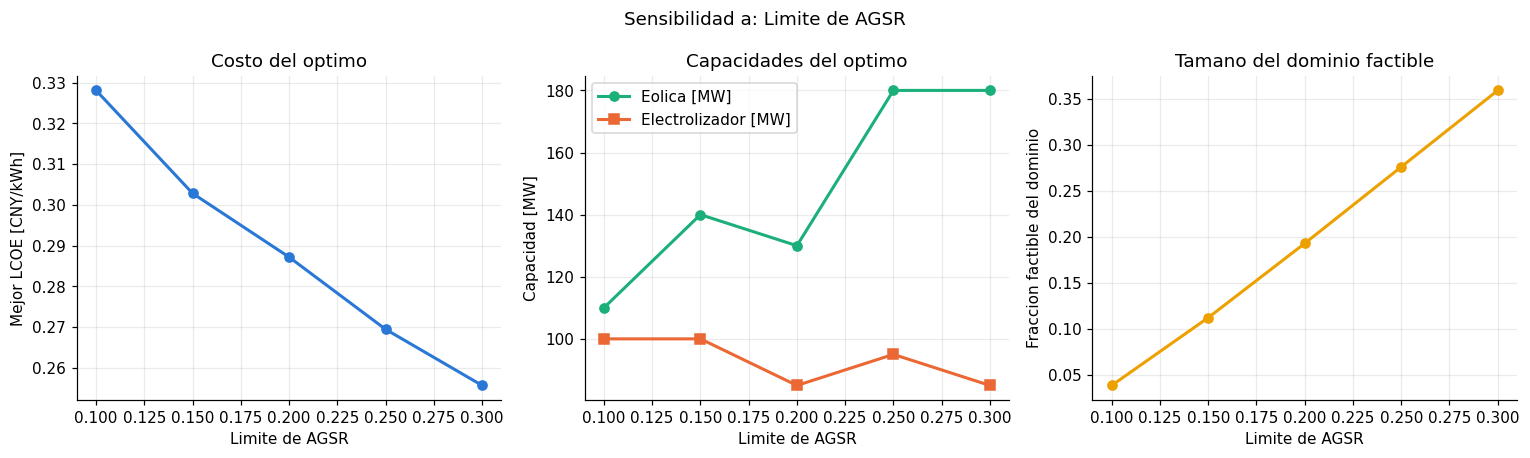

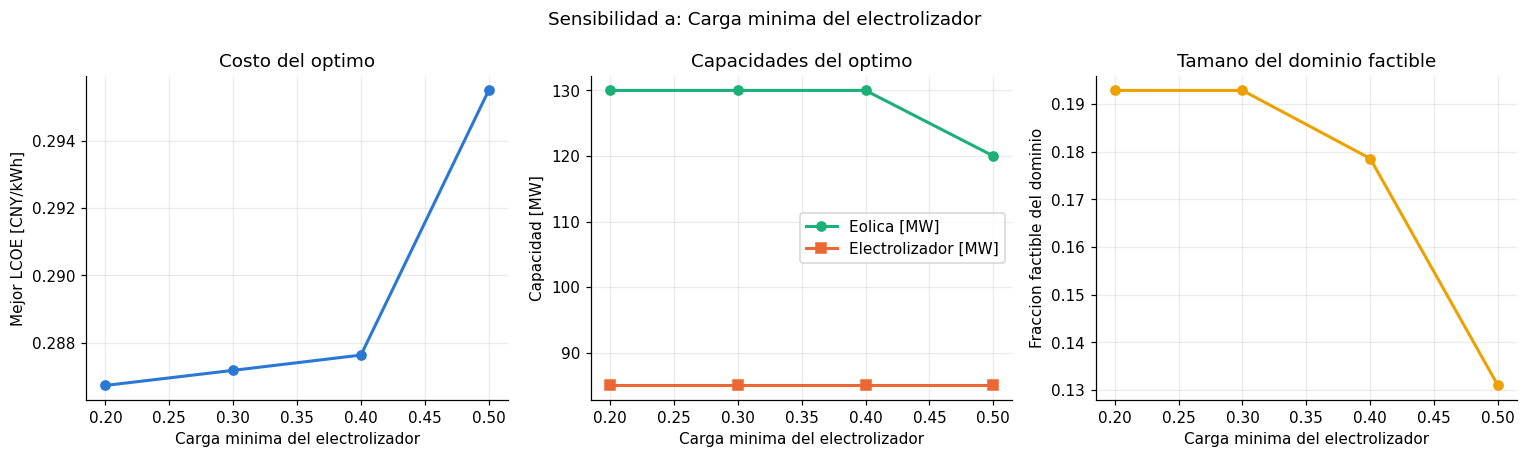

In [34]:
def plot_sensitivity_sweep(sweep, etiqueta):
    """Tres paneles de un eje cada uno: costo, capacidades y factibilidad.

    Ningun panel usa eje Y doble: donde hay mas de una magnitud se resuelve en
    paneles separados, cada uno con una sola escala.
    """
    datos = sweep.sort_values("value")
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

    axes[0].plot(datos["value"], datos["best_lcoe_cny_per_kwh"], marker="o",
                 color="#2a78d6", lw=2)
    axes[0].set_ylabel("Mejor LCOE [CNY/kWh]")
    axes[0].set_title("Costo del optimo")

    axes[1].plot(datos["value"], datos["best_wind_mw"], marker="o",
                 color="#1baf7a", lw=2, label="Eolica [MW]")
    axes[1].plot(datos["value"], datos["best_electrolyzer_mw"], marker="s",
                 color="#eb6834", lw=2, label="Electrolizador [MW]")
    axes[1].set_ylabel("Capacidad [MW]")
    axes[1].set_title("Capacidades del optimo")
    axes[1].legend()

    axes[2].plot(datos["value"], datos["feasible_share"], marker="o",
                 color="#eda100", lw=2)
    axes[2].set_ylabel("Fraccion factible del dominio")
    axes[2].set_title("Tamano del dominio factible")

    for ax in axes:
        ax.set_xlabel(etiqueta)

    fig.suptitle("Sensibilidad a: {}".format(etiqueta))
    plt.tight_layout()
    return fig


plot_sensitivity_sweep(sens_agsr, "Limite de AGSR")
plt.show()

plot_sensitivity_sweep(sens_carga, "Carga minima del electrolizador")
plt.show()

In [35]:
# Lectura cuantitativa de los dos barridos.
a_lo, a_hi = sens_agsr.iloc[0], sens_agsr.iloc[-1]
c_lo, c_hi = sens_carga.iloc[0], sens_carga.iloc[-1]

display(Markdown(
    "- **Limite de AGSR:** de {:.0%} a {:.0%}, el dominio factible pasa de {} a {} "
    "configuraciones ({:+d}) y el LCOE optimo {} en {:.4f} CNY/kWh. Coherente con que "
    "el paper (§3.1) fije el limite inferior del electrolizador precisamente por esta "
    "restriccion: si se puede vender mas a la red, hace falta menos electrolisis.\n"
    "- **Carga minima:** de {:.0%} a {:.0%} (el paper usa {:.0%}), el dominio factible "
    "cambia en {:+d} configuraciones y el LCOE optimo {} en {:.4f} CNY/kWh.".format(
        a_lo["value"], a_hi["value"], int(a_lo["feasible"]), int(a_hi["feasible"]),
        int(a_hi["feasible"] - a_lo["feasible"]),
        "baja" if a_hi["best_lcoe_cny_per_kwh"] < a_lo["best_lcoe_cny_per_kwh"] else "sube",
        abs(a_hi["best_lcoe_cny_per_kwh"] - a_lo["best_lcoe_cny_per_kwh"]),
        c_lo["value"], c_hi["value"], ESCENARIO.electrolyzer.min_load_ratio,
        int(c_hi["feasible"] - c_lo["feasible"]),
        "sube" if c_hi["best_lcoe_cny_per_kwh"] > c_lo["best_lcoe_cny_per_kwh"] else "baja",
        abs(c_hi["best_lcoe_cny_per_kwh"] - c_lo["best_lcoe_cny_per_kwh"]))
))

- **Limite de AGSR:** de 10% a 30%, el dominio factible pasa de 16 a 151 configuraciones (+135) y el LCOE optimo baja en 0.0725 CNY/kWh. Coherente con que el paper (§3.1) fije el limite inferior del electrolizador precisamente por esta restriccion: si se puede vender mas a la red, hace falta menos electrolisis.
- **Carga minima:** de 20% a 50% (el paper usa 30%), el dominio factible cambia en -26 configuraciones y el LCOE optimo sube en 0.0088 CNY/kWh.

## 20. Lectura automatizada de resultados

El resumen se genera exclusivamente desde las tablas de esta ejecución. Distingue
evaluaciones de diseños anuales, solicitudes repetidas y pasos horarios; evita afirmar
que el mejor valor continuo es un óptimo global o que un algoritmo es superior fuera de
esta instancia y presupuesto.


In [36]:
RESULTS_DIR = NOTEBOOK_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
reference_summary = pd.DataFrame([{
    "wind_step_mw": reference["wind_step_mw"],
    "evaluated": reference["evaluated"],
    "feasible": reference["feasible"],
    "elapsed_s": reference["elapsed_s"],
    "best_lcoe_cny_per_kwh": reference_best.lcoe_cny_per_kwh,
}])
experiment_metadata = pd.DataFrame([{
    "mode": MODO, "hours_main": len(hourly), "hours_sensitivity": len(hourly_full),
    "algorithms": len(ALGORITMOS), "replicates_per_algorithm": len(SEMILLAS),
    "population": ESCENARIO.metaheuristic.population,
    "iterations": ESCENARIO.metaheuristic.iterations,
    "requests_per_run": ESCENARIO.metaheuristic.evaluation_budget,
    "total_requests": total_sims, "main_hourly_steps_requested": total_sims * len(hourly),
}])
exports = {
    "base_grid.csv": base_grid,
    "validation_metrics_8760.csv": validacion,
    "validation_cases_8760.csv": validation_case_table,
    "validation_horizon_sensitivity.csv": horizon_sensitivity,
    "wind_height_sensitivity.csv": wind_height_sensitivity,
    "validation_evolution.csv": validation_evolution,
    "reference_grid_top10.csv": reference_top,
    "reference_grid_summary.csv": reference_summary,
    "algorithm_runs.csv": runs,
    "algorithm_summary.csv": ranking,
    "pairwise_tests.csv": tests,
    "sensitivity_agsr.csv": sens_agsr,
    "sensitivity_min_load.csv": sens_carga,
    "algorithm_hyperparameters.csv": tabla_hiperparametros,
    "best_design_horizon_sensitivity.csv": best_horizon_sensitivity,
    "experiment_metadata.csv": experiment_metadata,
}
for filename, table in exports.items():
    table.to_csv(RESULTS_DIR / filename, index=False)
pd.DataFrame({"replicate": SEMILLAS}).assign(
    stream_rule="SeedSequence([replica, crc32(algoritmo)])"
).to_csv(RESULTS_DIR / "replicate_seeds.csv", index=False)
print("Tablas exportadas:", len(exports) + 1, "en", RESULTS_DIR)

lineas = []
lineas.append("### Datos y reproduccion\n")
lineas.append("- Horizonte principal: **{} h**; sensibilidad: **{} h**.".format(
    len(hourly), len(hourly_full)))
lineas.append("- Recurso reconstruido: viento medio 50 m **{:.2f} m/s** (Li: 7.56) y "
              "GHI **{:.0f} kWh/m2** (Li: 1731).".format(
                  resource_main["wind_speed_50m_ms"], resource_main["annual_ghi_kwh_m2"]))
lineas.append("- La comparacion se reporta como reproduccion parcial bajo coordenadas y "
              "supuestos explicitamente declarados; no como prueba binaria.")

lineas.append("\n### Instancia base\n")
lineas.append("- Se evaluaron **{} configuraciones**; {} fueron factibles.".format(
    resumen_base["evaluated"], resumen_base["feasible"]))
lineas.append("- Mejor punto de la malla base: W={:.0f}, PV={:.0f}, E={:.0f} MW; "
              "LCOE={:.6f} CNY/kWh.".format(
                  base_best.wind_mw, base_best.pv_mw, base_best.electrolyzer_mw,
                  base_best.lcoe_cny_per_kwh))

lineas.append("\n### Instancia mixta continua-discreta\n")
lineas.append("- {:,} evaluaciones de disenos anuales (aprox. {:,} pasos horarios), "
              "30 ejecuciones independientes por algoritmo.".format(
                  total_sims, total_sims * len(hourly)))
lineas.append("- Ranking descriptivo por mediana e IQR: {}.".format(
    ", ".join("**{}** ({:.6f})".format(r.algorithm, r.median)
              for r in ranking.itertuples())))
lineas.append("- Mejor diseno estocastico observado: W={:.2f}, PV={:.2f}, E={:.0f}, B={:.0f} MW x {:.0f} h; "
              "LCOE={:.6f} CNY/kWh.".format(
                  mejor_corrida["wind_mw"], mejor_corrida["pv_mw"],
                  mejor_corrida["electrolyzer_mw"], mejor_corrida["battery_mw"],
                  mejor_corrida["battery_duration_h"], mejor_corrida["score"]))
lineas.append("- Kruskal-Wallis: H={:.3f}, p={:.4g}; {} de {} pares resultan significativos "
              "tras Holm.".format(omnibus["H"], omnibus["p_value"],
                  int(tests["significativo_alpha_0.05"].sum()), len(tests)))
lineas.append("- Estos resultados se limitan a esta instancia, presupuesto y conjunto de "
              "hiperparametros; no establecen superioridad general.")

display(Markdown("\n".join(lineas)))


Tablas exportadas: 17 en C:\Users\Luciano\Documents\GitHub\H2-HRES-METAHEURISTICS-METHODS\notebooks\results


### Datos y reproduccion

- Horizonte principal: **8760 h**; sensibilidad: **8784 h**.
- Recurso reconstruido: viento medio 50 m **7.09 m/s** (Li: 7.56) y GHI **1658 kWh/m2** (Li: 1731).
- La comparacion se reporta como reproduccion parcial bajo coordenadas y supuestos explicitamente declarados; no como prueba binaria.

### Instancia base

- Se evaluaron **420 configuraciones**; 81 fueron factibles.
- Mejor punto de la malla base: W=130, PV=70, E=85 MW; LCOE=0.287172 CNY/kWh.

### Instancia mixta continua-discreta

- 108,000 evaluaciones de disenos anuales (aprox. 946,080,000 pasos horarios), 30 ejecuciones independientes por algoritmo.
- Ranking descriptivo por mediana e IQR: **sho** (0.284304), **gwo** (0.284358), **woa** (0.284568), **ga** (0.285718), **pso** (0.285781), **random** (0.287517).
- Mejor diseno estocastico observado: W=141.70, PV=58.30, E=90, B=20 MW x 1 h; LCOE=0.283688 CNY/kWh.
- Kruskal-Wallis: H=38.292, p=3.297e-07; 4 de 15 pares resultan significativos tras Holm.
- Estos resultados se limitan a esta instancia, presupuesto y conjunto de hiperparametros; no establecen superioridad general.

## 21. Supuestos, limitaciones y referencias

1. **Coordenadas.** Se usa $(41{,}70,110{,}43)$ como punto aproximado de Damao Banner;
   Li et al. no publica la coordenada exacta. No se ajustó el sitio contra los resultados.
2. **Horizonte.** La reproducción elimina el 29 de febrero para respetar las 8.760 h
   declaradas; las 8.784 h se informan como sensibilidad.
3. **Viento.** La serie a 50 m es el caso principal y la extrapolación a 105 m debe
   interpretarse como sensibilidad. La curva real y las pérdidas de estela no se publican.
4. **Carga auxiliar.** `plant_load_ratio=0` porque su valor no está publicado.
5. **Batería.** El reparto de costo 30/70 entre potencia y energía es NPC-neutro a 1 h y
   permite interpretar la duración; es una extensión de esta tesis.
6. **LCOH.** Es el costo anualizado total dividido por la producción anual de H2, sin
   asignación de créditos por electricidad; se reporta como «LCOH según esta tesis».
7. **SHO.** La función `count_nos` del artículo original es ambigua; se implementa y
   documenta una regla de vecindad normalizada, sin presentarla como información publicada.
8. **Alcance estadístico.** Treinta ejecuciones sobre una instancia cuantifican
   variabilidad algorítmica, no rendimiento general sobre otros problemas.

### Referencias principales

- Li, R. et al. (2024). *Capacity optimization of a wind-photovoltaic-electrolysis-
  battery (WPEB) hybrid energy system for power and hydrogen generation*.
  International Journal of Hydrogen Energy, 52, 311--333.
- Li, R. et al. (2023). *Techno-economic analysis of a wind-photovoltaic-electrolysis-
  battery hybrid energy system for power and hydrogen generation*. Energy Conversion and
  Management, 281, 116854.
- Mirjalili, S., Mirjalili, S. M. y Lewis, A. (2014). *Grey Wolf Optimizer*.
- Dhiman, G. y Kumar, V. (2017). *Spotted hyena optimizer*.
- Mirjalili, S. y Lewis, A. (2016). *The Whale Optimization Algorithm*.
- NASA POWER: <https://power.larc.nasa.gov/>.


## 22. Resolución por fuerza bruta de la instancia mixta

La referencia de la sección 17.1 recorre $W$ cada 0,5 MW. Esta sección resuelve la instancia
mixta por fuerza bruta con una malla cincuenta veces más fina: se evalúan **todos** los 341
catálogos discretos efectivos ($n_E$, $B^P$, $h_B$) sobre **todos** los valores
$W\in\{0;\,0{,}01;\,\ldots;\,200\}$ MW, es decir, $20.001\times341=6.820.341$ diseños anuales,
sin muestreo ni poda.

Para que ese volumen sea abordable, el despacho `THRESHOLD` se reescribe vectorizado sobre la
malla: el bucle horario sigue siendo secuencial por el estado de carga, pero cada hora se
resuelve a la vez para todos los diseños de un bloque. El modelo físico y económico es el de
`simulate_mixed`. Antes de aceptar el resultado se contrasta contra ese simulador en una
muestra aleatoria, y el mejor diseño de cada uno de los diez mejores catálogos se recalcula con
él, verificando los cinco grupos de restricciones.

El resultado es el **óptimo exacto del dominio discretizado**. Como $W$ es continuo, la
distancia al óptimo continuo queda acotada por el paso de 0,01 MW. En modo rápido se usa un
paso de 1 MW exclusivamente como prueba de ejecución.

In [ ]:
def mixed_catalog_arrays(config):
    rows = np.array(list(mixed_catalog(config)), dtype=float)
    units = rows[:, 0].astype(int)
    return units, units * config.electrolyzer.unit_mw, rows[:, 1], rows[:, 2]


def simulate_mixed_grid(frame, config, wind_values, catalogs):
    """Réplica vectorizada de simulate_mixed sobre la malla W x catálogos.

    Devuelve matrices (len(wind_values), n_catálogos) de LCOE, AGSR y factibilidad.
    """
    units, electrolyzer_mw, battery_mw, duration_h = catalogs
    battery_mwh = battery_mw * duration_h
    wind_values = np.asarray(wind_values, dtype=float)
    pv_values = config.constraints.total_generation_capacity_mw - wind_values

    column = as_profile_cache(frame, config).wind_column
    per_unit = aggregate_wind_power_mw(frame[column].to_numpy(dtype=float), 1.0, config.wind)
    wind = per_unit[None, :] * wind_values[:, None]
    pv = pv_power_mw(frame["ghi_kwh_m2"].to_numpy(dtype=float),
                     frame["t2m_c"].to_numpy(dtype=float), pv_values[:, None], config.pv,
                     inverter_efficiency=config.converter.inverter_efficiency)
    renewable = wind.sum(axis=1) + pv.sum(axis=1)
    generation = wind + pv
    if config.converter.plant_load_ratio > 0:
        generation = generation * (1.0 - config.converter.plant_load_ratio)
    generation = np.ascontiguousarray(generation.T)

    eta_c = config.battery.eta_charge * config.converter.bidirectional_efficiency
    eta_d = config.battery.eta_discharge * config.converter.bidirectional_efficiency
    min_load_mw = config.electrolyzer.min_load_ratio * electrolyzer_mw
    has_battery = (battery_mw > 0.0) & (battery_mwh > 0.0)
    limit = config.constraints.grid_export_limit_mw

    shape = (len(wind_values), len(units))
    soc = np.zeros(shape)
    load_mwh = np.zeros(shape)
    grid_mwh = np.zeros(shape)
    # Mismas reglas y mismo orden de operaciones que _dispatch_core con THRESHOLD.
    for gen_t in generation:
        gen = gen_t[:, None]
        direct = gen >= min_load_mw
        load = np.where(direct, np.minimum(gen, electrolyzer_mw), 0.0)
        available = np.minimum(soc * eta_d, battery_mw)
        assisted = (~direct) & (battery_mw > 0.0) & (soc > 0.0) & (gen + available >= min_load_mw)
        discharge = np.where(assisted,
                             np.maximum(np.minimum(available, electrolyzer_mw - gen), 0.0), 0.0)
        load = np.where(assisted, np.minimum(gen + discharge, electrolyzer_mw), load)
        soc = np.where(discharge > 0.0, np.maximum(soc - discharge / eta_d, 0.0), soc)
        surplus = np.maximum(gen + discharge - load, 0.0)
        room = np.maximum((battery_mwh - soc) / eta_c, 0.0)
        charge = np.minimum(np.minimum(surplus, battery_mw), room)
        charge = np.where((surplus > 1e-12) & has_battery & (charge > 0.0), charge, 0.0)
        soc = soc + charge * eta_c
        surplus = surplus - charge
        exported = np.where(surplus > 1e-12, surplus, 0.0)
        if limit is not None:
            exported = np.minimum(exported, limit)
        load_mwh += load
        grid_mwh += exported

    agsr = grid_mwh / renewable[:, None]
    if config.economics.lcoe_energy_basis == "electrolyzer_only":
        served_mwh = load_mwh
    else:
        served_mwh = load_mwh + grid_mwh

    # El NPC es lineal en cada capacidad: basta con el aporte de 1 kW o 1 kWh.
    costs, economics = config.costs, config.economics
    per_kw = lambda cost: component_npc(1.0, 0.0, cost, economics)
    npc = (1000.0 * wind_values[:, None] * per_kw(costs.wind)
           + 1000.0 * pv_values[:, None] * per_kw(costs.pv)
           + 1000.0 * electrolyzer_mw * per_kw(costs.electrolyzer)
           + 1000.0 * battery_mw * per_kw(costs.battery)
           + 1000.0 * battery_mwh * component_npc(0.0, 1.0, costs.battery, economics)
           + hydrogen_storage_npc(config.electrolyzer.hydrogen_storage_kg, costs, economics))
    annualized = npc * crf(economics.real_discount_rate, economics.project_lifetime_years)
    with np.errstate(divide="ignore"):
        lcoe = np.where(served_mwh > 0, annualized / (served_mwh * 1000.0), np.inf)
    agsr_max = config.constraints.agsr_max
    feasible = np.maximum(agsr - agsr_max, 0.0) / agsr_max <= 1e-10
    return lcoe, agsr, feasible


def brute_force_mixed(frame, config, wind_step_mw, block_size=150):
    """Evalúa todos los catálogos discretos sobre todos los valores de la malla de W."""
    catalogs = mixed_catalog_arrays(config)
    total = config.constraints.total_generation_capacity_mw
    wind_values = np.linspace(0.0, total, int(round(total / wind_step_mw)) + 1)
    lcoe = np.empty((len(wind_values), len(catalogs[0])))
    agsr = np.empty_like(lcoe)
    feasible = np.empty(lcoe.shape, dtype=bool)
    starts = range(0, len(wind_values), block_size)
    started = time.perf_counter()
    for k, start in enumerate(starts, 1):
        rows = slice(start, start + block_size)
        lcoe[rows], agsr[rows], feasible[rows] = simulate_mixed_grid(
            frame, config, wind_values[rows], catalogs)
        if k % 20 == 0 or k == len(starts):
            print("  bloque {}/{}: W hasta {:.2f} MW, {:.0f} s".format(
                k, len(starts), wind_values[rows][-1], time.perf_counter() - started))
    return {"wind_step_mw": wind_step_mw, "wind_values": wind_values, "catalogs": catalogs,
            "lcoe": lcoe, "agsr": agsr, "feasible": feasible,
            "elapsed_s": time.perf_counter() - started}


FUERZA_BRUTA_PASO_W_MW = 0.01 if MODO == "completo" else 1.0
fuerza_bruta = brute_force_mixed(hourly, ESCENARIO, FUERZA_BRUTA_PASO_W_MW)
lcoe_factible = np.where(fuerza_bruta["feasible"], fuerza_bruta["lcoe"], np.inf)
print("Fuerza bruta: {:,} diseños ({:,} valores de W x {} catálogos), {:,} factibles, "
      "paso W={} MW, {:.1f} s".format(
          fuerza_bruta["lcoe"].size, len(fuerza_bruta["wind_values"]),
          len(fuerza_bruta["catalogs"][0]), int(fuerza_bruta["feasible"].sum()),
          FUERZA_BRUTA_PASO_W_MW, fuerza_bruta["elapsed_s"]))

In [ ]:
units_fb, electrolyzer_fb, battery_fb, duration_fb = fuerza_bruta["catalogs"]
wind_fb = fuerza_bruta["wind_values"]
perfiles_fb = as_profile_cache(hourly, ESCENARIO)


def simular_celda(i, j):
    """Diseño (W_i, catálogo j) evaluado con el simulador oficial."""
    return simulate_mixed(perfiles_fb, float(wind_fb[i]), int(units_fb[j]),
                          float(battery_fb[j]), float(duration_fb[j]), ESCENARIO)


# 1) Contraste de la réplica vectorizada en una muestra aleatoria de la malla.
rng_control = np.random.default_rng(2024)
control = []
for i, j in zip(rng_control.integers(0, len(wind_fb), 200),
                rng_control.integers(0, len(units_fb), 200)):
    oficial = simular_celda(i, j)
    control.append((abs(oficial.lcoe_cny_per_kwh / fuerza_bruta["lcoe"][i, j] - 1.0),
                    abs(oficial.agsr - fuerza_bruta["agsr"][i, j]),
                    oficial.feasible == fuerza_bruta["feasible"][i, j]))
control = np.array(control)
assert control[:, 0].max() < 1e-9 and control[:, 1].max() < 1e-9 and control[:, 2].all()
print("Contraste con simulate_mixed en 200 diseños: dif. relativa máx. LCOE={:.1e}, "
      "dif. máx. AGSR={:.1e}, factibilidad idéntica.".format(control[:, 0].max(),
                                                              control[:, 1].max()))

# 2) Mejor W de cada catálogo y certificación de los diez mejores con el simulador oficial.
columnas_fb = np.arange(len(units_fb))
mejor_fila = np.argmin(lcoe_factible, axis=0)
mejor_lcoe_catalogo = lcoe_factible[mejor_fila, columnas_fb]
fuerza_bruta_por_catalogo = pd.DataFrame({
    "n_electrolyzer_units": units_fb, "electrolyzer_mw": electrolyzer_fb,
    "battery_mw": battery_fb, "battery_duration_h": duration_fb,
    "wind_mw": wind_fb[mejor_fila], "agsr": fuerza_bruta["agsr"][mejor_fila, columnas_fb],
    "lcoe_cny_per_kwh": mejor_lcoe_catalogo, "has_feasible": np.isfinite(mejor_lcoe_catalogo),
}).sort_values("lcoe_cny_per_kwh").reset_index(drop=True)

top_catalogos = np.argsort(mejor_lcoe_catalogo)[:10]
certificados = [simular_celda(mejor_fila[j], j) for j in top_catalogos]
fuerza_bruta_top = pd.DataFrame([r.to_dict() for r in certificados])
assert fuerza_bruta_top["feasible"].all()
assert np.allclose(fuerza_bruta_top["lcoe_cny_per_kwh"], mejor_lcoe_catalogo[top_catalogos],
                   rtol=1e-9, atol=0.0)
optimo_fb = certificados[0]
assert optimo_fb.lcoe_cny_per_kwh <= reference_best.lcoe_cny_per_kwh * (1.0 + 1e-9)

# 3) ¿Qué pasa un paso de malla más allá del óptimo, dentro del mismo catálogo?
i_opt, j_opt = mejor_fila[top_catalogos[0]], top_catalogos[0]
if i_opt + 1 < len(wind_fb):
    vecino = simular_celda(i_opt + 1, j_opt)
    print("Un paso más (W={:.2f} MW): AGSR={:.6f}, factible={}, LCOE={:.6f} CNY/kWh.".format(
        vecino.wind_mw, vecino.agsr, vecino.feasible, vecino.lcoe_cny_per_kwh))

display(fuerza_bruta_top[["wind_mw", "pv_mw", "electrolyzer_mw", "battery_mw",
                          "battery_duration_h", "agsr", "lcoe_cny_per_kwh",
                          "lcoh_cny_per_kg"]])

# 4) Brecha de la referencia de malla y de las metaheurísticas respecto del óptimo.
def brecha_pct(lcoe):
    return (lcoe / optimo_fb.lcoe_cny_per_kwh - 1.0) * 100.0


comparacion_optimo = pd.DataFrame([
    {"fuente": "Fuerza bruta (paso {} MW)".format(FUERZA_BRUTA_PASO_W_MW),
     "wind_mw": optimo_fb.wind_mw, "lcoe_cny_per_kwh": optimo_fb.lcoe_cny_per_kwh},
    {"fuente": "Referencia de malla (paso {} MW)".format(reference["wind_step_mw"]),
     "wind_mw": reference_best.wind_mw, "lcoe_cny_per_kwh": reference_best.lcoe_cny_per_kwh},
    {"fuente": "Mejor corrida metaheurística ({})".format(mejor_corrida["algorithm"]),
     "wind_mw": mejor_corrida["wind_mw"], "lcoe_cny_per_kwh": mejor_corrida["score"]},
]).assign(brecha_pct=lambda t: brecha_pct(t["lcoe_cny_per_kwh"]))
display(comparacion_optimo)

brechas_fb = runs.assign(brecha_pct=brecha_pct(runs["score"]))
brecha_algoritmos = brechas_fb.groupby("algorithm")["brecha_pct"].agg(
    mejor="min", mediana="median", peor="max")
for tolerancia in (0.1, 0.5, 1.0):
    brecha_algoritmos["exito_{:.1f}pct".format(tolerancia)] = (
        brechas_fb.assign(ok=brechas_fb["brecha_pct"] <= tolerancia)
                  .groupby("algorithm")["ok"].mean())
brecha_algoritmos = brecha_algoritmos.reindex(
    [a for a in ALGORITHM_ORDER if a in brecha_algoritmos.index]).reset_index()
display(brecha_algoritmos)

display(Markdown(
    "**Óptimo por fuerza bruta (paso de W = {} MW):** W={:.2f}, PV={:.2f}, E={:.0f}, "
    "B={:.0f} MW por {:.0f} h; LCOE={:.6f} CNY/kWh; AGSR={:.6f}; LCOH según esta tesis="
    "{:.2f} CNY/kg.".format(
        FUERZA_BRUTA_PASO_W_MW, optimo_fb.wind_mw, optimo_fb.pv_mw, optimo_fb.electrolyzer_mw,
        optimo_fb.battery_mw, optimo_fb.battery_duration_h, optimo_fb.lcoe_cny_per_kwh,
        optimo_fb.agsr, optimo_fb.lcoh_cny_per_kg)))

fuerza_bruta_resumen = pd.DataFrame([{
    "wind_step_mw": FUERZA_BRUTA_PASO_W_MW, "wind_values": len(wind_fb),
    "catalogs": len(units_fb), "evaluated": fuerza_bruta["lcoe"].size,
    "feasible": int(fuerza_bruta["feasible"].sum()), "elapsed_s": fuerza_bruta["elapsed_s"],
    "control_max_rel_diff_lcoe": control[:, 0].max(),
    "control_max_abs_diff_agsr": control[:, 1].max(),
    "optimum_wind_mw": optimo_fb.wind_mw, "optimum_pv_mw": optimo_fb.pv_mw,
    "optimum_electrolyzer_mw": optimo_fb.electrolyzer_mw,
    "optimum_battery_mw": optimo_fb.battery_mw,
    "optimum_battery_duration_h": optimo_fb.battery_duration_h,
    "optimum_agsr": optimo_fb.agsr, "optimum_lcoe_cny_per_kwh": optimo_fb.lcoe_cny_per_kwh,
    "optimum_lcoh_cny_per_kg": optimo_fb.lcoh_cny_per_kg,
}])
exports_fb = {
    "brute_force_summary.csv": fuerza_bruta_resumen,
    "brute_force_top10.csv": fuerza_bruta_top,
    "brute_force_per_catalog.csv": fuerza_bruta_por_catalogo,
    "brute_force_comparison.csv": comparacion_optimo,
    "brute_force_algorithm_gaps.csv": brecha_algoritmos,
}
for filename, table in exports_fb.items():
    table.to_csv(RESULTS_DIR / filename, index=False)
print("Tablas de fuerza bruta exportadas:", len(exports_fb), "en", RESULTS_DIR)

In [ ]:
# Envolvente: el mejor LCOE factible entre los 341 catálogos para cada valor de W.
envolvente = lcoe_factible.min(axis=1)
hay_factible = np.isfinite(envolvente)
marcas = (
    ("Óptimo por fuerza bruta", optimo_fb.wind_mw, optimo_fb.lcoe_cny_per_kwh,
     "*", "#111111", 220),
    ("Referencia de malla (paso {} MW)".format(reference["wind_step_mw"]),
     reference_best.wind_mw, reference_best.lcoe_cny_per_kwh, "o", "#898781", 70),
    ("Mejor corrida ({})".format(mejor_corrida["algorithm"].upper()),
     mejor_corrida["wind_mw"], mejor_corrida["score"],
     algorithm_marker(mejor_corrida["algorithm"]),
     algorithm_color(mejor_corrida["algorithm"]), 70),
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ventana = 3.0
for ax, zoom in zip(axes, (False, True)):
    visible = hay_factible
    if zoom:
        visible = visible & (np.abs(wind_fb - optimo_fb.wind_mw) <= ventana)
    ax.plot(wind_fb[visible], envolvente[visible], color="#2a78d6", lw=1.0,
            label="Mejor LCOE factible para cada W")
    for etiqueta, w, lcoe, marcador, color, tamano in marcas:
        if zoom and abs(w - optimo_fb.wind_mw) > ventana:
            continue
        ax.scatter([w], [lcoe], marker=marcador, color=color, s=tamano, zorder=3,
                   label=etiqueta)
    ax.set_xlabel("Capacidad eólica W [MW]")
    ax.set_ylabel("LCOE [CNY/kWh]")
axes[0].set_title("Dominio completo de W")
axes[1].set_title("Entorno del óptimo (±{:.0f} MW)".format(ventana))
axes[1].legend(fontsize=8, loc="best")
fig.suptitle("Resolución por fuerza bruta: {:,} diseños, paso de W = {} MW".format(
    fuerza_bruta["lcoe"].size, FUERZA_BRUTA_PASO_W_MW), fontsize=11)
plt.tight_layout()
plt.show()